# 109 · Paper tables and figures

One trained run → every table and figure for the paper. Set `RUN` (env var `RUN` overrides). All of the code is in this notebook. **Part I** (the data, no model) builds one row per capture (`cap`); **Part II** (the run) one row per scored sample (`df`). Each plot's settings are the variables at the top of its cell. Sections are numbered from 1 in each part.

**Saved files.** Every table and figure is written to `TABLES` when its cell runs, numbered in notebook order: `NN_<name>.tex` (a table, with its shading and bold) or `NN_<name>.svg` + `NN_<name>.tex` (a figure environment that includes the SVG via `\\usepackage{svg}`; JPEG if an SVG can't be written). The numbers come from `ORDER` in the first cell; a new table or figure goes in there. Each has a LaTeX label without the number, so references survive renumbering: `tab_baselines` → `\label{tab:baselines}`, `fig_floor_map` → `\label{fig:floor_map}`. `ref(name)` gives the `\ref{...}`.

- **Part I, the data:** dataset statistics, coverage of the floor, average spectra (per speaker, box, object, laser row / column, position row / column), spectral distance over the floor and vs distance moved, how stable the empty box is over a session, damping (envelope, time to noise), spatial patterns (how many, their shapes), what an object changes in the modes (frequency, shape, amplitude), whether the four objects change the box differently, and the box's own resonances.
- **Part II, the run:**
  - **Tables 1a–c, in distribution:** one per box, VibroFormer only; rows = metrics, columns = the 6 in-distribution objects + their mean.
  - **Table 1d, baselines:** VibroFormer vs $f_\text{nn-vib}$ and $f_\text{nn-oracle}$, train and eval per metric, averaged over every object and box.
  - **Table 2, out of distribution** (one table per metric): only conditions the model never trained on at all, × box. That is unseen speaker, object, rotation, speckles (shifted lasers), lid on, and the broken cup; in distribution is the reference row. Unseen position comes with a `--dataset paper` run.
  - **Weight trend:** the cylinders (one shape, four masses) are all trained, so weight is a trend of performance vs mass, not a generalization test.
  - **Table 3, aux heads**, and the train/test sample counts behind Tables 1 and 2.
  - **Bar plots:** x = a table's columns, one bar per box, the value and ±std written on each bar with a ±1 std whisker, and `tr` / `te` (train / test samples) under each bar.
  - **Figures:** floor error map (per speaker), error vs distance to the speaker, IoU vs distance to the nearest training position, per speaker, object-head confidence, and predicted samples per category.

**Cells** show *mean ±std*. The mean is over splits (every split counts once); the std is over samples. Colour shades each cell from worst (white) to best (blue): along each row in Tables 1a–c (which object) and Table 2 (which box), down each column in Table 1d (which method). A row or column whose label has ↓ is lower-is-better. The best is in bold; "all" and "mean" are not compared. `to_latex` writes the same table for the paper (`\usepackage[table]{xcolor}`, `booktabs`, `multirow`, `array`).

**Metrics** (`THR` = 0.1): IoU = hard IoU of pred > THR vs true > 0.5. miss = no predicted pixel on the object. CoM err = distance between the predicted and true mask centroids, in % of the box.

**Which rows a run fills:** each eval split maps to its question (`dataset.PAPER_CATEGORY`). An object question (unseen object, object + rotation, weight, broken) only counts if the run never trained on that object. A run on an older dataset therefore fills only what it really held out. Unseen position, the cardboard wedge, unseen weight and broken need a run trained with `--dataset paper`.

In [1]:
import os, sys, json, hashlib, shutil, warnings
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from matplotlib.colors import BoundaryNorm, LinearSegmentedColormap, to_hex, to_rgb
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle
from PIL import Image
from scipy.ndimage import maximum_filter1d
from scipy.signal import butter, chirp, find_peaks, savgol_filter, sosfiltfilt
sys.path.insert(0, str(Path('..') / 'src8'))
import dataset as D
import score as S

RUN = os.environ.get('RUN', 's8-mag-nopose-imom-w-500ep')
EPOCH = None          # None: the run's last saved eval
THR = 0.1
SHADE = False         # True: tables shade each cell from worst (white) to best (blue); either way the best is in bold
ROOT = Path('..').resolve()
TABLES = ROOT / 'assets' / 'paper_tables' / RUN   # every table is also saved here as LaTeX, one <name>.tex per table, each time its cell runs
shutil.rmtree(TABLES, ignore_errors=True)   # always from scratch: a run of the notebook leaves exactly its own tables and figures
TABLES.mkdir(parents=True)                  # tables (.tex) and figures (.svg + .tex), numbered NN_<name> in the order of ORDER below
CACHE = ROOT / 'runs/_paper_cache/data'      # slow per-capture results (Part I)

BOXES = ('gastro', 'plastic', 'cardboard')
COLORS = dict(zip(BOXES, ('#2a78d6', '#eb6834', '#1baf7a')))   # one colour per box, everywhere

# every saved table (tab_*) and figure (fig_*), in notebook order: its file is TABLES/<NN>_<name>, NN = its place here.
# A new table or figure: add its name where it appears. The LaTeX label has no number (tab_x -> tab:x), so \ref{} survives renumbering
ORDER = [
    # Part I: the data
    'tab_dataset', 'tab_id_objects', 'fig_coverage',
    *[f'fig_power_by_{k}' for k in ('speaker', 'box', 'object', 'laser_row', 'laser_col', 'position_row', 'position_col')],
    'fig_lasers_one_capture_x', 'fig_lasers_one_capture_y',
    *[f'fig_spectral_distance_{o}_{k}' for o in ('vase', 'all') for k in ('photo', 'binned')],
    'fig_spectral_change_vs_distance', 'fig_empty_box_session', 'tab_empty_box_session', 'fig_envelope', 'fig_time_to_noise',
    'fig_mode_energy', 'fig_mode_shapes', 'fig_mode_changes', 'fig_objects_same_spot', 'fig_box_resonances', 'tab_box_resonances_summary', 'tab_box_resonances',
    # Part II: the run
    *[f'tab_id_{b}' for b in BOXES], *[f'fig_id_{m}' for m in ('iou', 'miss', 'com_err', 'com_err_x', 'com_err_y')], 'tab_id_samples', 'tab_baselines', 'tab_baselines_per_box',
    *[x for m in ('iou', 'miss', 'com_err') for x in (f'tab_ood_{m}', f'fig_ood_{m}')], 'tab_ood_samples', 'fig_weight_trend',
    'tab_aux_heads', *[f'fig_head_{h}' for h in ('object_acc', 'count_acc', 'com_head_err', 'area_err', 'orient_err', 'novelty')],
    'fig_floor_map', 'fig_speaker_residual_map', 'tab_speaker_residual', 'fig_speaker_distance', 'tab_speaker_distance',
    'fig_iou_vs_train_distance', 'fig_per_speaker', 'fig_speaker_train_eval', 'tab_speaker_train_eval', 'fig_box_train_eval', 'tab_box_train_eval', 'fig_object_confidence', 'fig_predictions',
]

def stem(name): return f'{ORDER.index(name):02d}_{name}'           # the file name, without extension
def label(name): return name.replace('_', ':', 1)                   # tab_baselines -> tab:baselines
def ref(name): return f'\\ref{{{label(name)}}}'
PALETTE = ('#2a78d6', '#eb6834', '#1baf7a', '#8c5bd6', '#d6452a', '#52514e')
INK, MUTED = '#0b0b0b', '#52514e'
BLUES = LinearSegmentedColormap.from_list('blues', ['#cde2fb', '#86b6ef', '#3987e5', '#256abf', '#104281'])
SEQ = LinearSegmentedColormap.from_list('seq', ['#f7fbff', '#cde2fb', '#86b6ef', '#3987e5', '#256abf', '#104281', '#061f45'])  # white -> navy
DIVERGE = LinearSegmentedColormap.from_list('diverge', ['#104281', '#3987e5', '#cde2fb', '#ffffff', '#fbd9c6', '#eb6834', '#8a3010'])
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': .25,
                     'axes.edgecolor': MUTED, 'xtick.color': MUTED, 'ytick.color': MUTED, 'font.size': 10})

def tex(s):
    """the unicode the tables use, as LaTeX"""
    return s.replace('↑', '$\\uparrow$').replace('↓', '$\\downarrow$').replace('°', '$^\\circ$').replace('·', '$\\cdot$').replace('±', '$\\pm$')

def save_table(t, name, caption=None, precision=3):
    """write a plain table to TABLES/<NN>_<name>.tex (label tab:...) and return it, so a cell can end with save_table(...) to show it"""
    st = t.style.format(precision=precision, na_rep='—', escape='latex').format_index(escape='latex', axis=0).format_index(escape='latex', axis=1)
    (TABLES / f'{stem(name)}.tex').write_text(tex(st.to_latex(hrules=True, caption=caption, label=label(name), multirow_align='t', multicol_align='c')))
    return t

def save_fig(name, caption, fig=None):
    """the current figure as TABLES/<NN>_<name>.svg (JPEG if SVG fails), plus <NN>_<name>.tex: a figure environment that includes it
    (label fig:...). An SVG needs \\usepackage{svg} (and Inkscape) in the paper"""
    fig = fig or plt.gcf()
    try:
        fig.savefig(TABLES / f'{stem(name)}.svg', bbox_inches='tight')
        include = f'\\includesvg[width=\\linewidth]{{{stem(name)}}}'
    except Exception:
        (TABLES / f'{stem(name)}.svg').unlink(missing_ok=True)
        fig.savefig(TABLES / f'{stem(name)}.jpg', bbox_inches='tight', dpi=200, pil_kwargs={'quality': 95})
        include = f'\\includegraphics[width=\\linewidth]{{{stem(name)}.jpg}}'
    (TABLES / f'{stem(name)}.tex').write_text(f'\\begin{{figure}}[t]\n\\centering\n{include}\n'
                                             f'\\caption{{{tex(caption)}}}\n\\label{{{label(name)}}}\n\\end{{figure}}\n')

/home/ethantu/workspace/good-vibrations/.venv/lib/python3.12/site-packages/torch/cuda/__init__.py:1061: UserWarning: Can't initialize NVML
  raw_cnt = _raw_device_count_nvml()
Failed to load CPU gemm_4bit_forward from kernels-community: No module named 'kernels'. Please make sure you already `pip install kernels` and the kernels >= 0.11.1


## Part I · The data
Before any model: what was recorded, how stable it is, and what moving an object does to the box's vibration. Everything is built from the run's own dataset (`RUN` above): its splits, its train / eval positions, its speakers. The helpers every plot shares are in the first cell below; each plot's code and settings are in its own cell.

**Setup**
- Three boxes (gastro = steel gastronorm tray, plastic, cardboard). Each has a 10×10 grid of laser spots on the bottom wall and an overhead camera. A speaker plays a log chirp (100 → 1000 Hz, 1 s), and the camera tracks every laser spot's speckle shift at 2500 fps for 1.3 s.
- One **capture** = one object layout at one position, played by one speaker. Each position is recorded once per speaker (1/3/5/7; gastro has no 5).
- **Objects**: the four single-object in-distribution splits: candle, cube, soap dispenser, vase. A plot uses all four unless its cell names one. The empty-box captures (layouts `empty-box-*`) are spread over each session.

**Definitions** (as in nb99)
- `X(l, f, c)`: complex FFT of the shift of laser `l` (100), axis `c` (x, y), at `f` ∈ 100–1000 Hz (1170 bins of 0.77 Hz; whole-capture Hann window).
- `x(l, j, c) = mean_{f ∈ band j} 20 log10 |X|`: dB in 117 bands of 10 bins (7.7 Hz).
- **Spectral distance**: `D_spec(a, b) = sqrt(mean_{l,j,c} (x_a − x_b)²)`, in dB.
- **Level**: `L(f) = 10 log10 mean_{l,c} |X|²`.
- **Repeat noise**: `D_spec` of two back-to-back captures of the empty box (same layout and speaker). Nothing moved, so this is the floor every change is read against.
- **Position distance**: `D_pos(a, b) = |com_a − com_b| / sqrt(H·W)`: how far the object moved, as a fraction of the box (CoM in the overhead crop).

**Averaging rule** (every plot): spectra are only compared within one *(object, speaker)* group. Each group is computed on its own; curves are the **mean over groups**, and bands are **± the pooled within-group std** (`sqrt(mean variance)`), so the difference between speakers or objects never widens a band. By default every speaker is used; a cell can set one. Each box has one colour. The two caveats: a mean over objects can hide one object that behaves differently (set the cell's object to check), and where a band is a std *between* groups instead, the plot says so.

Slow parts (FFTs, envelopes, SVDs) are cached in `runs/_paper_cache/data/` and `runs/<run>/scores/`. The first run of the section takes ~5 min; after that it takes seconds.

In [2]:
# used by every plot in Part I. objects = split names (None: OBJECTS), speakers = numbers (None: all)
OBJECTS = ('candle', 'cube', 'soap-dispenser', 'vase')   # the four single-object in-distribution splits
FLOOR = {'gastro': (.172, .126, .897, .832), 'plastic': (.183, .149, .847, .802), 'cardboard': (.134, .079, .948, .860)}  # floor (left, top, right, bottom) in 02_cropped_overhead
F = np.arange(131, 1301) / 1.3                  # the 1170 FFT bins of 04_ffts: 100-1000 Hz, 0.77 Hz apart
FB = F.reshape(117, 10).mean(1)                 # band centres: 10 bins (7.7 Hz) a band, as nb99

def as_list(v, default=()): return list(default if v is None else [v] if isinstance(v, (str, int)) else v)

def cached(name, keys, fn):
    """fn(), pickled under CACHE, keyed on name + keys (the capture dirs it reads)"""
    f = CACHE / f"{name}_{hashlib.sha1('|'.join(map(str, keys)).encode()).hexdigest()[:16]}.pkl"
    if f.exists(): return pd.read_pickle(f)
    out = fn()
    f.parent.mkdir(parents=True, exist_ok=True); pd.to_pickle(out, f)
    return out

def load_captures(run):
    """one row per capture of the run's dataset: box, split, layout, position, speaker, time t, CoM (row, col px of
    02_cropped_overhead), crop size H x W, dir, and set = train / eval (the run's positions). Cached"""
    f = ROOT / 'runs' / run / 'scores' / 'paper_captures.pkl'
    if f.exists(): return pd.read_pickle(f)
    a = json.loads((ROOT / 'runs' / run / 'args.json').read_text())
    splits = D.DATASETS[a['dataset']](a['test_size'], None if 'all' in a['speakers'] else tuple(a['speakers']))
    tr = pd.read_csv(ROOT / 'runs' / run / 'positions/train.txt', sep=' ', names=['experiment', 'position_id'])
    train = set(zip(tr.experiment, tr.position_id))
    ev = {(f'{t.parent.name}/{t.stem}', e, int(p)) for t in (ROOT / 'runs' / run / 'positions/eval').glob('*/*.txt') for e, p in (l.split() for l in t.read_text().splitlines() if l.strip())}
    rows = []
    for exp in sorted({s['experiment'] for s in splits.values()}):
        mine = {k: s for k, s in splits.items() if s['experiment'] == exp}
        for d in sorted((D.EXPERIMENTS / exp / 'samples').iterdir()):
            if not (d / 'metadata.jsonl').exists(): continue
            m = D.load_meta(d)
            pos, spk = m['position_id'], m['speaker']
            k = next((k for k, s in mine.items() if m['layout'] in s['layouts'] and s['keep'](pos) and (s['speakers'] is None or spk in s['speakers'])), None)
            if k is None: continue
            com = m.get('avg_com') or [np.nan, np.nan]
            rows.append(dict(box=k.split('/')[0], split=k.split('/')[1], layout=m['layout'], experiment=exp, position_id=pos, speaker=spk,
                             t=pd.Timestamp(m['timestamp']), com_r=com[0], com_c=com[1], H=m['crop_overhead_shape'][0], W=m['crop_overhead_shape'][1],
                             dir=d, set='train' if (exp, pos) in train else 'eval' if (k, exp, pos) in ev else None))
    out = pd.DataFrame(rows)
    f.parent.mkdir(parents=True, exist_ok=True); out.to_pickle(f)
    return out

cap = load_captures(RUN)

def groups(box, objects=None, speakers=None):
    """{(object, speaker): its captures} of one box. Spectra are only ever compared within one group"""
    c = cap[(cap.box == box) & cap.split.isin(as_list(objects, OBJECTS))]
    if speakers is not None: c = c[c.speaker.isin(as_list(speakers))]
    return {k: g.reset_index(drop=True) for k, g in c.groupby(['split', 'speaker'])}

def empties(box, speaker): return cap[(cap.box == box) & (cap.split == 'empty-box') & (cap.speaker == speaker)].reset_index(drop=True)

def back_to_back(e):
    """index pairs of back-to-back captures in e (the same empty-box layout)"""
    return [(i, j) for ix in e.groupby('layout').indices.values() for k, i in enumerate(ix) for j in ix[k + 1:]]

SPEC = {}
def spectra(rows):
    """per capture, in rows' order: x = 20 log10 |X| in 117 bands (N, 100 lasers, 117, 2 axes), and the level
    L = 10 log10 mean_{l,c} |X|^2 per band (N, 117). Cached on disk per experiment"""
    def one(d):
        A = np.abs(D.load_fft(d).numpy())   # (100 lasers, 1170, 2 axes)
        return (20 * np.log10(A + 1e-12)).reshape(100, 117, 10, 2).mean(2).astype(np.float16), (10 * np.log10((A ** 2).mean((0, 2)).reshape(117, 10).mean(1))).astype(np.float32)
    for exp, g in rows.groupby('experiment'):
        f = CACHE / f'spectra_{exp}.npz'
        if exp not in SPEC:
            z = np.load(f) if f.exists() else None
            SPEC[exp] = {} if z is None else {n: (x, l) for n, x, l in zip(z['names'], z['x'], z['L'])}
        todo = [d for d in dict.fromkeys(g.dir) if d.name not in SPEC[exp]]
        if todo:
            with ThreadPoolExecutor(16) as ex: SPEC[exp].update(zip((d.name for d in todo), ex.map(one, todo)))
            v = list(SPEC[exp].values())
            f.parent.mkdir(parents=True, exist_ok=True); np.savez(f, names=list(SPEC[exp]), x=np.stack([a for a, _ in v]), L=np.stack([b for _, b in v]))
    v = [SPEC[e][d.name] for e, d in zip(rows.experiment, rows.dir)]
    return np.stack([a for a, _ in v]), np.stack([b for _, b in v])

def d_spec(A, B):
    """D_spec (dB) between every capture of A and every capture of B, (len(A), len(B))"""
    A, B = A.reshape(len(A), -1).astype(np.float32), B.reshape(len(B), -1).astype(np.float32)
    return np.sqrt(np.maximum((A ** 2).sum(1)[:, None] + (B ** 2).sum(1)[None] - 2 * A @ B.T, 0) / A.shape[1])

def noise(box, speaker):
    """repeat noise: D_spec of every back-to-back empty-box pair of one speaker"""
    e = empties(box, speaker)
    dd = d_spec(*[spectra(e)[0]] * 2)
    return np.array([dd[i, j] for i, j in back_to_back(e)])

def pool(means, variances):
    """mean over groups ± pooled within-group std"""
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', RuntimeWarning)
        return np.nanmean(np.stack(means), 0), np.sqrt(np.nanmean(np.stack(variances), 0))

def photo(ax, box):
    """the box's first empty-box overhead photo (02_cropped_overhead)"""
    d = cap[(cap.box == box) & (cap.split == 'empty-box')].sort_values('t').dir.iloc[0]
    ax.imshow(Image.open(d / 'image/02_cropped_overhead.png').convert('RGB')); ax.set(xticks=[], yticks=[]); ax.grid(False)

def floor_frac(g, box):
    """(row, col) of each capture's CoM as a fraction of the floor"""
    l, t, r, b = FLOOR[box]
    return np.stack([(g.com_r / g.H - t) / (b - t), (g.com_c / g.W - l) / (r - l)], 1)

def blues(n): return [to_hex(SEQ(v)) for v in np.linspace(.3, 1, n)]   # n ordered lines, light -> dark

### 1 Dataset statistics
What the run's dataset holds. One row per split, grouped by the question it answers (`dataset.PAPER_CATEGORY`); one column group per box.
- **samples** = captures (one position × one speaker), **positions** = object placements, **speakers** = how many speakers recorded it.
- — = the box has no such split.
- The last row is the box's total (positions and speakers counted once).

Splits are rows rather than columns because each box has its own set (16–27, e.g. biscoff only in cardboard): as columns the table would be ~40 wide and mostly empty. The same table is written as LaTeX to `paper_tables/table0_dataset.tex`.

In [3]:
GROUP = {'id': 'in distribution', 'weight': 'weight (trained)', 'rotated': 'rotated (trained)', 'unseen-speaker': 'unseen speaker', 'unseen-object': 'unseen object',
         'unseen-rotation': 'unseen rotation', 'unseen-object-rotation': 'unseen object + rotation', 'unseen-laser': 'unseen speckles', 'lid': 'lid on',
         'broken': 'broken object', 'control': 'control', 'empty': 'empty box', 'other': 'other (in no table)'}
STATS = ['samples', 'positions', 'speakers']
c = cap.assign(group=cap.split.map(D.PAPER_CATEGORY).fillna('other').where(cap.split != 'empty-box', 'empty'))
stats = c.groupby(['group', 'split', 'box']).agg(samples=('dir', 'size'), positions=('position_id', 'nunique'), speakers=('speaker', 'nunique')).unstack('box')
stats = stats.swaplevel(axis=1)[[(b, s) for b in BOXES for s in STATS]]
stats[('all boxes', 'samples')] = stats.xs('samples', axis=1, level=1).sum(axis=1)
stats = stats.reindex(sorted(stats.index, key=lambda k: (list(GROUP).index(k[0]), k[1])))
stats.index = pd.MultiIndex.from_tuples([(GROUP[g], s) for g, s in stats.index], names=['question', 'split'])
total = {(b, 'samples'): (cap.box == b).sum() for b in BOXES} | {(b, 'positions'): cap[cap.box == b].position_id.nunique() for b in BOXES} \
      | {(b, 'speakers'): cap[cap.box == b].speaker.nunique() for b in BOXES} | {('all boxes', 'samples'): len(cap)}
stats.loc[('total', ''), :] = pd.Series(total)
stats.columns.names = [None, None]
table = stats.style.format('{:.0f}', na_rep='—')
latex = table.to_latex(hrules=True, multirow_align='t', multicol_align='c', clines='skip-last;data',
                                                       column_format='ll' + '|ccc' * len(BOXES) + '|c', caption='Dataset: samples, positions and speakers per split and box', label=label('tab_dataset'))
(TABLES / f"{stem('tab_dataset')}.tex").write_text(latex.replace('\\cline{1-12}\n\\bottomrule', '\\bottomrule'))
table

**Reading:**
- 16 640 captures in all: 3 728 gastro, 5 702 plastic, 7 210 cardboard. 1 231 / 1 416 / 1 800 positions, 4 speakers each (gastro: 1/3/7, and speaker 4 only for the unseen-speaker split).
- The four single objects are the bulk: ~250–300 positions per box each, about 70% of all captures. The cardboard box also has the most multi-object and cylinder data (cube + vase 100 positions, cylinders 34–50 each, against 2–9 in gastro and plastic).
- Every out-of-distribution question rests on a small set: 5–15 positions (lid, broken cup, unseen objects, speckles); only plastic's coffee pot is large (86). Unseen speaker is 35 / 40 / 10 positions with one speaker.
- Each box has its own questions: rotations only in cardboard, speckles only in plastic and cardboard, sideways soap only in gastro and plastic. Table 2's cells are therefore not all filled for every box.

**In-distribution objects only** (the six splits of Table 1): the first row lists each box's speakers, then one row per object with its number of positions, and their total (every position is recorded by every speaker listed). Written as LaTeX to `paper_tables/table0_id.tex`.

In [4]:
ID_OBJECTS = ['cube', 'candle', 'soap-dispenser', 'vase', 'two-cubes', 'cube-vase']
idc = cap[cap.split.isin(ID_OBJECTS)]
ids = pd.DataFrame({b: [', '.join(map(str, sorted(idc[idc.box == b].speaker.unique())))] + [idc[(idc.box == b) & (idc.split == o)].position_id.nunique() for o in ID_OBJECTS]
                    for b in BOXES}, index=['speakers'] + ID_OBJECTS)
ids.loc['total'] = ids.loc[ID_OBJECTS].sum()
(TABLES / f"{stem('tab_id_objects')}.tex").write_text(ids.style.to_latex(hrules=True, column_format='l' + 'c' * len(BOXES), caption='In-distribution objects: speakers and positions per box', label=label('tab_id_objects')))
ids

,gastro,plastic,cardboard
speakers,"1, 3, 7","1, 3, 5, 7","1, 3, 5, 7"
cube,246,252,279
candle,260,253,289
soap-dispenser,245,296,272
vase,268,256,257
two-cubes,72,80,98
cube-vase,49,49,100
total,1140,1186,1295


**Reading:**
- Gastro was recorded with speakers 1, 3, 7; plastic and cardboard with 1, 3, 5, 7.
- 1 140 / 1 186 / 1 295 in-distribution positions in total (gastro / plastic / cardboard).
- The four single objects are balanced within each box (245–296 positions each); two-cubes and cube + vase are 3–5× smaller, except cardboard's cube + vase (100 positions).
- Gastro's cube leaves out the 35 positions kept aside for the unseen-speaker test (they are in `cube-unseen-speaker-baseline`).

### 2 Coverage: where the objects were put
Every position's true outline (`03_smask` > 0.5) and centre of mass, drawn on the box's whole first empty-box overhead photo (`02_cropped_overhead`, not cropped further). Train positions are in the box's colour, eval positions in black. A position counts once, because its mask is the same for every speaker. Set `box` and `obj` at the top of the cell (default: the cardboard cube).

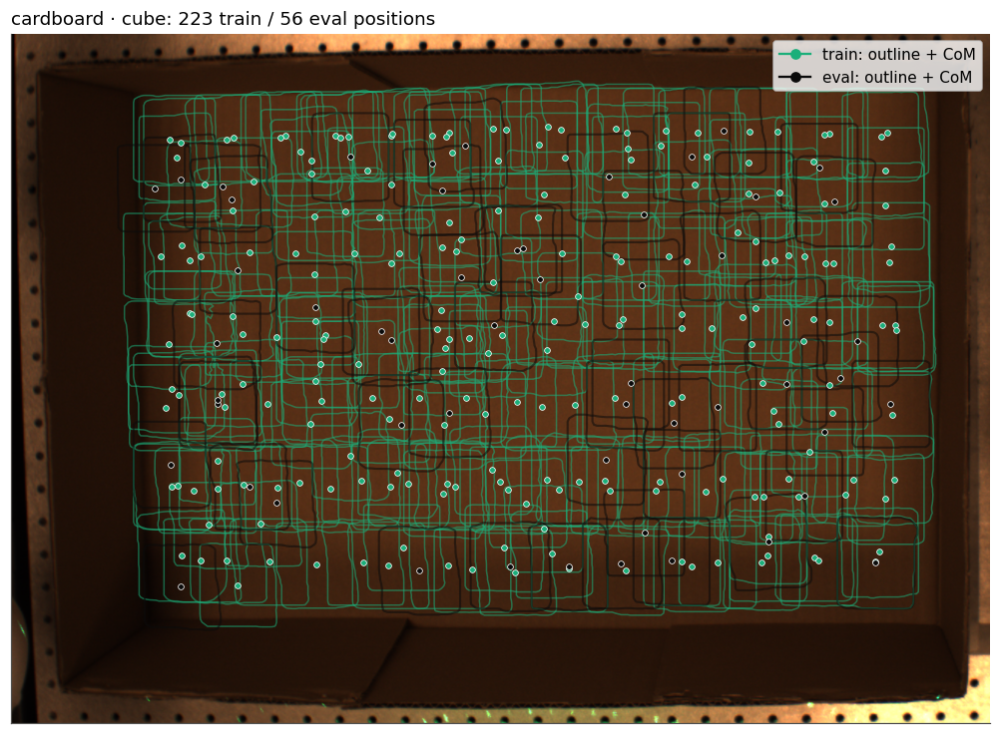

In [5]:
box, obj = 'cardboard', 'cube'
g = cap[(cap.box == box) & (cap.split == obj)].drop_duplicates(['experiment', 'position_id'])   # a mask is the same for every speaker
fig, ax = plt.subplots(figsize=(9, 7), constrained_layout=True)
photo(ax, box)
for s, col, lw in (('train', COLORS[box], 1), ('eval', INK, 1.4)):
    h = g[g.set == s]
    for d in h.dir:
        m = np.asarray(Image.open(d / 'image/03_smask.png').convert('L').reduce(4), np.float32) / 255   # 1/4 resolution
        ax.contour((np.arange(m.shape[1]) + .5) * 4, (np.arange(m.shape[0]) + .5) * 4, m, [.5], colors=[col], linewidths=lw, alpha=.55)
    ax.scatter(h.com_c, h.com_r, s=14, c=col, edgecolors='white', linewidths=.5, zorder=3)
ax.set_title(f"{box} · {obj}: {(g.set == 'train').sum()} train / {(g.set == 'eval').sum()} eval positions", loc='left')
ax.legend(handles=[Line2D([], [], c=COLORS[box], marker='o', label='train: outline + CoM'), Line2D([], [], c=INK, marker='o', label='eval: outline + CoM')], loc='upper right');
save_fig('fig_coverage', f'Coverage: every {box} {obj} position, true outline and centre of mass (train vs eval).')

**Reading:**
- The cardboard cube covers the whole floor evenly (223 train / 56 eval positions), up to about one cube width from the walls.
- Its footprint is about a tenth of the floor's width, so neighbouring outlines overlap: the grid is denser than the cube is wide.
- The eval positions are spread among the train positions, not in a separate region: random held-out positions test interpolation. Only the `unseen-position` block of a `--dataset paper` run tests new territory.

### 3 Average spectra
Power `P(f)` = mean over the 100 lasers and both axes of `10 log10 |X(l, f, c)|²` (dB), in 7.7 Hz bands: one curve per capture. Line = mean over captures, band = ± std over captures. `power_vs(by, box, objects, speakers)` draws one line per value of `by`:
- `'speaker'`, `'box'`, `'object'`;
- `'laser_row'` / `'laser_col'`: the lasers of one row or column of the 10 × 10 grid on the wall (laser `l` at row `l // 10`, column `l % 10`);
- `'pos_row'` / `'pos_col'`: where the object sits on the floor, in 8 equal strips (row 7 = next to the laser wall; strips with < 5 captures are dropped).

Rows and columns are drawn in shades of blue, light → dark, so their order is visible.

**Plastic box, candle, one line per speaker:**

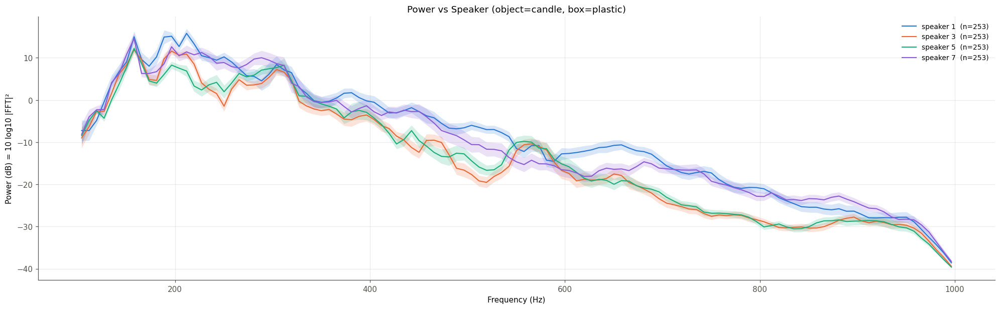

In [6]:
NAME = {'speaker': 'Speaker', 'box': 'Box', 'object': 'Object', 'laser_row': 'Laser row', 'laser_col': 'Laser column', 'pos_row': 'Position row', 'pos_col': 'Position column'}

def power_vs(by, box='plastic', objects='candle', speakers=None, bins=8, min_n=5):
    """Power P(f) = mean over lasers and axes of 10 log10 |X|^2, one line per value of `by` (see above). Line = mean ± std over
    captures; a line holding several (object, speaker) groups averages each on its own and pools the std"""
    c = cap[cap.split.isin(as_list(objects, OBJECTS))]
    if by != 'box': c = c[c.box == box]
    if speakers is not None: c = c[c.speaker.isin(as_list(speakers))]
    c = c.reset_index(drop=True)
    x = spectra(c)[0].astype(np.float32)                    # (N, 100, 117, 2)
    power = x.mean((1, 3))                                   # (N, 117)
    if by in ('laser_row', 'laser_col'):
        lid = np.arange(100) // 10 if by == 'laser_row' else np.arange(100) % 10
        lines = {f'{by[6:]} {k}': (c, x[:, lid == k].mean((1, 3))) for k in range(10)}
    elif by in ('pos_row', 'pos_col'):
        k_ = np.clip((floor_frac(c, box)[:, 0 if by == 'pos_row' else 1] * bins).astype(int), 0, bins - 1)
        lines = {f'{by[4:]} {k}' + (' (laser wall)' if by == 'pos_row' and k == bins - 1 else ''): (c[k_ == k], power[k_ == k]) for k in range(bins) if (k_ == k).sum() >= min_n}
    else:
        key = {'speaker': 'speaker', 'box': 'box', 'object': 'split'}[by]
        vals = BOXES if by == 'box' else sorted(c[key].unique(), key=str)
        lines = {(f'speaker {v}' if by == 'speaker' else v): (c[c[key] == v], power[(c[key] == v).to_numpy()]) for v in vals if (c[key] == v).any()}
    colors = [COLORS[k] for k in lines] if by == 'box' else PALETTE if by in ('speaker', 'object') else blues(len(lines))
    fig, ax = plt.subplots(figsize=(18, 5.5), constrained_layout=True)
    for (k, (g, p)), col in zip(lines.items(), colors):
        gi = [np.flatnonzero(((g.split == o) & (g.speaker == s)).to_numpy()) for o, s in dict.fromkeys(zip(g.split, g.speaker))]
        m, sd = pool([p[i].mean(0) for i in gi], [p[i].var(0) for i in gi])
        ax.fill_between(FB, m - sd, m + sd, color=col, alpha=.1 if len(lines) > 4 else .18, lw=0)
        ax.plot(FB, m, c=col, lw=1.4, label=f'{k}  (n={len(g)})')
    fixed = [f"object={', '.join(as_list(objects, OBJECTS)) if objects is not None else 'all 4'}" * (by != 'object'),
             f"speaker={speakers if speakers is not None else 'all'}" * (by != 'speaker'), f'box={box}' * (by != 'box')]
    ax.set(xlabel='Frequency (Hz)', ylabel='Power (dB) = 10 log10 |FFT|²', title=f"Power vs {NAME[by]} ({', '.join(f for f in fixed if f)})")
    ax.legend(frameon=False, ncols=2 if len(lines) > 5 else 1, fontsize=9, loc='upper right')

power_vs('speaker', 'plastic', 'candle')
save_fig('fig_power_by_speaker', 'Average power spectrum per speaker (mean ± std over captures).')

**Reading:**
- The speakers drive the box very differently: up to 5–10 dB apart. Speakers 1 and 7 are 5–10 dB louder than 3 and 5 above ~600 Hz.
- The bands are narrow (≈ 1 dB): within one speaker, where the candle sits changes the *average* spectrum only a little.
- This is why spectra are only ever compared within one speaker.

**Candle, speaker 1, one line per box:**

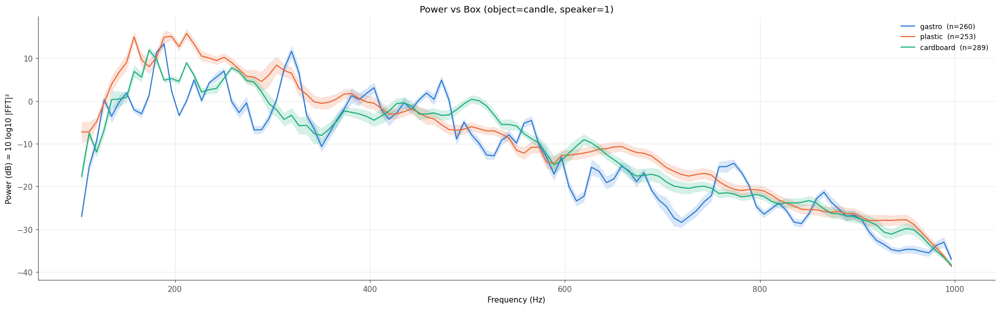

In [7]:
power_vs('box', objects='candle', speakers=1)
save_fig('fig_power_by_box', 'Average power spectrum per box (mean ± std over captures).')

**Reading:**
- Each box has its own fingerprint. Gastro is jagged, with sharp resonance peaks (swings of ~20 dB over a few Hz); plastic and cardboard are smooth.
- The overall slope is the same in all three (≈ +10 dB at 150–200 Hz down to −38 dB at 1000 Hz). The slope comes from what all three share (speaker, chirp, lasers), not from the box.

**Plastic box, speaker 1, one line per object:**

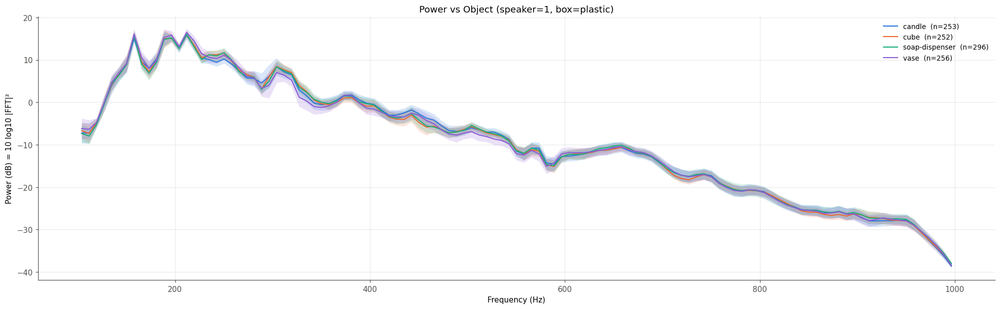

In [8]:
power_vs('object', 'plastic', None, speakers=1)
save_fig('fig_power_by_object', 'Average power spectrum per object (mean ± std over captures).')

**Reading:**
- The four objects' average spectra are almost identical: within ~1–2 dB. The vase is about 2 dB lower near 300–350 Hz and 500 Hz.
- Averaged over lasers and positions, the spectrum barely says *which* object is in the box. Whatever the model uses is in how the spectrum is spread over the lasers and how it changes with position (section 4 onward).

**Plastic box, candle, speaker 1, one line per laser row, then per laser column:**

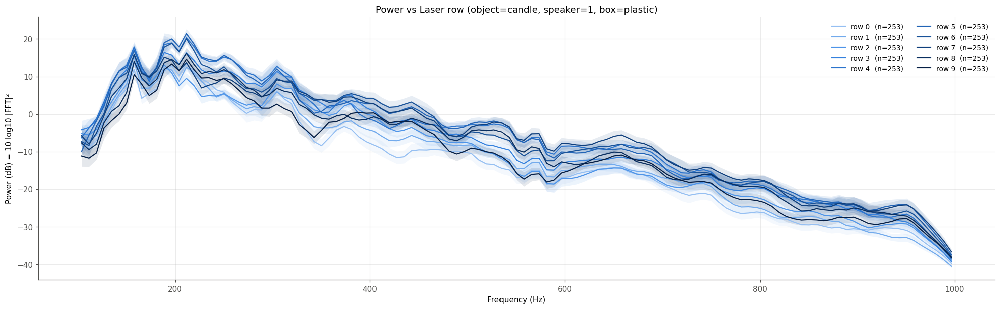

In [9]:
power_vs('laser_row', 'plastic', 'candle', speakers=1)
save_fig('fig_power_by_laser_row', 'Average power spectrum per laser row (mean ± std over captures).')

**Reading:**
- Laser rows differ by up to ~10 dB. The middle rows (4–7) are loudest; the top rows (0–1) and row 9 are quietest.
- This matches the mode shapes (section 9): the wall vibrates in bands along its rows.

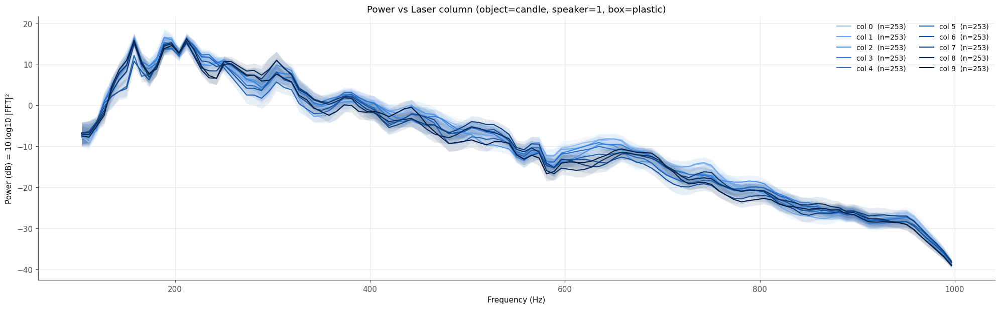

In [10]:
power_vs('laser_col', 'plastic', 'candle', speakers=1)
save_fig('fig_power_by_laser_col', 'Average power spectrum per laser column (mean ± std over captures).')

**Reading:**
- Columns differ much less than rows (~3 dB, mostly near 250–300 Hz and 600–700 Hz).
- The vibration changes much more from row to row than from column to column. The same holds for the strongest mode shapes in section 9.

**Plastic box, candle, speaker 1, one line per position row of the candle on the floor, then per position column:**

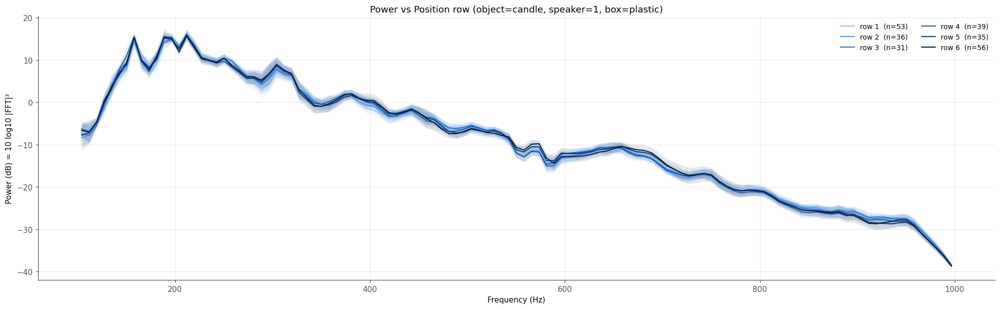

In [11]:
power_vs('pos_row', 'plastic', 'candle', speakers=1)
save_fig('fig_power_by_position_row', 'Average power spectrum per position row (mean ± std over captures).')

**Reading:**
- Where the candle sits along the floor's rows barely changes the average power: the strips lie within ~1–2 dB of each other, with the biggest gaps near 550–580 Hz. The strips next to either wall (rows 0 and 7) have fewer than 5 captures and are dropped.

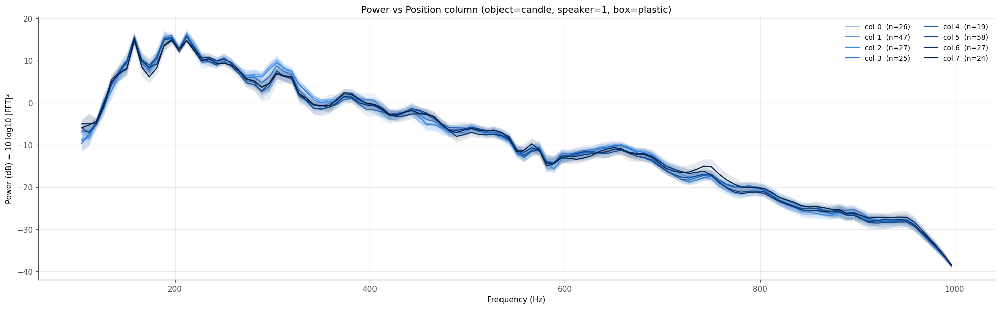

In [12]:
power_vs('pos_col', 'plastic', 'candle', speakers=1)
save_fig('fig_power_by_position_col', 'Average power spectrum per position column (mean ± std over captures).')

**Reading:**
- The same for columns: within ~1–2 dB, the largest gaps near 300 Hz and 750 Hz.
- Compare this with the laser rows (~10 dB). Moving the candle hardly changes the *total* power; it changes *how the power is spread over the lasers*. That is why sections 4–5 compare full per-laser spectra, not averages.

**Every laser of one empty cardboard capture (speaker 1), x shift then y shift:** one line per laser, coloured by its row (light = row 0, dark = row 9). One capture, so there is no std.

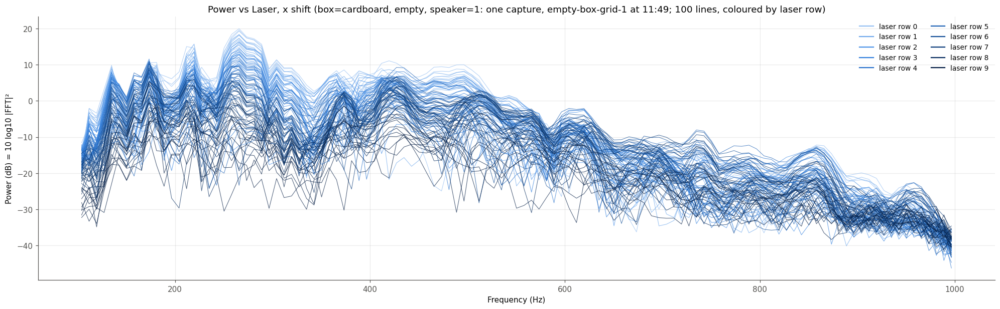

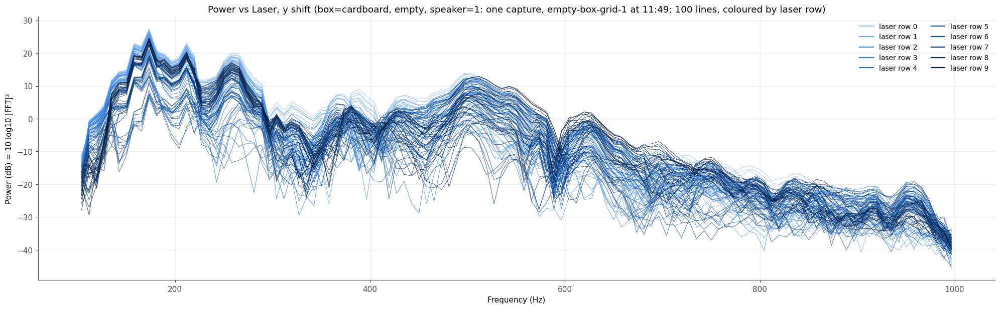

In [13]:
e = cap[(cap.box == 'cardboard') & (cap.split == 'empty-box') & (cap.speaker == 1)].sort_values('t').reset_index(drop=True).iloc[:1]
x = spectra(e)[0][0].astype(np.float32)                     # (100 lasers, 117 bands, 2 axes), dB
for c, axis in enumerate('xy'):
    fig, ax = plt.subplots(figsize=(18, 5.5), constrained_layout=True)
    for l in range(100): ax.plot(FB, x[l, :, c], c=blues(10)[l // 10], lw=.7, alpha=.7)
    ax.legend(handles=[Line2D([], [], c=col, label=f'laser row {r}') for r, col in enumerate(blues(10))], frameon=False, ncols=2, fontsize=9, loc='upper right')
    ax.set(xlabel='Frequency (Hz)', ylabel='Power (dB) = 10 log10 |FFT|²',
           title=f'Power vs Laser, {axis} shift (box=cardboard, empty, speaker=1: one capture, {e.layout[0]} at {e.t[0]:%H:%M}; 100 lines, coloured by laser row)')
    save_fig(f'fig_lasers_one_capture_{axis}', f'Every laser of one empty cardboard capture (speaker 1), {axis} shift, coloured by laser row.')

**Reading:**
- One capture, one box, nothing in it, yet the 100 lasers differ by **20–30 dB** at the same frequency: far more than any average in this section moves (speakers 5–10 dB, objects 1–2 dB, positions 1–2 dB). The information is in this spread across the wall.
- **y is the main axis of motion.** It is louder (up to +25 dB near 170 Hz, against +10–20 dB in x), and below ~300 Hz all lasers move together: the whole wall goes in and out.
- **The row order flips with frequency.** In y, the top rows (light) lead near 250–300 Hz, and the bottom rows (dark) lead from ~450 to 650 Hz. Those are different mode shapes taking over (section 9).
- In x, the bottom rows are the weakest and most jagged below ~600 Hz (down to −30 dB): little x motion there, so those channels are mostly noise.

### 4 Spectral distance over the floor
`D_spec` from one reference position to every other position of the same object and speaker. Two figures. First: one dot per position on the box's whole overhead photo (not cropped further); the star is the reference. Second: the same binned over the floor.
- **Colour** (light = close to the reference, dark = far) uses 9 *quantile* steps: each colour holds the same share of the values, so small differences near the reference become visible.
- This is not a distortion: the colourbar labels each step with its real dB value, and the numbers in the bins are real. An exponential or log scale would instead exaggerate some gaps and hide others. The reference is each object's own position closest to the middle of the floor (`target` in the cell); the per-position value is the mean over speakers, and a bin is the mean over objects. The title gives the repeat noise to read it against.

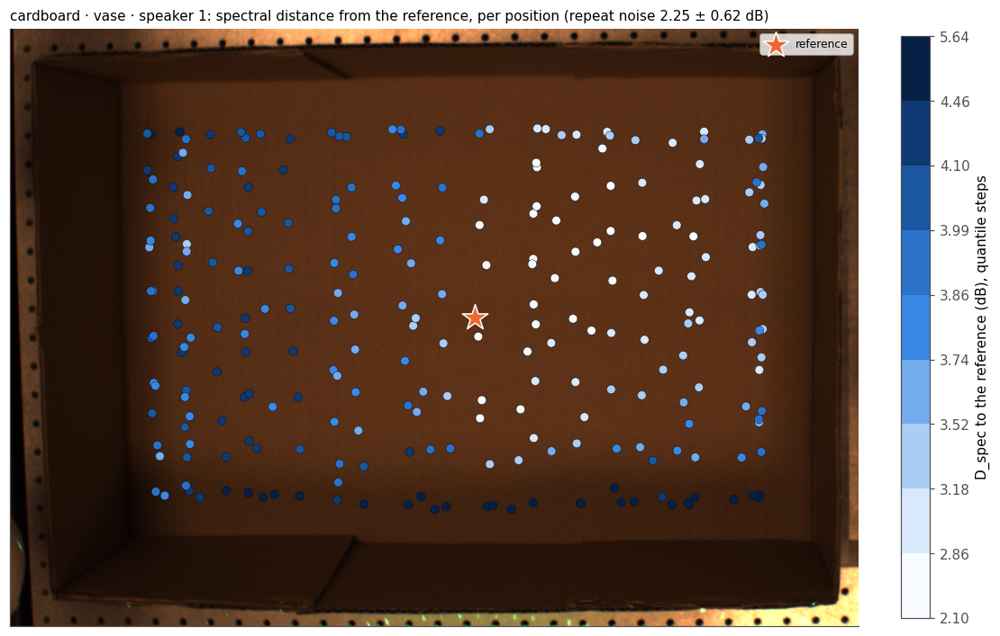

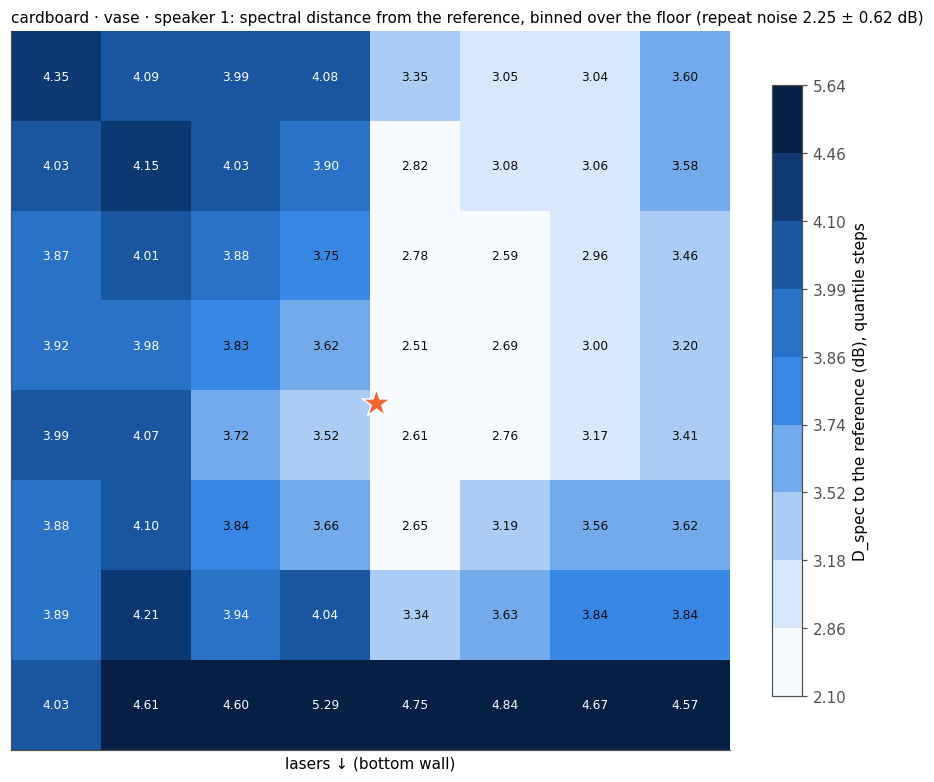

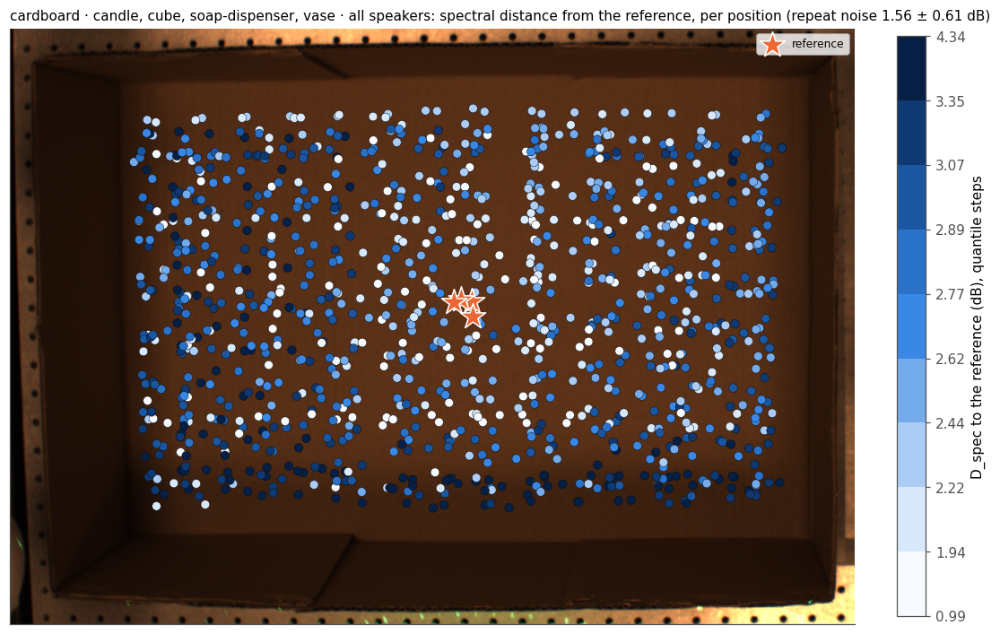

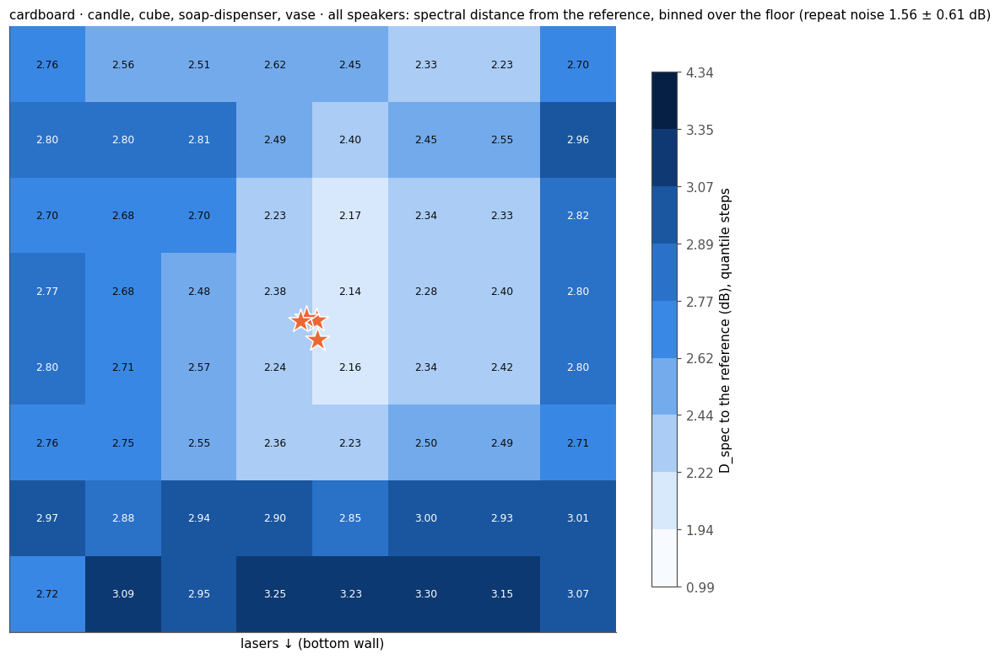

In [14]:
box, bins = 'cardboard', 8
for objects, speakers in (('vase', 1), (None, None)):     # the vase with speaker 1, then all four objects and every speaker
    target = np.array([.5, .5])                            # the reference: each object's position closest to the middle of the floor
    gs, rows = groups(box, objects, speakers), []
    for o in dict.fromkeys(o for o, _ in gs):
        pos = cap[(cap.box == box) & (cap.split == o)].drop_duplicates('position_id')
        ref = pos.position_id.iloc[np.argmin(np.hypot(*(floor_frac(pos, box) - target).T))]
        for (oo, s), g in gs.items():
            if oo != o or not (g.position_id == ref).any(): continue
            x = spectra(g)[0]
            rows.append(g.assign(d=d_spec(x[(g.position_id == ref).to_numpy()], x).mean(0), ref=ref))
    res = pd.concat(rows).groupby(['split', 'position_id']).agg(d=('d', 'mean'), ref=('ref', 'first'), com_r=('com_r', 'first'), com_c=('com_c', 'first'), H=('H', 'first'), W=('W', 'first')).reset_index()
    res = res[res.position_id != res.ref]                  # per position: the mean over speakers
    ij = np.clip((floor_frac(res, box) * bins).astype(int), 0, bins - 1)
    per = res.assign(i=ij[:, 0], j=ij[:, 1]).groupby(['split', 'i', 'j']).d.mean().groupby(['i', 'j']).mean()   # a bin = mean over objects
    grid = np.full((bins, bins), np.nan); grid[per.index.get_level_values(0), per.index.get_level_values(1)] = per.to_numpy()
    nz = np.concatenate([noise(box, s) for s in sorted({s for _, s in gs})])
    levels = np.unique(np.nanquantile(np.concatenate([res.d, grid[np.isfinite(grid)]]), np.linspace(0, 1, 10)))
    norm = BoundaryNorm(levels, 256)                       # quantile steps: each colour holds the same share of values
    refs = cap[(cap.box == box) & cap.position_id.isin(res.ref.unique())].drop_duplicates('position_id')
    what = f"{box} · {', '.join(as_list(objects, OBJECTS))} · {'all speakers' if speakers is None else f'speaker {speakers}'}"
    for kind in ('photo', 'binned'):
        fig, ax = plt.subplots(figsize=(10, 7) if kind == 'photo' else (9, 7), constrained_layout=True)
        if kind == 'photo':
            photo(ax, box)
            m = ax.scatter(res.com_c, res.com_r, c=res.d, cmap=SEQ, norm=norm, s=40, edgecolors=INK, linewidths=.3)
            ax.scatter(refs.com_c, refs.com_r, marker='*', s=380, c='#eb6834', edgecolors='white', linewidths=1, label='reference')
            ax.legend(loc='upper right', fontsize=8)
        else:
            m = ax.imshow(grid, cmap=SEQ, norm=norm, extent=(0, 1, 1, 0))
            for (i, j), v in np.ndenumerate(grid):
                if np.isfinite(v): ax.text((j + .5) / bins, (i + .5) / bins, f'{v:.2f}', ha='center', va='center', fontsize=8, color='white' if norm(v) > 140 else INK)
            rf = floor_frac(refs, box)
            ax.scatter(rf[:, 1], rf[:, 0], marker='*', s=380, c='#eb6834', edgecolors='white', linewidths=1)
            ax.set(xticks=[], yticks=[], xlabel='lasers ↓ (bottom wall)'); ax.grid(False)
        ax.set_title(f"{what}: spectral distance from the reference, {'per position' if kind == 'photo' else 'binned over the floor'} (repeat noise {nz.mean():.2f} ± {nz.std():.2f} dB)", loc='left', fontsize=10)
        cb = fig.colorbar(m, ax=ax, shrink=.85, spacing='uniform', label='D_spec to the reference (dB), quantile steps')
        cb.set_ticks(levels); cb.set_ticklabels([f'{v:.2f}' for v in levels])
        save_fig(f"fig_spectral_distance_{'vase' if objects else 'all'}_{kind}", f"Spectral distance from a reference position over the floor ({what}), {'per position' if kind == 'photo' else 'binned'}.")

**Reading:**
- **Vase, speaker 1:** distance grows with position, but not as a ring around the reference. Positions in the reference's *column* (the same distance from the left and right walls) stay close (2.5–2.8 dB) all the way to the back wall. The left half of the box is the farthest (≈ 4 dB), and so is the row next to the laser wall (4.6–5.3 dB).
- **All four objects, all speakers:** the same picture, smoother. 2.1–2.4 dB near the middle, ~2.8 at the side walls, ~3.0–3.3 along the laser wall.
- Even the nearest bins sit well above the repeat noise (2.25 for speaker 1 alone, 1.56 pooled). Two captures at almost the same spot, recorded minutes apart, differ more than back-to-back repeats (drift, section 6).
- The laser-wall row is the most distinct region: an object right next to the lasers changes what they see the most. This matches nb95 (edges are louder, with a coherent low-frequency shift).

### 5 Spectral change vs distance moved
nb99's `S(Δ)` for every box. Take every pair of captures of one (object, speaker), bin the pairs by `D_pos` (0.04 of the box per bin), and average their `D_spec`. Bins with < 5 pairs are dropped. Line = mean over groups, band = ± pooled std over pairs, dashed = repeat noise.
- `move = mean D_spec(D_pos > 0.25) − mean D_spec(0 < D_pos < 0.05)`: the rise of the curve, i.e. the position signal.
- `move / noise`: that rise in units of repeat noise (in the legend, mean ± std over groups). Below 1, moving the object across the box changes the spectrum less than recording twice.

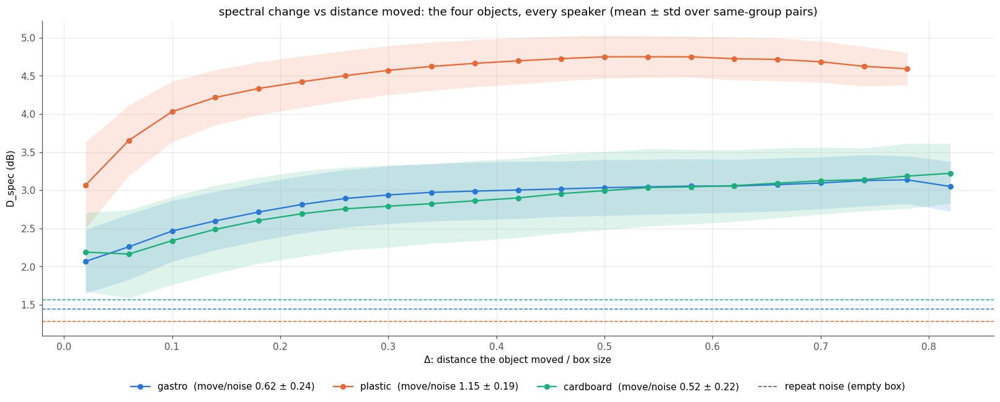

In [15]:
step = .04
edges = np.arange(0, .85, step)
fig, ax = plt.subplots(figsize=(18, 6))
for b in BOXES:
    M, V, mn, nz = [], [], [], []
    for (o, s), g in groups(b).items():                    # every (object, speaker) on its own
        iu = np.triu_indices(len(g), 1)
        dd = d_spec(*[spectra(g)[0]] * 2)[iu]
        r, c = g.com_r.to_numpy(), g.com_c.to_numpy()
        dp = (np.hypot(r[:, None] - r, c[:, None] - c) / np.sqrt(g.H * g.W).to_numpy())[iu]
        st = pd.Series(dd).groupby(pd.cut(dp, edges), observed=False).agg(['mean', 'var', 'size'])
        M.append(st['mean'].where(st['size'] >= 5).to_numpy()); V.append(st['var'].where(st['size'] >= 5).to_numpy())
        n = noise(b, s).mean()
        mn.append((dd[dp > .25].mean() - dd[(dp > 0) & (dp < .05)].mean()) / n); nz.append(n)
    m, sd = pool(M, V)
    ax.fill_between(edges[:-1] + step / 2, m - sd, m + sd, color=COLORS[b], alpha=.15, lw=0)
    ax.plot(edges[:-1] + step / 2, m, 'o-', c=COLORS[b], ms=5, label=f'{b}  (move/noise {np.mean(mn):.2f} ± {np.std(mn):.2f})')
    ax.axhline(np.mean(nz), c=COLORS[b], ls='--', lw=1)
ax.plot([], [], c=MUTED, ls='--', lw=1, label='repeat noise (empty box)')
ax.set(xlabel='Δ: distance the object moved / box size', ylabel='D_spec (dB)', title='spectral change vs distance moved: the four objects, every speaker (mean ± std over same-group pairs)')
ax.legend(frameon=False, ncols=4, loc='upper center', bbox_to_anchor=(.5, -.12));
save_fig('fig_spectral_change_vs_distance', 'Spectral change vs distance moved, per box (move / noise).')

**Reading:**
- Plastic's spectrum responds most to position: it rises from 3.1 to 4.5 dB within the first 30% of the box, and move / noise = 1.15 ± 0.19.
- Gastro (0.62 ± 0.24) and cardboard (0.52 ± 0.22) rise slowly and about equally. Moving an object across the whole box changes their spectrum by about half a repeat noise more than moving it a little. Over these four objects both are higher than nb99 found for the cube alone (0.35 / 0.34): the cube is the hardest object.
- Even the closest pairs (Δ < 0.04) sit 0.6–1.8 dB above the noise lines: the session drift (section 6).
- Plastic is also the loudest-changing box *overall* (≈ 4.5 dB at large Δ vs ≈ 3 dB), so the object's presence and its position both show up more strongly there.

### 6 The empty box over the session
Is the setup the same at the end of a session as at the start? Each line is one empty-box layout (light = earliest, labelled with its start time), showing `L(f)` per speaker averaged over its 3–4 back-to-back captures, then over speakers. Band = ± std over those captures. The table compares the two kinds of change, within one speaker, mean ± std over pairs:
- **repeat noise**: back-to-back captures of the same layout;
- **drift**: captures of different layouts, recorded hours apart.

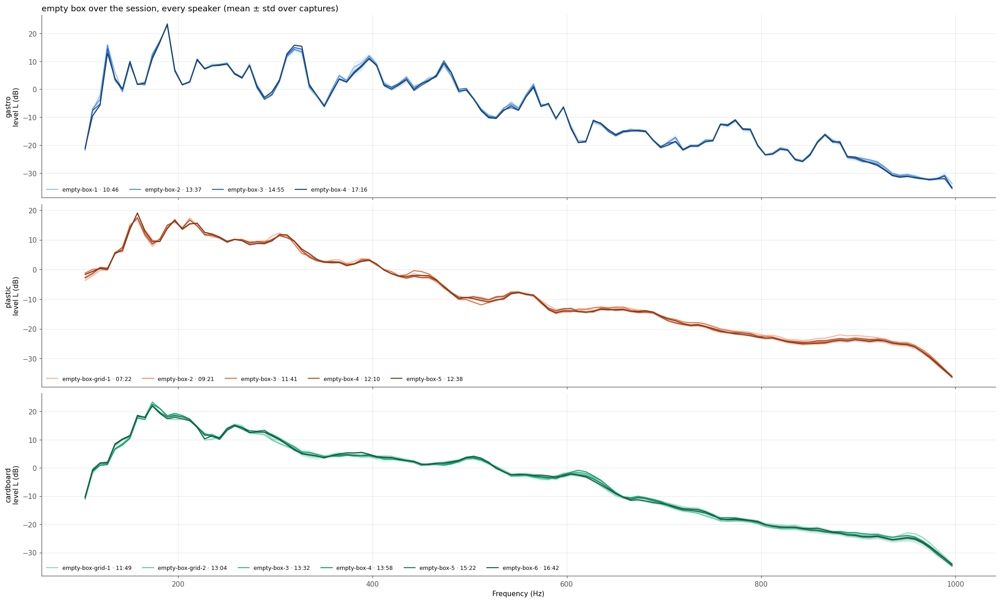

,gastro,plastic,cardboard
layouts,4,5,6
captures,36,60,76
session span (h),6.5,5.3,4.9
repeat noise (dB),1.45 ± 0.37,1.28 ± 0.30,1.56 ± 0.61
drift between layouts (dB),2.01 ± 0.29,2.60 ± 0.51,2.74 ± 0.60
drift / noise,1.39,2.03,1.75


In [16]:
fig, axs = plt.subplots(len(BOXES), 1, figsize=(20, 12), sharex=True, constrained_layout=True)
table = {}
for ax, b in zip(axs, BOXES):
    e = cap[(cap.box == b) & (cap.split == 'empty-box')].reset_index(drop=True)
    L = spectra(e)[1]
    order = e.groupby('layout').t.min().sort_values()
    rgb = np.array(to_rgb(COLORS[b]))
    for (lay, t0), a in zip(order.items(), np.linspace(.5, -.5, len(order))):   # light (first) -> dark (last)
        gs = [L[i] for i in e[e.layout == lay].groupby('speaker').groups.values()]   # index labels = rows of e
        m, sd = pool([g.mean(0) for g in gs], [g.var(0) for g in gs])
        col = rgb + a * (1 - rgb) if a > 0 else rgb * (1 + a)
        ax.fill_between(FB, m - sd, m + sd, color=col, alpha=.15, lw=0)
        ax.plot(FB, m, c=col, lw=1.4, label=f'{lay} · {t0:%H:%M}')
    ax.set(ylabel=f'{b}\nlevel L (dB)')
    ax.legend(ncols=len(order), fontsize=8, frameon=False, loc='lower left')
    same, diff = [], []                                    # repeat noise (same layout) vs drift (different layouts), within a speaker
    for _, g in e.groupby('speaker'):
        dd, lay = d_spec(*[spectra(g)[0]] * 2), g.layout.to_numpy()
        iu = np.triu_indices(len(g), 1)
        same += list(dd[iu][lay[iu[0]] == lay[iu[1]]]); diff += list(dd[iu][lay[iu[0]] != lay[iu[1]]])
    table[b] = {'layouts': e.layout.nunique(), 'captures': len(e), 'session span (h)': f'{(e.t.max() - e.t.min()).total_seconds() / 3600:.1f}',
                'repeat noise (dB)': f'{np.mean(same):.2f} ± {np.std(same):.2f}', 'drift between layouts (dB)': f'{np.mean(diff):.2f} ± {np.std(diff):.2f}',
                'drift / noise': f'{np.mean(diff) / np.mean(same):.2f}'}
axs[0].set_title('empty box over the session, every speaker (mean ± std over captures)', loc='left')
axs[-1].set_xlabel('Frequency (Hz)')
save_fig('fig_empty_box_session', 'The empty box over the session: one line per empty-box layout (light = earliest).')
plt.show()
save_table(pd.DataFrame(table), 'tab_empty_box_session', 'The empty box over the session')

**Reading:**
- The empty box is stable to within about a dB over 5–6.5 hours in every box. The layout lines lie on top of each other, and the shape of the spectrum (every peak and dip) is unchanged.
- But drift is real: captures hours apart differ by 2.0 / 2.6 / 2.7 dB against a repeat noise of 1.45 / 1.28 / 1.56 dB (gastro / plastic / cardboard), so drift / noise = 1.4 / 2.0 / 1.75. Plastic and cardboard drift the most relative to their noise.
- How it compares with what an object does (section 5): in gastro and plastic, drift (2.0 and 2.6 dB) stays well below the change from moving an object across the box (≈ 3.0 and 4.6 dB). In cardboard the two are close (2.7 vs ≈ 3.1 dB), so drift is a large part of what tells cardboard captures apart, and a model can mistake recording time for position there.
- Drift is also why no two captures at the same spot ever look as alike as back-to-back repeats.

### 7 Envelope and time to noise
How fast the box goes quiet after the speaker's impulse (nb99 section 5). Per capture, from the raw shifts (band-passed, no window):
- impulse response `h = irfft(X / C)`, where `C` is the spectrum of the chirp that was played;
- envelope `E(t) = 10 log10 smooth_10ms mean_{l,c} h²`, in dB re its peak;
- noise floor = the same quantity for the silent start of the capture (before the chirp), as energy per sample;
- **time to noise** = the first `t` with `E ≤ floor + 1 dB` (searched up to 0.75 s).

Uses **every empty-box capture** (36 / 60 / 76 for gastro / plastic / cardboard). Set `objects` / `speakers` at the top of the cell (default: `'empty-box'`, every speaker). First figure: the 100–1000 Hz envelope, mean ± pooled std over captures, with the noise floor dashed and the mean time to noise dotted. Second figure: time to noise per band, octaves in increasing frequency and then the whole band; the % is the share of captures that reach the floor within 0.75 s.

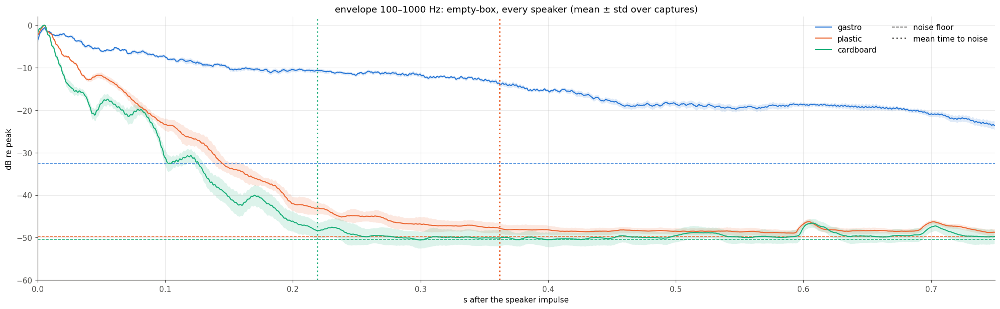

In [17]:
FPS, QUIET = 2500, slice(25, 375)                          # QUIET: camera frames before the chirp arrives
BANDS = ((100, 200), (200, 400), (400, 800), (100, 1000))   # octaves by increasing frequency, then the whole band
objects, speakers = 'empty-box', None                       # every empty-box capture, every speaker

def envelope(d, t_max=.75):
    """impulse response h = irfft(X / chirp) of the raw shifts (band-passed, no window); per band: its envelope (dB re peak), the
    noise floor (the same for the silent start, energy per sample) and the time to noise (first t with E <= floor + 1 dB)"""
    x = sosfiltfilt(butter(5, [100, 1000], fs=FPS, btype='band', output='sos'), np.load(d / 'vibration/02_raw_shifts.npy'), axis=1)
    nt = x.shape[1]
    C = np.fft.rfft(np.concatenate([np.zeros(250), chirp(np.arange(FPS) / FPS, f0=100, t1=1.0, f1=1000, method='logarithmic'), np.zeros(nt - 2750)]))
    inband = (np.fft.rfftfreq(nt, 1 / FPS) >= 100) & (np.fft.rfftfreq(nt, 1 / FPS) <= 1000)
    q = np.zeros_like(x); q[:, QUIET] = x[:, QUIET]
    deconv = lambda y: np.fft.irfft(np.where(inband[None, :, None], np.fft.rfft(y, axis=1) / C[None, :, None], 0), n=nt, axis=1)
    h, hq = deconv(x), deconv(q)
    h = np.roll(h, -(h ** 2).mean((0, 2)).argmax(), axis=1)
    out = {}
    for lo, hi in BANDS:
        sos = butter(4, [lo, hi], fs=FPS, btype='band', output='sos')
        e = np.convolve((sosfiltfilt(sos, h, axis=1) ** 2).mean((0, 2)), np.ones(25) / 25, 'same')
        fl = 10 * np.log10((sosfiltfilt(sos, hq, axis=1) ** 2).mean((0, 2)).sum() / (QUIET.stop - QUIET.start) / e.max())
        e = 10 * np.log10(e / e.max())[:int(t_max * FPS)]
        hit = np.flatnonzero(e <= fl + 1)
        out[lo, hi] = dict(env=e.astype(np.float32), floor=fl, t_noise=hit[0] / FPS if len(hit) else np.nan)
    return out

env = {}
for b in BOXES:
    E = []
    for g in groups(b, objects, speakers).values():
        def run(g=g):
            with ThreadPoolExecutor(8) as ex: return list(ex.map(envelope, g.dir))
        E.append(cached('envNone', list(g.dir), run))
    tn = [np.array([[e[bd]['t_noise'] for e in es] for bd in BANDS]) for es in E]   # per group: (bands, captures)
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', RuntimeWarning)
        tm, ts = pool([np.nanmean(t, 1) for t in tn], [np.nanvar(t, 1) for t in tn])
    m, sd = pool([np.stack([e[100, 1000]['env'] for e in es]).mean(0) for es in E], [np.stack([e[100, 1000]['env'] for e in es]).var(0) for es in E])
    env[b] = dict(m=m, sd=sd, floor=np.mean([e[100, 1000]['floor'] for es in E for e in es]), tm=tm, ts=ts, reach=np.mean([np.isfinite(t).mean(1) for t in tn], 0))

fig, ax = plt.subplots(figsize=(18, 5.5), constrained_layout=True)
for b, r in env.items():
    tt = np.arange(len(r['m'])) / FPS
    ax.fill_between(tt, r['m'] - r['sd'], r['m'] + r['sd'], color=COLORS[b], alpha=.15, lw=0)
    ax.plot(tt, r['m'], c=COLORS[b], lw=1.4, label=b)
    ax.axhline(r['floor'], c=COLORS[b], ls='--', lw=1)
    if np.isfinite(r['tm'][-1]) and r['reach'][-1] > .5: ax.axvline(r['tm'][-1], c=COLORS[b], ls=':', lw=2)
ax.plot([], [], c=MUTED, ls='--', lw=1, label='noise floor'); ax.plot([], [], c=MUTED, ls=':', lw=2, label='mean time to noise')
ax.set(xlim=(0, .75), ylim=(-60, 2), xlabel='s after the speaker impulse', ylabel='dB re peak', title=f'envelope 100–1000 Hz: {objects}, every speaker (mean ± std over captures)')
ax.legend(frameon=False, ncols=2);
save_fig('fig_envelope', 'Envelope after the impulse, per box.')

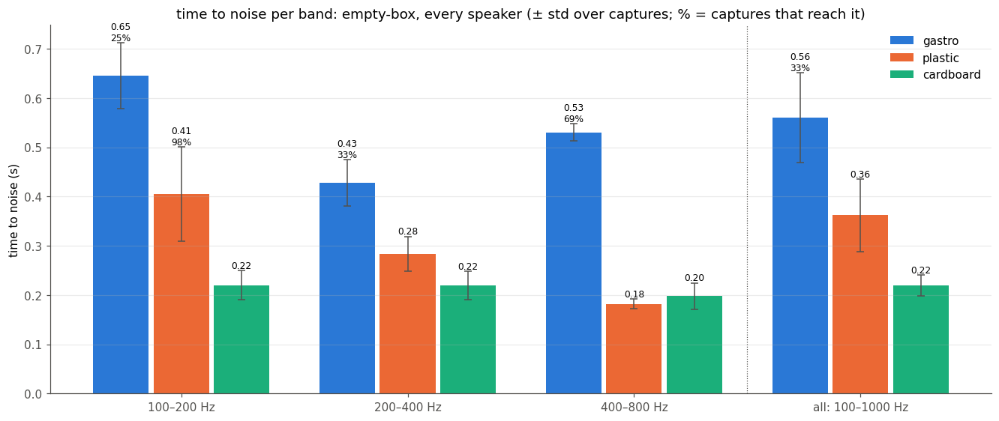

In [18]:
fig, ax = plt.subplots(figsize=(12, 5), constrained_layout=True)
w = .8 / len(BOXES)
for k, (b, r) in enumerate(env.items()):
    x = np.arange(len(BANDS)) + (k - 1) * w
    ax.bar(x, r['tm'], w * .92, color=COLORS[b], label=b)
    ax.errorbar(x, r['tm'], r['ts'], fmt='none', ecolor=MUTED, lw=1, capsize=3)
    for xi, v, s, rch in zip(x, r['tm'], r['ts'], r['reach']):
        ax.annotate('> 0.75' if not np.isfinite(v) else f'{v:.2f}' + ('' if rch > .99 else f'\n{rch:.0%}'), (xi, 0 if not np.isfinite(v) else v + s), xytext=(0, 2), textcoords='offset points', ha='center', fontsize=8)
ax.axvline(len(BANDS) - 1.5, c=MUTED, lw=.8, ls=':')
ax.set_xticks(range(len(BANDS)), [f'{lo}–{hi} Hz' for lo, hi in BANDS[:-1]] + ['all: 100–1000 Hz'])
ax.set(ylabel='time to noise (s)', title=f'time to noise per band: {objects}, every speaker (± std over captures; % = captures that reach it)')
ax.grid(axis='x', visible=False); ax.legend(frameon=False);
save_fig('fig_time_to_noise', 'Time until the box is back at the noise floor, per octave and box.')

**Reading:**
- Cardboard goes quiet first: 0.22 s over 100–1000 Hz, and 0.20–0.22 s in every octave.
- Plastic takes 0.36 s. It rings long at low frequency (0.41 s, 100–200 Hz) and dies fast above 400 Hz (0.18 s, as fast as cardboard there).
- Gastro rings for seconds. Only a third of its captures reach the noise floor within 0.75 s.
  - Its floor (−32.5 dB) is inflated: the 'silent' start of a capture still holds the previous chirp's ringing (nb99). So its times to noise are lower bounds at best.
- The bands are tight (± 0.01–0.1 s), and the same numbers came out with the four objects in the box: damping belongs to the box, not to what's in it.
- The bumps at 0.6 and 0.7 s are harmonic-distortion responses of the log sweep, not ringing.

### 8 Cumulative energy of the spatial patterns
How many distinct spatial patterns (mode shapes) does the box have? Per (object, speaker), every capture's `X` becomes a `1170 × 200` matrix: row `f` is the 100 lasers × 2 axes at `f`, scaled to unit length, so only its *shape* counts. All captures of the group are stacked, then:
- `X = U S Vᴴ`: the columns of `V` are the spatial patterns, and `s_k²` is pattern `k`'s energy;
- cumulative energy `Σ_{j≤k} s_j² / Σ s²`;
- `eff_rank = (Σ s²)² / Σ s⁴` (= r if the energy is spread evenly over r patterns);
- `n90` = the number of patterns that hold 90% of the energy.

One curve per group, and the band is ± std *between* groups (speakers and objects). Dots mark every k. The eigenvalues are cached per group.

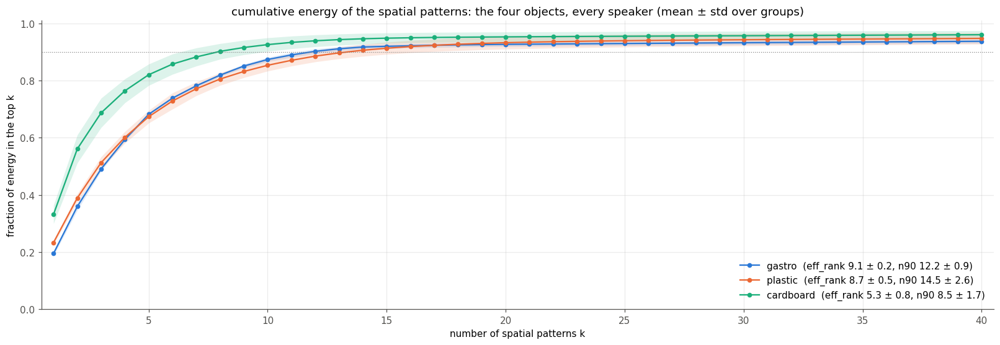

In [19]:
def gram(d):
    """X^H X of one capture: X = (1170 freqs, 200 = lasers x axes), each row scaled to unit length (its spatial shape only)"""
    F_ = D.load_fft(d).numpy()
    X = F_.transpose(1, 0, 2).reshape(F_.shape[1], -1)
    X = X / np.linalg.norm(X, axis=1, keepdims=True)
    return X.conj().T @ X

def energies(g):
    """s_k^2 of one group's captures stacked into one tall matrix (its X^H X is the sum of the captures' grams). Cached"""
    def run():
        with ThreadPoolExecutor(8) as ex: return np.linalg.eigvalsh(sum(ex.map(gram, g.dir)))[::-1]
    return cached('eig', list(g.dir), run)

k = 40
fig, ax = plt.subplots(figsize=(18, 5.5))
for b in BOXES:
    s2 = [energies(g) for g in groups(b).values()]         # one curve per (object, speaker)
    cum = np.stack([np.cumsum(s) / s.sum() for s in s2])[:, :k]
    er = [s.sum() ** 2 / (s ** 2).sum() for s in s2]
    n90 = [np.searchsorted(np.cumsum(s) / s.sum(), .9) + 1 for s in s2]
    ax.fill_between(np.arange(1, k + 1), cum.mean(0) - cum.std(0), cum.mean(0) + cum.std(0), color=COLORS[b], alpha=.15, lw=0)
    ax.plot(np.arange(1, k + 1), cum.mean(0), 'o-', c=COLORS[b], ms=4, label=f'{b}  (eff_rank {np.mean(er):.1f} ± {np.std(er):.1f}, n90 {np.mean(n90):.1f} ± {np.std(n90):.1f})')
ax.axhline(.9, c='gray', lw=.8, ls=':')
ax.set(xlabel='number of spatial patterns k', ylabel='fraction of energy in the top k', xlim=(.5, k + .5), ylim=(0, 1.01),
       title='cumulative energy of the spatial patterns: the four objects, every speaker (mean ± std over groups)')
ax.legend(frameon=False, loc='lower right');
save_fig('fig_mode_energy', 'Cumulative energy of the spatial patterns (SVD), per box.')

**Reading:**
- Cardboard has far fewer spatial patterns: eff_rank 5.3 ± 0.8 vs 9.1 (gastro) and 8.7 (plastic), and n90 = 8.5 vs 12.2 and 14.5. Its first pattern alone holds 33% of the energy (gastro 20%, plastic 23%).
- These are nb99's cube + empty numbers (9.2 / 8.4 / 5.4) to within a few tenths. The four objects don't add patterns: the pattern count belongs to the box.
- Gastro and plastic are close up to k ≈ 15. After that plastic keeps a longer tail of weak patterns (its shape drifts smoothly with frequency).
- No curve reaches 1. The last 4–7% of the energy is spread thinly over the remaining ~160 directions, which is the noise floor of the shapes.

### 9 The top 3 mode shapes
What do the patterns of section 8 look like? No peak picking is involved: the patterns come from all frequencies at once (an SVD). The stacked matrix `X` has one row per (capture, frequency) and one column per laser channel (100 lasers × x/y shift):
- `X = U S Vᴴ`;
- **columns of V** = the spatial patterns: one complex weight per laser and axis. This is the mode shape, and it is what is drawn;
- **columns of U** = how strongly each row (one frequency of one capture) uses that pattern, i.e. where in frequency and in which captures it is active;
- `s_k²` = pattern k's energy; its share `s_k² / Σ s²` is in each title.

Shapes are computed for one speaker (default 1), with all four objects stacked. A shape's sign and global phase are arbitrary, and shapes from different speakers or objects can't be averaged. So each one is rotated to be as real as possible (phase `½ arg Σ v²`), and its largest entry is made positive.
- **Colour** = `Re v` on the dominant axis (scaled to max 1). Nodal lines are where it changes sign.
- **Arrows** = `(Re v_x, Re v_y)`, the in-plane shift direction of each laser spot.
- The second energy number in each title is the mean ± std over every (object, speaker) group.
- Grid: laser `l` at (row `l // 10`, column `l % 10`) in the camera's laser order. Not yet checked against the floor's orientation.

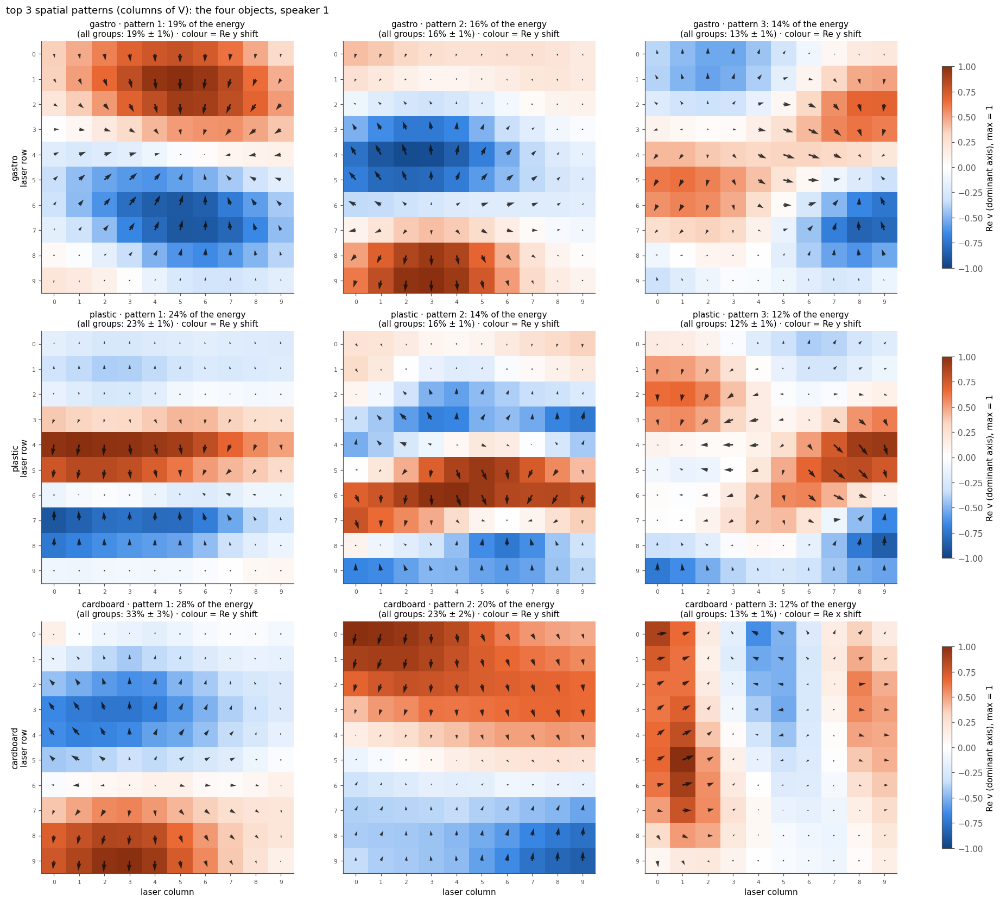

In [20]:
speaker, k = 1, 3
fig, axs = plt.subplots(len(BOXES), k, figsize=(5.6 * k, 15), squeeze=False, constrained_layout=True)
rr, cc = np.divmod(np.arange(100), 10)                       # laser l at (row l // 10, col l % 10)
for row, b in zip(axs, BOXES):
    def run(g):
        with ThreadPoolExecutor(8) as ex: return sum(ex.map(gram, g.dir))
    w, V = np.linalg.eigh(sum(cached('gram', list(g.dir), lambda g=g: run(g)) for g in groups(b, None, speaker).values()))
    w, V = w[::-1], V[:, ::-1]                               # columns of V = the patterns, strongest first
    share_all = np.stack([e / e.sum() for e in (energies(g) for g in groups(b).values())])[:, :k]
    for j, ax in enumerate(row):
        v = V[:, j] * np.exp(-0.5j * np.angle((V[:, j] ** 2).sum()))   # as real as possible
        v = v.reshape(100, 2)                                 # (laser, axis)
        v = v * np.sign(v.real.ravel()[np.argmax(np.abs(v.real.ravel()))])
        a = int(np.argmax((np.abs(v) ** 2).sum(0)))           # dominant axis
        re = v.real / np.abs(v.real).max()
        im = ax.imshow(re[:, a].reshape(10, 10), cmap=DIVERGE, vmin=-1, vmax=1)
        ax.quiver(cc, rr, re[:, 0], re[:, 1], angles='xy', scale_units='xy', scale=2.2, width=.006, color=INK, alpha=.8)
        ax.set(xticks=range(10), yticks=range(10), xlim=(-.5, 9.5), ylim=(9.5, -.5)); ax.tick_params(labelsize=7); ax.grid(False)
        ax.set_title(f"{b} · pattern {j + 1}: {w[j] / w.sum():.0%} of the energy\n(all groups: {share_all[:, j].mean():.0%} ± {share_all[:, j].std():.0%}) · colour = Re {'xy'[a]} shift", fontsize=10)
        if j == 0: ax.set_ylabel(f'{b}\nlaser row')
    fig.colorbar(im, ax=row, shrink=.8, label='Re v (dominant axis), max = 1')
for ax in axs[-1]: ax.set_xlabel('laser column')
fig.suptitle(f'top {k} spatial patterns (columns of V): the four objects, speaker {speaker}', x=.01, ha='left');
save_fig('fig_mode_shapes', f'The top {k} spatial patterns (mode shapes) of each box, speaker {speaker}.')

**Reading:**
- The strongest patterns are **bands across laser rows**, mostly in the y shift: standing waves along the wall's row direction.
  - gastro pattern 1 (19%): rows 1–2 against rows 6–7, one nodal line.
  - plastic pattern 1 (24%): rows 4–5 against rows 7–8.
  - cardboard pattern 1 (28%; 33 ± 3% over groups): rows 2–4 against rows 8–9, strongest on the left half.
- Pattern 2 adds a nodal line in every box: three bands in gastro and plastic, top half against bottom half in cardboard.
- Pattern 3 is where the boxes differ. In gastro and plastic it is a 2-D, checkerboard-like shape (rows *and* columns). In cardboard it is the only one in the **x** shift, as column bands (0–2 against 4–5).
- The energy shares are very stable across groups (± 1–3%): the same shapes come back for every object and speaker. They are the box's shapes, consistent with section 8.
- Cardboard puts the most energy in its first two patterns (48% here, against 35% gastro and 38% plastic). That is why its cumulative curve rises fastest and its eff_rank is lowest.

### 10 What changes when an object moves: mode frequency, amplitude or shape?
Every mode has a **frequency**, an **amplitude**, and a **shape**. *Shape* means the mode shape: how the vibration is spread over the 100 lasers (the 200 x/y shifts at one frequency, `u(f)`, scaled to unit length). It is *not* the shape of the spectrum curve.

For two captures a and b (same speaker), in 9 windows of ~100 Hz:
1. **Align → frequency.** Slide b's level curve `l_b(f)` left or right, by up to 10 Hz, until it best matches `l_a(f)` (highest correlation). The slide `τ` is the frequency shift: if the object detunes the modes, the peaks move, and `τ ≠ 0`.
2. **Amplitude** = the level difference left after the slide: `rms_f (l_a(f) − l_b(f + τ))`, in dB.
3. **Shape** = how different the mode shapes are at matching frequencies: `mean_f (1 − MAC)`, with `MAC = |u_a(f) · u_b(f + τ)*|²`. 0 = same shape, 1 = unrelated.

Aligning first means a pure frequency shift is counted once, as frequency, and not again as amplitude or shape.

**The plot** (the cube, in every box):
- **Top**, one panel per part. x = frequency window; y = how much that part changed.
  - Solid = two captures with the cube far apart (> 25% of the box).
  - Dashed = two back-to-back recordings of the empty box (repeat noise).
  - Solid above dashed = moving the cube changes that part.
- **Bottom:** for each part, the share of cube moves that change it more than 95% of the repeat recordings do. 0.05 = no effect (chance), 1 = every move changes it.

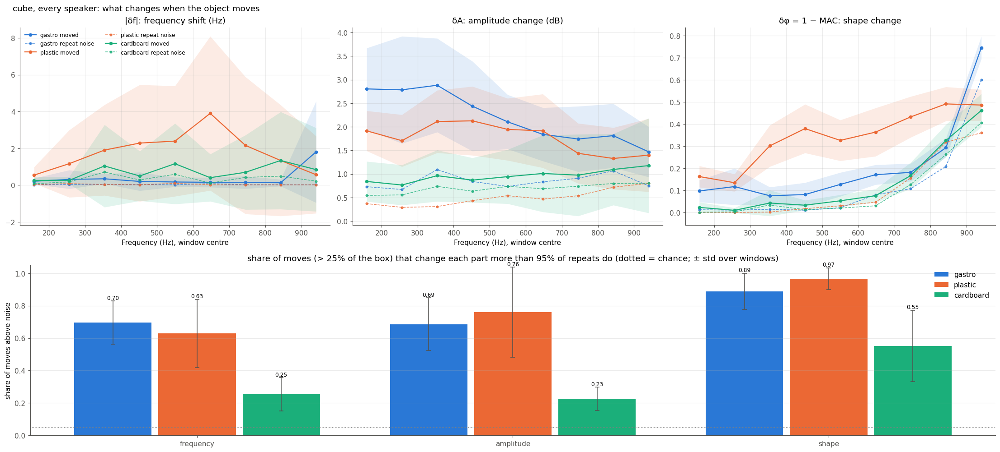

In [21]:
WIN, LAG = np.linspace(13, 1157, 10).astype(int), 13         # 9 windows of ~98 Hz; slide up to ±13 bins = ±10 Hz

def modal(d):
    """per FFT bin: the level l(f) (dB) and the unit-length 200-vector u(f) (lasers x axes)"""
    F_ = D.load_fft(d).numpy()
    X = F_.transpose(1, 0, 2).reshape(F_.shape[1], -1)
    P = (np.abs(X) ** 2).mean(1)
    return (10 * np.log10(P)).astype(np.float32), (X / np.sqrt(P * X.shape[1])[:, None]).astype(np.complex64)

def compare(la, ua, lb, ub):
    """(windows, 3) for one pair: |δf| (Hz), δA (dB), δφ = 1 - MAC"""
    out = []
    for s0, s1 in zip(WIN[:-1], WIN[1:]):
        a = la[s0:s1] - la[s0:s1].mean()
        Wb = np.lib.stride_tricks.sliding_window_view(lb, s1 - s0)[s0 - LAG:s0 + LAG + 1]   # l_b slid by every τ
        Wc = Wb - Wb.mean(1, keepdims=True)
        r = Wc @ a / (np.linalg.norm(Wc, axis=1) * np.linalg.norm(a) + 1e-12)               # correlation per τ
        k = int(np.argmax(r))
        sub = 0.5 * (r[k - 1] - r[k + 1]) / (r[k - 1] - 2 * r[k] + r[k + 1]) if 0 < k < len(r) - 1 and (r[k - 1] - 2 * r[k] + r[k + 1]) < 0 else 0.
        tau = k - LAG
        mac = np.abs(np.einsum('fi,fi->f', ua[s0:s1], ub[s0 + tau:s1 + tau].conj())) ** 2
        out.append((abs(tau + sub) / 1.3, np.sqrt(np.mean((la[s0:s1] - Wb[k]) ** 2)), 1 - mac.mean()))
    return np.array(out)

def compare_pairs(g, n, pairs=None):
    """compare() for every pair of n random captures of g (or for the given index pairs), and each pair's D_pos. Cached"""
    g = g if pairs is not None or len(g) <= n else g.sample(n, random_state=0).reset_index(drop=True)
    def run():
        with ThreadPoolExecutor(8) as ex: M = list(ex.map(modal, g.dir))
        pr = pairs if pairs is not None else list(zip(*np.triu_indices(len(g), 1)))
        return (np.stack([compare(*M[i], *M[j]) for i, j in pr]),
                np.array([np.hypot(g.com_r[i] - g.com_r[j], g.com_c[i] - g.com_c[j]) / np.sqrt(g.H[i] * g.W[i]) for i, j in pr]))
    return cached(f'modes{n}', list(g.dir) + ([str(pairs)] if pairs is not None else []), run)

obj, far = 'cube', .25
fc = (WIN[:-1] + WIN[1:]) / 2 / 1.3 + 100                   # window centres (Hz)
PARTS = ('|δf|: frequency shift (Hz)', 'δA: amplitude change (dB)', 'δφ = 1 − MAC: shape change')
fig = plt.figure(figsize=(20, 9), constrained_layout=True)
top, bottom = fig.subfigures(2, 1, height_ratios=[1.25, 1])
axs, axb = top.subplots(1, 3), bottom.subplots()
for k, b in enumerate(BOXES):
    mv, mvv, nz, nzv, rate = [], [], [], [], []
    for (o, s), g in groups(b, obj).items():
        R, dp = compare_pairs(g, 60)                         # 60 random captures per speaker, every pair
        e = empties(b, s)
        Rn, _ = compare_pairs(e, len(e), back_to_back(e))    # repeat noise
        mv.append(R[dp > far].mean(0)); mvv.append(R[dp > far].var(0)); nz.append(Rn.mean(0)); nzv.append(Rn.var(0))
        rate.append((R[dp > far] > np.percentile(Rn, 95, 0)).mean(0))
    m, sd = pool(mv, mvv)
    nm, _ = pool(nz, nzv)
    for p, ax in enumerate(axs):
        ax.fill_between(fc, m[:, p] - sd[:, p], m[:, p] + sd[:, p], color=COLORS[b], alpha=.13, lw=0)
        ax.plot(fc, m[:, p], 'o-', c=COLORS[b], ms=4, label=f'{b} moved')
        ax.plot(fc, nm[:, p], 'o--', c=COLORS[b], ms=3, lw=1, alpha=.8, label=f'{b} repeat noise')
    share = np.mean(rate, 0)                                 # (windows, 3)
    x = np.arange(3) + (k - 1) * .8 / 3
    axb.bar(x, share.mean(0), .8 / 3 * .92, color=COLORS[b], label=b)
    axb.errorbar(x, share.mean(0), share.std(0), fmt='none', ecolor=MUTED, lw=1, capsize=3)
    for xi, v, s_ in zip(x, share.mean(0), share.std(0)): axb.annotate(f'{v:.2f}', (xi, v + s_), xytext=(0, 2), textcoords='offset points', ha='center', fontsize=8)
for ax, t in zip(axs, PARTS): ax.set(title=t, xlabel='Frequency (Hz), window centre')
axs[0].legend(frameon=False, fontsize=8, ncols=2)
axb.axhline(.05, c='gray', lw=.8, ls=':')
axb.set_xticks(range(3), ['frequency', 'amplitude', 'shape'])
axb.set(ylabel='share of moves above noise', ylim=(0, 1.05), title=f'share of moves (> {far:.0%} of the box) that change each part more than 95% of repeats do (dotted = chance; ± std over windows)')
axb.grid(axis='x', visible=False); axb.legend(frameon=False)
top.suptitle(f'{obj}, every speaker: what changes when the object moves', x=.01, ha='left');
save_fig('fig_mode_changes', 'What changes when an object moves: mode frequency, amplitude and shape.')

**Reading:**
- **Shape changes most reliably:** 89% / 97% / 55% of moves (gastro / plastic / cardboard).
- **Frequency:**
  - gastro's sharp modes shift by ~0.4 Hz (repeats: 0.03 Hz), in 70% of moves;
  - plastic shifts by ~1.8 Hz, but its peaks are broad, so the estimate is looser;
  - in cardboard only 25% of moves stand out, because its repeats already jitter by 0.3 Hz.
- **Amplitude:** 69% / 76% / 23% of moves.
- So moving the cube changes all three parts, the mode shape most. Cardboard changes least in every part.
- Above ~800 Hz even repeats differ in shape (the dashed lines rise): noise dominates there.

### 11 Do the four objects change the box differently?
If a *different* object sits on the same spot, does the box respond differently, or does only the position matter?
- Take two captures whose objects sit at the same spot (centres < 5% of the box apart), with the same speaker.
- **Diagonal** cell = the same object both times (e.g. cube, then cube again at that spot). **Off-diagonal** = two different objects (e.g. cube vs vase).
- **Fair timing.** Each object was recorded in its own 1–2 h session, so two different objects are always ≥ 30 min apart, and the box drifts over time (section 6). So *every* cell uses only pairs recorded 30–120 min apart: the same drift everywhere. The same-object cells exist because each object's grids revisit spots.
- Two measures: the spectral distance (whole spectrum, dB) and the mode-shape change `1 − MAC` (section 10). Light = small, dark = big. Each cell gives mean ± std over pairs, and n = number of pairs.
- Each panel title gives the mean of the same-object cells, the mean of the different-object cells, and the empty box against itself at the same gap (drift alone).

Diagonal ≈ off-diagonal → the box can't tell those objects apart, only where they are. Off-diagonal bigger → the objects change the box differently.

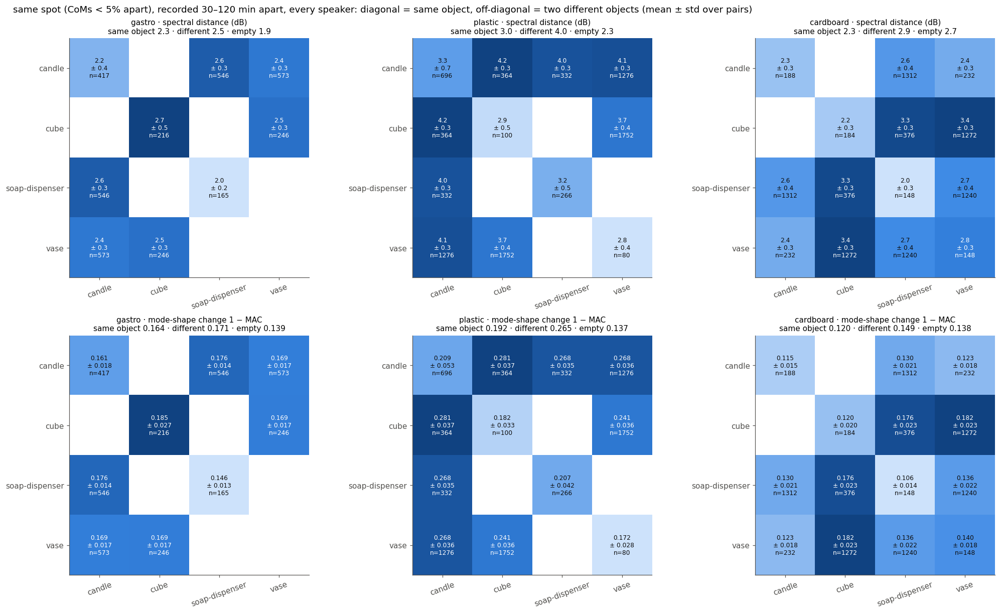

In [22]:
near, gap, n, min_n = .05, (30, 120), 150, 10                # same spot = CoMs < 5% apart; pairs 30-120 min apart; 150 captures per object & speaker
res = {}
for b in BOXES:
    acc = {}
    for s in sorted(set(cap[(cap.box == b) & cap.split.isin(OBJECTS)].speaker)):
        g = pd.concat([cap[(cap.box == b) & (cap.split == o) & (cap.speaker == s)].pipe(lambda x: x.sample(min(n, len(x)), random_state=0)) for o in OBJECTS]).reset_index(drop=True)
        r, c, size = g.com_r.to_numpy(float), g.com_c.to_numpy(float), np.sqrt(g.H * g.W).to_numpy(float)
        t = np.array([x.timestamp() for x in g.t]) / 60
        iu = np.triu_indices(len(g), 1)
        ok = (np.hypot(r[:, None] - r, c[:, None] - c)[iu] / size[iu[0]] < near) & (np.abs(t[:, None] - t)[iu] >= gap[0]) & (np.abs(t[:, None] - t)[iu] <= gap[1])
        pr = [(int(i), int(j)) for i, j in zip(iu[0][ok], iu[1][ok])]
        if not pr: continue
        R, _ = compare_pairs(g, len(g), pr)
        x = spectra(g)[0]
        for (i, j), sh in zip(pr, R[:, :, 2].mean(1)):
            acc.setdefault((s, *sorted((g.split[i], g.split[j]), key=OBJECTS.index)), []).append((d_spec(x[i:i + 1], x[j:j + 1])[0, 0], sh))
        e = empties(b, s)                                   # drift alone: the empty box against itself at the same gap
        te = np.array([x.timestamp() for x in e.t]) / 60
        pe = [(i, j) for i in range(len(e)) for j in range(i + 1, len(e)) if gap[0] <= abs(te[i] - te[j]) <= gap[1]]
        if pe:
            Re, _ = compare_pairs(e, len(e), pe)
            xe = spectra(e)[0]
            acc[s, 'empty', 'empty'] = [(d_spec(xe[i:i + 1], xe[j:j + 1])[0, 0], sh) for (i, j), sh in zip(pe, Re[:, :, 2].mean(1))]
    rows = []
    for o1, o2 in dict.fromkeys(k[1:] for k in acc):        # per object pair: mean over speakers ± pooled std over pairs
        v = [np.array(acc[k]) for k in acc if k[1:] == (o1, o2)]
        m, sd = pool([x.mean(0) for x in v], [x.var(0) for x in v])
        rows.append(dict(a=o1, b=o2, d_spec=m[0], d_spec_std=sd[0], shape=m[1], shape_std=sd[1], n=sum(len(x) for x in v)))
    res[b] = pd.DataFrame(rows)

fig, axs = plt.subplots(2, len(BOXES), figsize=(18.6, 11), constrained_layout=True)
for col, b in enumerate(BOXES):
    emp, r = res[b][res[b].a == 'empty'], res[b][(res[b].a != 'empty') & (res[b].n >= min_n)]
    for row, (f, lab, fmt) in enumerate((('d_spec', 'spectral distance (dB)', '.1f'), ('shape', 'mode-shape change 1 − MAC', '.3f'))):
        ax, M = axs[row, col], np.full((4, 4), np.nan)
        for _, q in r.iterrows(): M[OBJECTS.index(q.a), OBJECTS.index(q.b)] = M[OBJECTS.index(q.b), OBJECTS.index(q.a)] = q[f]
        lo, hi = np.nanmin(M), np.nanmax(M)
        ax.imshow(M, cmap=BLUES, vmin=lo, vmax=hi)
        for _, q in r.iterrows():
            for y, x_ in {(OBJECTS.index(q.a), OBJECTS.index(q.b)), (OBJECTS.index(q.b), OBJECTS.index(q.a))}:
                ax.text(x_, y, f'{q[f]:{fmt}}\n± {q[f + "_std"]:{fmt}}\nn={q.n}', ha='center', va='center', fontsize=8, color='white' if (q[f] - lo) / max(hi - lo, 1e-9) > .55 else INK)
        e = f'empty {emp[f].iloc[0]:{fmt}}' if len(emp) else 'no empty pairs at this gap'
        ax.set_xticks(range(4), OBJECTS, rotation=20); ax.set_yticks(range(4), OBJECTS); ax.grid(False)
        ax.set_title(f'{b} · {lab}\nsame object {r[r.a == r.b][f].mean():{fmt}} · different {r[r.a != r.b][f].mean():{fmt}} · {e}', fontsize=10)
fig.suptitle(f'same spot (CoMs < {near:.0%} apart), recorded {gap[0]}–{gap[1]} min apart, every speaker: diagonal = same object, off-diagonal = two different objects (mean ± std over pairs)', x=.01, ha='left');
save_fig('fig_objects_same_spot', 'Different objects at the same spot: spectral distance and mode-shape change, per box.')

**Reading:**
- **Plastic: yes, the objects change the box differently.** Two different objects at the same spot differ by 3.7–4.2 dB (mode shape 0.24–0.28), against 2.8–3.3 dB (0.17–0.21) for the same object back at that spot. Both are well above the empty box's drift at the same gap (2.34 dB, 0.137).
- **Cardboard: only the cube stands apart.** Cube vs any other object: 3.3–3.4 dB (shape 0.18). Candle, soap dispenser and vase look alike: 2.4–2.7 dB between them, about the same as one object against itself (2.0–2.8). Caveat: the cube was the first session of the day, when nb99 found the setup still drifting.
- **Gastro: small differences.** Different objects 2.48 dB vs same object 2.27 (shape 0.171 vs 0.164). Several cells are blank: the gastro sessions are far apart (cube vs candle ≈ 4 h), and its vase grid never revisits a spot after 30 min.
- So the answer depends on the box. In plastic each object leaves its own fingerprint; in gastro and (apart from the cube) cardboard, the box mostly tells *where* the mass is, not *what* it is.
- The gap is matched (30–120 min), not identical. A perfectly fair test would record the objects interleaved at the same spots.

### 12 The box's own resonances
Which resonances belong to the box, there no matter where the object is? Per (object, speaker) and per FFT bin (0.77 Hz):
- **peaks** are picked as in viz2: on `σ(f)` = the std of `|X|` across the 200 laser channels (a real mode is where the lasers *disagree*), smoothed over 5 Hz, with a prominence ≥ 4 × the robust (MAD) noise of its residual from a 25 Hz baseline, and ≥ 5 Hz apart;
- **occurrence** = the share of captures with such a peak within ±2.3 Hz;
- **σ_pos** = std of `l(f)` over the captures (i.e. over positions);
- **σ_rep** = the same std over back-to-back empty captures (repeat noise).

These are averaged over groups. A **box resonance** = a peak of the group-mean `σ(f)` that occurs in ≥ 80% of captures. Its **jitter** = the std of the nearest peak's frequency over captures. Top of each pair: mean level ± σ_pos, with the box resonances as dots. Bottom: σ_pos (solid) vs σ_rep (dashed), with the occurrence in grey on the right axis.

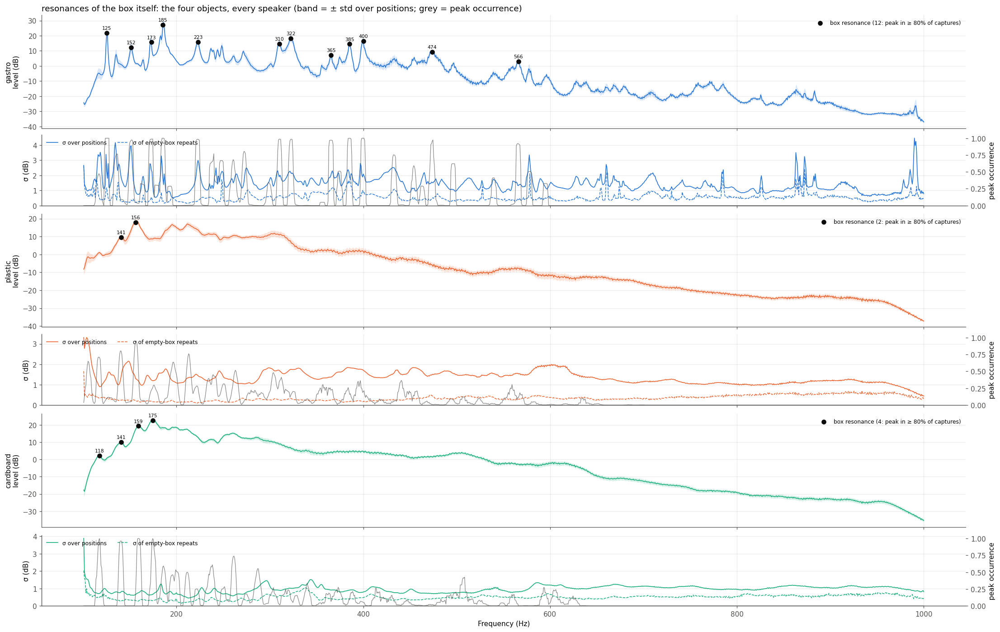

,resonances,jitter_hz,sigma_pos,sigma_rep
box,,,,
cardboard,4,1.00,0.73,0.34
gastro,12,0.58,2.19,0.71
plastic,2,1.05,1.36,0.22


,box,f0,level,occurrence,jitter_hz,sigma_pos,sigma_rep
0,gastro,125.38,21.76,1.00,0.28,2.27,1.16
1,gastro,151.54,12.29,0.97,0.63,3.95,0.37
2,gastro,173.08,15.70,0.99,0.52,2.36,0.56
3,gastro,185.38,27.11,1.00,0.63,1.85,0.32
4,gastro,223.08,15.81,0.98,0.53,2.99,0.32
5,gastro,310.00,14.69,0.99,0.76,1.90,0.65
6,gastro,322.31,18.26,0.98,0.74,2.19,0.76
7,gastro,365.38,7.30,0.97,0.34,2.02,1.06
8,gastro,385.38,14.50,1.00,0.48,1.85,1.58
9,gastro,400.00,16.56,1.00,0.48,2.09,0.87


In [23]:
tol, min_occ = 3, .8                                          # a peak within ±3 bins (±2.3 Hz); a box resonance is in >= 80% of captures

def peaks(sig, k_prom=4., distance_hz=5., smooth_hz=5., baseline_hz=25.):
    """as viz2.data.peaks: peaks of σ(f), savgol-smoothed, prominence >= k_prom x the MAD of its residual from a baseline smooth"""
    nb = lambda hz: max(1, int(round(hz * 1.3)))
    odd = lambda n: n + 1 - n % 2
    sig = savgol_filter(sig, odd(2 * nb(smooth_hz) + 1), 3)
    r = sig - savgol_filter(sig, odd(2 * nb(baseline_hz) + 1), 3)
    return find_peaks(sig, distance=nb(distance_hz), prominence=max(1e-12, k_prom * 1.4826 * np.median(np.abs(r - np.median(r)))), wlen=odd(2 * nb(baseline_hz) + 1))[0]

def levels(g):
    """(captures, 1170) level l(f) per FFT bin. Cached"""
    def run():
        with ThreadPoolExecutor(8) as ex: return np.stack(list(ex.map(lambda d: modal(d)[0], g.dir))).astype(np.float16)
    return cached('level', list(g.dir), run).astype(np.float32)

def sigmas(g):
    """(captures, 1170) σ(f) = std of |X| over the 200 laser channels. Cached"""
    one = lambda d: np.abs(D.load_fft(d).numpy()).transpose(1, 0, 2).reshape(1170, -1).std(1)
    def run():
        with ThreadPoolExecutor(8) as ex: return np.stack(list(ex.map(one, g.dir))).astype(np.float32)
    return cached('sigma', list(g.dir), run)

curves, rows = {}, []
for b in BOXES:
    M, Vp, O, P, Vr, Sg = [], [], [], [], [], []
    for (o, s), g in groups(b).items():
        L, sig = levels(g), sigmas(g)
        pk = [peaks(x) for x in sig]
        hit = np.zeros(L.shape, np.uint8)
        for i, p in enumerate(pk): hit[i, p] = 1
        O.append(maximum_filter1d(hit, 2 * tol + 1, axis=1).mean(0)); M.append(L.mean(0)); Vp.append(L.var(0)); P += pk; Sg.append(sig.mean(0))
        e = empties(b, s)
        Le = levels(e)
        Vr.append(np.mean([Le[ix].var(0) for ix in e.groupby('layout').indices.values()], 0))
    lvl, sp = pool(M, Vp)
    occ, sr = np.mean(O, 0), np.sqrt(np.mean(Vr, 0))
    curves[b] = dict(level=lvl, sigma_pos=sp, sigma_rep=sr, occurrence=occ)
    for k in peaks(np.mean(Sg, 0)):
        if occ[k] < min_occ: continue
        near = [F[p[np.argmin(np.abs(p - k))]] for p in P if len(p) and np.min(np.abs(p - k)) <= tol]
        rows.append(dict(box=b, f0=F[k], level=lvl[k], occurrence=occ[k], jitter_hz=np.std(near), sigma_pos=sp[k], sigma_rep=sr[k]))
res = pd.DataFrame(rows).astype({k: float for k in ('f0', 'level', 'occurrence', 'jitter_hz', 'sigma_pos', 'sigma_rep')}).round(2)

fig, axs = plt.subplots(6, 1, figsize=(20, 12.6), sharex=True, gridspec_kw=dict(height_ratios=[1.6, 1] * 3), constrained_layout=True)
for i, b in enumerate(BOXES):
    c, r = curves[b], res[res.box == b]
    ax, ax2 = axs[2 * i], axs[2 * i + 1]
    ax.fill_between(F, c['level'] - c['sigma_pos'], c['level'] + c['sigma_pos'], color=COLORS[b], alpha=.18, lw=0)
    ax.plot(F, c['level'], c=COLORS[b], lw=1.1)
    ax.scatter(r.f0, r.level, s=36, c=INK, zorder=3, label=f'box resonance ({len(r)}: peak in ≥ {min_occ:.0%} of captures)')
    for _, q in r.iterrows(): ax.annotate(f'{q.f0:.0f}', (q.f0, q.level), xytext=(0, 5), textcoords='offset points', ha='center', fontsize=7)
    ax.set(ylabel=f'{b}\nlevel (dB)'); ax.legend(frameon=False, loc='upper right', fontsize=8)
    ax2.plot(F, c['sigma_pos'], c=COLORS[b], lw=1.1, label='σ over positions')
    ax2.plot(F, c['sigma_rep'], c=COLORS[b], lw=1, ls='--', label='σ of empty-box repeats')
    ax2.set(ylabel='σ (dB)', ylim=(0, None)); ax2.legend(frameon=False, loc='upper left', fontsize=8, ncols=2)
    tw = ax2.twinx(); tw.plot(F, c['occurrence'], c=MUTED, lw=.8, alpha=.7); tw.set(ylim=(0, 1.05), ylabel='peak occurrence'); tw.grid(False)
axs[0].set_title('resonances of the box itself: the four objects, every speaker (band = ± std over positions; grey = peak occurrence)', loc='left')
axs[-1].set_xlabel('Frequency (Hz)')
save_fig('fig_box_resonances', "The box's own resonances: level, spread over positions and peak occurrence.")
plt.show()
display(save_table(res.groupby('box').agg(resonances=('f0', 'size'), jitter_hz=('jitter_hz', 'mean'), sigma_pos=('sigma_pos', 'mean'), sigma_rep=('sigma_rep', 'mean')).round(2), 'tab_box_resonances_summary', 'Box resonances per box', 2))
save_table(res, 'tab_box_resonances', 'Box resonances', 2)

**Reading:**
- **Gastro has 12 box resonances** (125, 152, 173, 185, 223, 310, 322, 365, 385, 400, 474 and 566 Hz), each present in 92–100% of captures.
  - They barely move: the jitter is 0.3–1.1 Hz, against peaks spaced 10–40 Hz apart.
  - Their *level* changes with position: σ_pos ≈ 2.2 dB on average, against σ_rep ≈ 0.7 dB for repeats.
  - So the object changes how strongly each fixed mode is driven more than where it sits in frequency.
- **Cardboard has 4, all low** (118, 141, 159, 175 Hz). **Plastic has 2** (141 and 156 Hz). Above ~200 Hz neither has a peak that comes back in most captures: their spectra are a smooth slope with broad humps, and where a capture does have a peak, it moves between positions (occurrence ≲ 0.5).
- σ_pos is above σ_rep at almost every frequency in every box: position changes the level everywhere, not only at the resonances. In gastro, σ_pos peaks *at* the resonances; in plastic and cardboard it is spread across the band.
- Together with section 10: in the stiff steel box, the object re-weights and slightly shifts a fixed set of sharp modes. In the damped boxes there are few stable modes to track, and the position information is in the mode shape.

## Part II · The run
### 1 Load

In [24]:
ID = D.PAPER_ID                                               # the 6 in-distribution splits
OOD = ['unseen-position', 'unseen-speaker', 'unseen-object', 'unseen-rotation', 'unseen-laser', 'lid', 'broken']   # never trained on at all
NAMES = {'id': 'in distribution', 'unseen-position': 'unseen position', 'unseen-speaker': 'unseen speaker', 'unseen-object': 'unseen object',
         'unseen-rotation': 'unseen rotation', 'weight': 'weight', 'unseen-laser': 'unseen speckles', 'lid': 'lid on', 'broken': 'broken object'}
METRICS = {'iou': 'IoU ↑', 'miss': 'Miss rate ↓', 'com_err': 'Centroid error (% of box) ↓'}
LOWER = ('miss', 'com_err')                                   # lower is better
NO_TWIN = ('2026_09_27_gastronorm_four_objs', (1254, 1255))   # gastro lid pair: 1255 has no without-lid mask (dataset.paper drops it too)
args = json.loads((ROOT / 'runs' / RUN / 'args.json').read_text())
EPOCH = EPOCH or S.last_epoch(RUN)
layout_of = {e: {m['position_id']: m['layout'] for d in (D.EXPERIMENTS / e / 'samples').iterdir() if (d / 'metadata.jsonl').exists() for m in [D.load_meta(d)]}
             for e in cap.experiment.unique()}

def score_mask(p, y, thr):
    b, obj = p > thr, y > 0.5
    (br, bc), (rr, cc), (H, W) = np.nonzero(b), np.nonzero(obj), p.shape
    return dict(iou=(b & obj).sum() / max((b | obj).sum(), 1), miss=float(not (b & obj).any()),
                com_err=np.hypot((br.mean() - rr.mean()) / H, (bc.mean() - cc.mean()) / W) if len(br) and len(rr) else np.nan)

# eval samples, scored, with the aux heads (in score.per_sample's order: the same files, sorted)
ev = S.per_sample(RUN, EPOCH, [THR]).rename(columns=lambda c: c.replace(f'@{THR}', ''))
heads = []
for f in sorted((ROOT / 'runs' / RUN / 'outputs_history/eval').glob(f'*/*/ep{EPOCH:04d}-ba*.pt')):
    d = torch.load(f, weights_only=False, map_location='cpu')
    m, conf = d['metrics'], d['object_logits'].float().softmax(-1).max(-1).values
    heads += [dict(file=str(f), idx=i, sample_id=d['info']['sample_id'][i], obj_conf=float(conf[i]), object_acc=float(m['object_acc'][i]),
                   count_acc=float(m['n_objects_err'][i] == 0), box_acc=float(m['box_acc'][i]), com_head_err=100 * float(m['com_err'][i]),
                   area_err=float(m['area_rel_err'][i])) for i in range(len(conf))]
ev = pd.concat([ev, pd.DataFrame(heads)], axis=1).assign(set='eval')

# the id splits' train samples, scored like eval (the train evaluator: no augmentation). Cached
f = ROOT / 'runs' / RUN / 'scores' / f'paper_train_ep{EPOCH:04d}_{THR}.pkl'
if f.exists(): tr = pd.read_pickle(f)
else:
    split_of = {(e, l): (b, s) for e, l, b, s in zip(ev.experiment, ev.layout, ev.box, ev.split) if s in ID}
    rows = []
    for g in sorted((ROOT / 'runs' / RUN / 'outputs_history/train').glob(f'ep{EPOCH:04d}-ba*.pt')):
        d = torch.load(g, weights_only=False, map_location='cpu')
        p, info = d['mask_pred'].float().numpy(), d['info']
        for i in range(len(p)):
            e, sid, pos, spk = info['experiment'][i], info['sample_id'][i], int(info['position_id'][i]), int(info['speaker'][i])
            if (e, layout_of[e][pos]) not in split_of: continue
            b, s = split_of[e, layout_of[e][pos]]
            rows.append(dict(box=b, split=s, layout=layout_of[e][pos], experiment=e, position_id=pos, speaker=spk, set='train') | score_mask(p[i], S.truth(e, sid, pos, spk, *p.shape[-2:]), THR))
    tr = pd.DataFrame(rows); f.parent.mkdir(parents=True, exist_ok=True); tr.to_pickle(f)

df = pd.concat([ev, tr], ignore_index=True)
df['com_err'] *= 100
df = df[~((df.experiment == NO_TWIN[0]) & df.position_id.isin(NO_TWIN[1]))].copy()
df['category'] = df.split.map(D.PAPER_CATEGORY)
# an object question (unseen object, broken) only counts if the run never trained on that object; the weight trend is the opposite
trained = {(e, layout_of[e][p]) for e, p in pd.read_csv(ROOT / 'runs' / RUN / 'positions/train.txt', sep=' ', names=['e', 'p']).itertuples(index=False)}
splits = D.DATASETS[args['dataset']](args['test_size'], None if 'all' in args['speakers'] else tuple(args['speakers']))
seen_splits = {tuple(k.split('/')) for k, sp in splits.items() if any((sp['experiment'], l) in trained for l in sp['layouts'])}
seen = pd.Series([k in seen_splits for k in zip(df.box, df.split)], index=df.index)
df.loc[df.category.isin(('unseen-object', 'broken')) & seen | (df.category == 'weight') & ~seen, 'category'] = None
df['mass'] = df.split.str.extract(r'cylinder-(\d+)g', expand=False).astype(float)

trpos = pd.read_csv(ROOT / 'runs' / RUN / 'positions/train.txt', sep=' ', names=['experiment', 'position_id'])
print(f'{RUN} @ epoch {EPOCH}:', df.set.value_counts().to_dict())

s8-mag-nopose-imom-w-500ep @ epoch 500: {'train': 10676, 'eval': 4638}


### 2 Table 1: in distribution
Tables 1a–c: one per box, VibroFormer on the held-out positions of each trained object (rows = metrics, shaded along each row: the easiest object in bold). Table 1d (section 3) compares it with the nearest-neighbour baselines, averaged over every object and box.

In [25]:
# every table holds means and stds side by side (columns 'mean' / 'std'); style() shows "mean ±std", shaded by how good, best in
# bold; to_latex() writes the same table for the paper (show() does both); bars() draws it as a bar plot (one bar per box, n train / n test under each)

def mean_std(d, metric):
    """mean over splits (every split counts once), std over samples"""
    v = d[metric].dropna()
    return (d.groupby(['box', 'split'])[metric].mean().mean(), v.std()) if len(v) else (np.nan, np.nan)

def pick(d, box, col, field):
    return d[d.box.isin(BOXES if box == 'all' else [box]) & (d[field].isin(ID if col == 'eval' else [col]) if field == 'split' else (d[field] == col))]

def make_table(cells, metric, **attrs):
    """{(row, col): (mean, std)} -> columns mean / std"""
    rows, cols = list(dict.fromkeys(r for r, _ in cells)), list(dict.fromkeys(c for _, c in cells))
    t = pd.concat({k: pd.DataFrame([[cells[r, c][i] for c in cols] for r in rows], index=pd.MultiIndex.from_tuples(rows) if isinstance(rows[0], tuple) else rows, columns=cols)
                   for i, k in enumerate(('mean', 'std'))}, axis=1)
    if isinstance(cols[0], tuple): t.columns = pd.MultiIndex.from_tuples([(k, *c) for k, c in t.columns])
    t.attrs.update(metric=metric, lower=metric in LOWER, **attrs)
    return t

def auroc(neg, pos): return (pos[:, None] > neg[None]).mean() + 0.5 * (pos[:, None] == neg[None]).mean()   # P(pos above neg), ties half

LIGHT = LinearSegmentedColormap.from_list('light', ['#ffffff', '#cde2fb', '#86b6ef'])
RULE = f'2.5px solid {INK}'
CSS = [{'selector': '', 'props': 'border-collapse: collapse; font-family: system-ui, -apple-system, sans-serif; font-size: 13px; color: #0b0b0b'},
       {'selector': 'th, td', 'props': 'padding: 5px 12px; text-align: center; white-space: nowrap; border: none'},
       {'selector': 'th.col_heading.level0', 'props': f'font-size: 14px; font-weight: 600; border-bottom: 1px solid {MUTED}; padding-bottom: 7px'},
       {'selector': 'thead tr:last-child th', 'props': f'border-bottom: {RULE}; font-weight: 600'},
       {'selector': 'th.row_heading', 'props': 'text-align: left; font-weight: 600'},
       {'selector': 'tbody tr:last-child td, tbody tr:last-child th', 'props': f'border-bottom: {RULE}'},
       {'selector': 'td.col0, th.col_heading.level1.col0, th.col_heading.level0.col0', 'props': f'border-left: {RULE}'}]

def style(t, axis=0, color=True, latex=False):
    """"mean ±std"; color: best along axis (0: down each column, 1: along each row) in bold, and with SHADE every cell shaded by how good it is.
    Lower is better for the whole table (t.attrs['lower']) or for any row / column whose label has a ↓ (tables that mix metrics)"""
    m, s = t['mean'], t['std']
    down = lambda l: '↓' in str(l)
    def fmt(r, c): return '.1f' if t.attrs.get('metric') == 'com_err' or 'Centroid' in str(r) + str(c) else '.3f'
    def cell(a, b, f):
        if pd.isna(a): return '—'
        if pd.isna(b): return f'{a:{f}}'
        return f'{a:{f}} {{\\scriptsize $\\pm${b:{f}}}}' if latex else f"{a:{f}} <span style='font-size:72%'>±{b:{f}}</span>"
    text = pd.DataFrame([[cell(a, b, fmt(r, c)) for a, b, c in zip(ra, rb, m.columns)] for r, ra, rb in zip(m.index, m.values, s.values)], index=m.index, columns=m.columns)
    css = pd.DataFrame('', index=m.index, columns=m.columns)
    if color:
        sign = -1. if t.attrs.get('lower') else np.where([down(r) for r in m.index], -1., 1.)[:, None] * np.where([down(c) for c in m.columns], -1., 1.)[None]
        g = (m * sign).astype(float)
        skip = {'all', 'mean', *t.attrs.get('skip', ())}                                    # averages, and columns not compared (attrs['skip'])
        avg = lambda l: bool(skip & set(np.atleast_1d(l)))
        g = g.loc[[i for i in g.index if not avg(i)], [c for c in g.columns if not avg(c)]]
        if t.attrs.get('blocks'):                                                          # compare within each outer row label (e.g. per box)
            lo, hi = g.groupby(level=0).transform('min'), g.groupby(level=0).transform('max')
            z, best = (g - lo) / (hi - lo).replace(0, np.nan), g.eq(hi) & (hi > lo)
        else:
            lo, hi = g.min(axis=axis), g.max(axis=axis)
            z = g.sub(lo, axis=1 - axis).div((hi - lo).replace(0, np.nan), axis=1 - axis)
            varies = (hi > lo).to_numpy()
            best = g.eq(hi, axis=1 - axis) & (varies[:, None] if axis == 1 else varies[None, :])
        css = (z.map(lambda v: '' if pd.isna(v) or not SHADE else f'background-color: {to_hex(LIGHT(v))};') + np.where(best, ' font-weight: bold;', '')).reindex_like(m).fillna('')
    st = text.style.apply(lambda _: css.to_numpy(), axis=None)
    if latex: return st
    lines = [{'selector': f'td.col{j}, th.col_heading.level{m.columns.nlevels - 1}.col{j}', 'props': f'border-left: {RULE}'} for j in t.attrs.get('vlines', ())]
    if isinstance(m.index, pd.MultiIndex):
        lines += [{'selector': f'td.row{i}, th.row_heading.level1.row{i}, th.row_heading.level0.row{i}', 'props': f'border-top: {RULE}'}
                  for i in range(1, len(m)) if m.index[i][0] != m.index[i - 1][0]]
    return st.set_table_styles(CSS + lines)

def to_latex(t, name, caption, **kw):
    """the styled table as LaTeX in TABLES/<NN>_<name>.tex (label tab:...) (\\usepackage[table]{xcolor}, booktabs, multirow, array): same shading and bold as style()"""
    thick, n_idx = '!{\\vrule width 1.2pt}', t.index.nlevels
    cols = ''.join(thick * (j in t.attrs.get('vlines', ())) + 'c' for j in range(t['mean'].shape[1]))
    out = style(t, latex=True, **kw).to_latex(convert_css=True, hrules=True, multirow_align='t', multicol_align='c', caption=caption, label=label(name),
                                              column_format='l' * n_idx + thick + cols, clines='skip-last;data' if n_idx > 1 else None)
    (TABLES / f'{stem(name)}.tex').write_text(tex(out).replace('%', '\\%'))

def show(t, name, caption, **kw):
    """display the styled table and save it as TABLES/<NN>_<name>.tex"""
    to_latex(t, name, caption, **kw)
    display(style(t, **kw).set_caption(caption))

def bars(field, cols, metric, ylabel, title, labels=None, figsize=(14, 4.8)):
    """one bar per (column, box): mean over splits, ±1 std whisker, value on the bar, n train / n test under it"""
    e_, t_ = df[df.set == 'eval'], df[df.set == 'train']
    rows = []
    for x, c in enumerate(cols):
        for b in BOXES:
            e = pick(t_, b, 'eval', field) if c == 'train' else pick(e_, b, c, field)
            if metric == 'novelty':                          # against the same box's in-distribution samples
                ref = e_[(e_.box == b) & (e_.category == 'id')].obj_conf.to_numpy()
                ms = (auroc(1 - ref, 1 - e.obj_conf.to_numpy()), np.nan) if len(e) and c != 'id' else (np.nan, np.nan)
            else: ms = mean_std(e, metric)
            rows.append(dict(x=x, box=b, mean=ms[0], std=ms[1], n_train=len(e) if c == 'train' else len(pick(t_, b, c, field)), n_test=0 if c == 'train' else len(e)))
    t = pd.DataFrame(rows)
    fig, ax = plt.subplots(figsize=figsize)
    bounded = metric in ('iou', 'miss', 'object_acc', 'count_acc', 'novelty')
    f = '.1f' if metric.startswith(('com_err', 'com_head_err', 'orient_err')) else '.2f'
    for k, b in enumerate(BOXES):
        tb = t[(t.box == b) & t['mean'].notna()]
        x, m, sd = tb.x + (k - 1) * .8 / 3, tb['mean'], tb['std'].fillna(0)
        ax.bar(x, m, .8 / 3 * .92, color=COLORS[b], label=b)
        ax.errorbar(x, m, yerr=[np.minimum(sd, m), np.minimum(sd, 1 - m) if bounded else sd], fmt='none', ecolor=MUTED, elinewidth=1, capsize=3, capthick=1)
        for xi, v, s in zip(x, m, tb['std']):
            inside = v > 0.18 * (1 if bounded else t['mean'].max())
            ax.annotate(f'{v:{f}}' + ('' if pd.isna(s) else f'\n±{s:{f}}'), (xi, v), xytext=(0, -3 if inside else 3), textcoords='offset points', ha='center', va='top' if inside else 'bottom', fontsize=6.5, color=INK, zorder=5)
        for xi, a, n in zip(x, tb.n_train, tb.n_test):
            ax.annotate(f'tr {a}' + (f'\nte {n}' if n else ''), (xi, 0), xytext=(0, -4), textcoords='offset points', ha='center', va='top', fontsize=6, color=MUTED)
    ax.set_xticks(range(len(cols)), labels or cols, fontsize=9); ax.tick_params(axis='x', pad=26, length=0)
    ax.set_ylabel(ylabel); ax.grid(axis='x', visible=False); ax.set_axisbelow(True); ax.margins(y=0.1)
    ax.legend(frameon=False, bbox_to_anchor=(1.01, 1), loc='upper left')
    ax.set_title(title, loc='left', fontweight='bold')
    return ax

,candle,cube,soap-dispenser,vase,two-cubes,cube-vase,mean
IoU ↑,0.837 ±0.078,0.572 ±0.167,0.759 ±0.111,0.796 ±0.120,0.360 ±0.170,0.351 ±0.132,0.612 ±0.197
Miss rate ↓,0.000 ±0.000,0.007 ±0.082,0.000 ±0.000,0.000 ±0.000,0.000 ±0.000,0.000 ±0.000,0.001 ±0.038
Centroid error (% of box) ↓,1.2 ±0.9,2.5 ±5.0,1.2 ±0.7,1.2 ±1.1,6.4 ±5.3,9.4 ±3.4,3.7 ±3.5


,candle,cube,soap-dispenser,vase,two-cubes,cube-vase,mean
IoU ↑,0.813 ±0.105,0.665 ±0.126,0.803 ±0.089,0.815 ±0.092,0.423 ±0.157,0.458 ±0.132,0.663 ±0.163
Miss rate ↓,0.000 ±0.000,0.000 ±0.000,0.000 ±0.000,0.000 ±0.000,0.000 ±0.000,0.000 ±0.000,0.000 ±0.000
Centroid error (% of box) ↓,1.6 ±1.1,1.3 ±0.8,1.1 ±0.7,1.2 ±0.9,6.1 ±5.9,10.2 ±5.3,3.6 ±2.9


,candle,cube,soap-dispenser,vase,two-cubes,cube-vase,mean
IoU ↑,0.831 ±0.074,0.542 ±0.218,0.699 ±0.131,0.780 ±0.103,0.382 ±0.174,0.476 ±0.165,0.618 ±0.207
Miss rate ↓,0.000 ±0.000,0.031 ±0.174,0.000 ±0.000,0.000 ±0.000,0.000 ±0.000,0.000 ±0.000,0.005 ±0.082
Centroid error (% of box) ↓,1.5 ±0.9,3.1 ±2.7,2.1 ±1.4,1.6 ±1.1,5.2 ±4.5,10.2 ±8.0,3.9 ±3.8


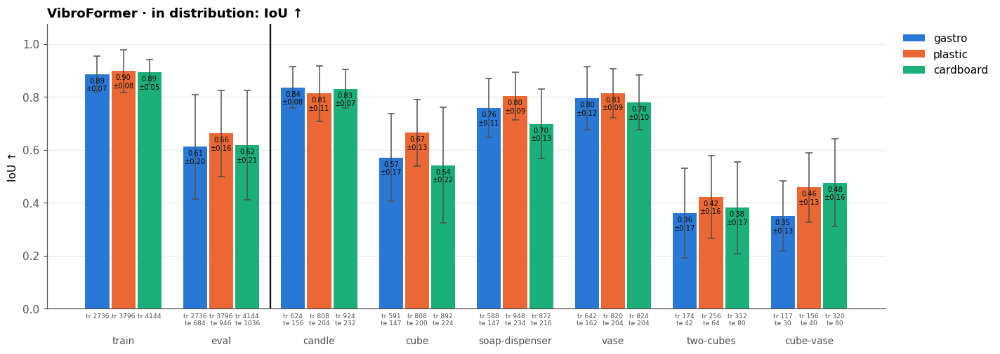

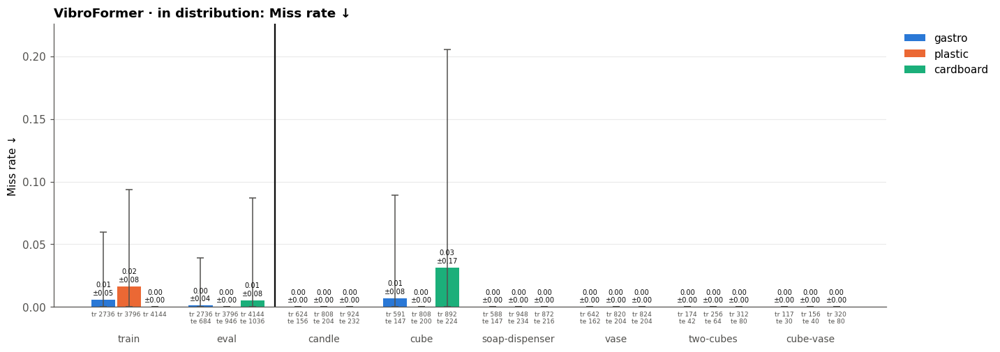

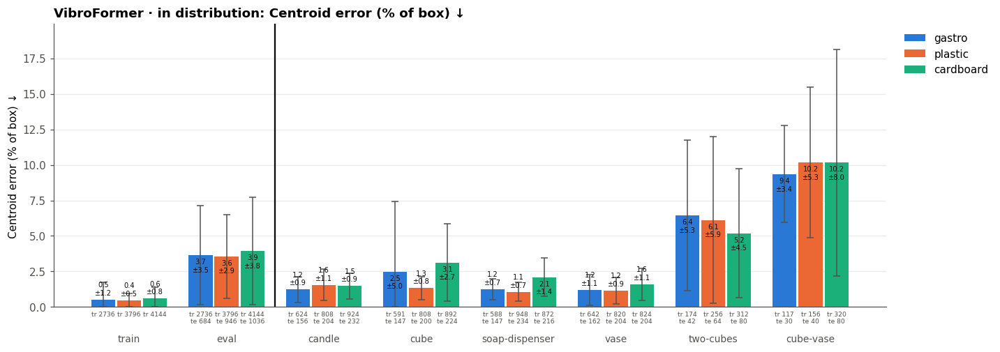

In [26]:
captions = {'iou': 'IoU', 'miss': 'miss rate', 'com_err': 'CoM error (\\% of box)'}
e = df[df.set == 'eval']
for b in BOXES:
    cells = {}
    for metric in METRICS:
        cells |= {(METRICS[metric], c): mean_std(pick(e, b, c, 'split'), metric) for c in ID} | {(METRICS[metric], 'mean'): mean_std(pick(e, b, 'eval', 'split'), metric)}
    t = make_table(cells, 'per-object', vlines=(len(ID),))
    show(t, f'tab_id_{b}', f'In distribution, {b}: VibroFormer per object, on the held-out positions of trained objects', axis=1)
for metric in METRICS:
    bars('split', ['train', 'eval'] + ID, metric, METRICS[metric], f'VibroFormer · in distribution: {METRICS[metric]}').axvline(1.5, color=INK, lw=1.5)
    save_fig(f'fig_id_{metric}', f'In distribution, {captions[metric]} per object and box.')
    plt.show()

#### 2.1 Centroid error in x and in y
The centroid error of Table 1, split into its two directions, in distribution only (the six Table 1 splits, held-out positions).
- **x** = across the floor, parallel to the laser wall: `|col_pred − col_true|`.
- **y** = toward or away from the laser wall (the lasers sit on the bottom wall): `|row_pred − row_true|`.
- Both are in % of the box, from the predicted mask (`p > THR`) and the true mask, like Table 1's centroid error (its hypotenuse).
- Bars: mean over splits, whisker ±1 std over samples; `te` = test samples.

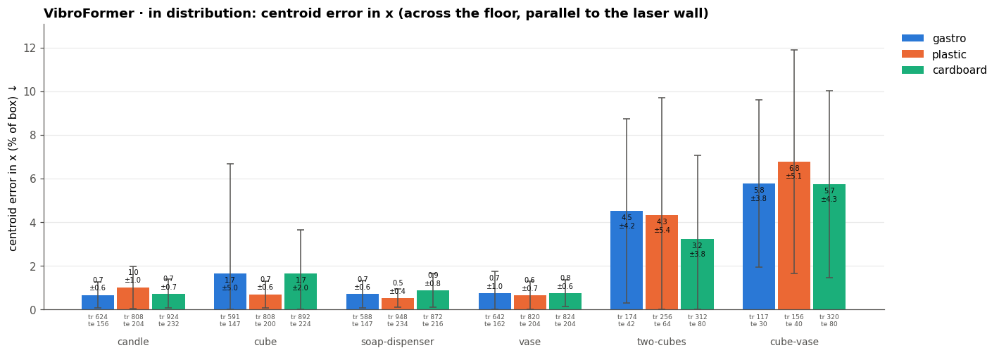

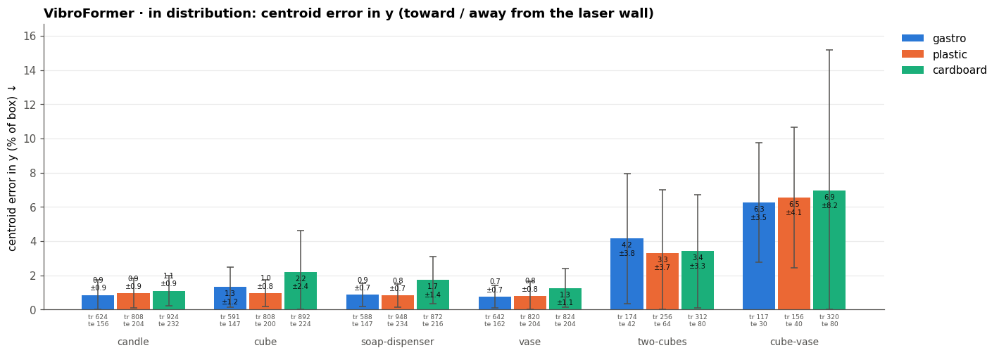

,com_err_x,com_err_y,com_err
box,,,
gastro,1.37,1.37,2.16
plastic,1.21,1.28,1.97
cardboard,1.54,2.13,2.94


In [27]:
def xy_error(mask, row, col):
    """|Δcol|, |Δrow| (% of box) between the predicted mask's centroid and the true one (row, col: box fractions, as score.py)"""
    br, bc = np.nonzero(mask)
    if not len(br): return np.nan, np.nan
    return 100 * abs((bc.mean() + .5) / mask.shape[1] - col), 100 * abs((br.mean() + .5) / mask.shape[0] - row)

e = df[(df.set == 'eval') & (df.category == 'id')]
f = ROOT / 'runs' / RUN / 'scores' / f'paper_xy_ep{EPOCH:04d}_{THR}.pkl'          # the predicted masks are only in the output files: cached
if f.exists(): xy = pd.read_pickle(f)
else:
    xy = []
    for file, g in e.groupby('file'):
        p = torch.load(file, weights_only=False, map_location='cpu')['mask_pred'].float().numpy() > THR
        xy += [(file, int(k), *xy_error(p[int(k)], r, c)) for k, r, c in zip(g.idx, g.com_r, g.com_c)]
    xy = pd.DataFrame(xy, columns=['file', 'idx', 'com_err_x', 'com_err_y']).set_index(['file', 'idx']); xy.to_pickle(f)
df[['com_err_x', 'com_err_y']] = xy.reindex(pd.MultiIndex.from_arrays([df.file, df.idx.astype('Int64')])).to_numpy()
for axis, what in (('x', 'across the floor, parallel to the laser wall'), ('y', 'toward / away from the laser wall')):
    bars('split', ID, f'com_err_{axis}', f'centroid error in {axis} (% of box) ↓', f'VibroFormer · in distribution: centroid error in {axis} ({what})')
    save_fig(f'fig_id_com_err_{axis}', f'In distribution, centroid error in {axis} ({what}), % of the box, per object and box. Whiskers: ±1 std over samples.')
    plt.show()
df[df.com_err_x.notna()].groupby('box')[['com_err_x', 'com_err_y', 'com_err']].mean().loc[list(BOXES)].round(2)

**Reading:**
- **Single objects:** the centroid is off by about 1% of the box in each direction (0.6–1.2% in gastro and plastic), with x ≈ y.
- **Cardboard is worse in y than in x:** 1.1–2.1% in y against 0.7–1.6% in x for the single objects; over all six splits 2.04% vs 1.56%. Its extra centroid error is mostly *toward / away from the laser wall*. Gastro (1.36 x / 1.33 y) and plastic (1.20 / 1.30) are balanced.
- **Two-object splits** (two cubes, cube + vase) are 3–7% off in both directions, with stds as large as the means. Their centroid is the midpoint of two blobs, so one missed or misplaced object moves it a lot.
- The table under the plots is the mean over samples (Table 1 averages over splits instead).

Samples behind Table 1:

In [28]:
save_table(pd.DataFrame({(k, b): [len(pick(df[df.set == s], b, c, 'split')) for c in ID] for k, s in (('n train', 'train'), ('n test', 'eval')) for b in BOXES}, index=ID).T, 'tab_id_samples', 'Samples behind Table 1')

candle  cube  soap-dispenser  vase  two-cubes  cube-vase
n train gastro        624   591             588   642        174        117
        plastic       808   808             948   820        256        156
        cardboard     924   892             872   824        312        320
n test  gastro        156   147             147   162         42         30
        plastic       204   200             234   204         64         40
        cardboard     232   224             216   204         80         80

### 3 Table 1d: VibroFormer vs nearest-neighbour baselines
**Baselines.** $f_\text{nn-vib}$ retrieves the training image whose vibration is closest to the test vibration under cosine similarity. The features are log |FFT| in 58 bands of 20 bins × 100 lasers × 2 axes, standardized on the run's train samples. $f_\text{nn-oracle}$ is an oracle that knows the test sample's ground-truth image and object; it retrieves the training image of the same object (split) whose center of mass is closest. For the two-object splits (two-cubes, cube-vase) "center of mass" is per object: the centres of the mask's connected components, compared by a symmetric nearest-centre (chamfer) distance. One mean centre for both objects puts them in the wrong places (IoU 0.07, 59% misses on two-cubes). For a single object this is the plain CoM distance. Both predict the retrieved true mask, scored at 0.5. The pool is the run's train samples of the same box, every speaker.

**Table 1d:** one row per method, train and eval for each metric. Eval is the mean over every in-distribution object and box (each split counts once, as in Tables 1a–c). On train both baselines are exact by construction (a train sample retrieves itself), so their train cells are 1 / 0 / 0, shown without a std. Only the eval columns are shaded and bolded.

In [29]:
from scipy import ndimage

def centres(m):
    # centre of every object in a mask: its connected components with >= 10% of the mask's area (box fractions)
    lab, n = ndimage.label(m > .5)
    area = np.bincount(lab.ravel())[1:]
    return np.array([[(np.nonzero(lab == k + 1)[0].mean() + .5) / m.shape[0], (np.nonzero(lab == k + 1)[1].mean() + .5) / m.shape[1]]
                     for k in range(n) if area[k] >= .1 * area.sum()])

def chamfer(a, b):
    d = np.hypot(*(a[:, None] - b[None]).transpose(2, 0, 1))
    return d.min(1).mean() + d.min(0).mean()

split_of = {(e, l): s for e, l, s in zip(df.experiment, df.layout, df.split) if s in ID}
nn = []
for exp, e in df[(df.set == 'eval') & df.split.isin(ID)].groupby('experiment'):
    f = ROOT / f'runs/_paper_cache/knn2_{exp}.npz'         # log |FFT| in 58 bands of 20 bins, every sample of the experiment. Cached
    if not f.exists():
        keys, X = [], []
        for d, m in D.collect_samples(D.EXPERIMENTS / exp).items():
            z = D.load_fft(d).abs().numpy()[:, :1160]
            X.append(np.log(z.reshape(len(z), 58, 20, -1).mean(2) + 1e-9).astype(np.float16).ravel())
            keys.append((int(d.name) if d.name.isdigit() else -1, m['position_id'], m['speaker']))
        f.parent.mkdir(parents=True, exist_ok=True); np.savez(f, keys=np.array(keys), X=np.stack(X))
    z = np.load(f)
    keys, X = pd.DataFrame(z['keys'], columns=['sample_id', 'position_id', 'speaker']), z['X'].astype(np.float32)
    ti = np.flatnonzero(keys.position_id.isin(trpos[trpos.experiment == exp].position_id) & ('all' in args['speakers'] or keys.speaker.isin(args['speakers'])))
    mask = lambda j: S.truth(exp, *map(int, keys.iloc[j]), args['out_h'], args['out_w'])
    at = {(p, s): j for j, (p, s) in enumerate(zip(keys.position_id, keys.speaker))}
    rows = np.array([at[p, s] for p, s in zip(e.position_id, e.speaker)])
    # nn-vib: highest cosine similarity of the standardized features
    Z = (X - X[ti].mean(0)) / (X[ti].std(0) + 1e-6)
    Z /= np.linalg.norm(Z, axis=1, keepdims=True)
    vib = ti[(Z[rows] @ Z[ti].T).argmax(1)]
    # nn-oracle: one train sample per position (the mask is the same for every speaker), the same object, nearest object centres
    tp = keys.iloc[ti].drop_duplicates('position_id')
    tp = tp.assign(split=[split_of.get((exp, layout_of[exp][p])) for p in tp.position_id]).dropna(subset=['split'])
    tY = {j: mask(j) for j in tp.index}
    tc = {j: centres(m) for j, m in tY.items()}
    for (_, r), j, v in zip(e.iterrows(), rows, vib):
        y = mask(j)
        c, cand = centres(y), tp.index[tp.split == r.split]
        o = cand[np.argmin([chamfer(c, tc[q]) for q in cand])]
        base = dict(r[['box', 'split', 'category', 'experiment', 'position_id', 'speaker', 'set']])
        nn += [base | {'method': 'nn-vib', 'nbr_speaker': int(keys.speaker[v])} | score_mask(mask(v), y, 0.5),
               base | {'method': 'nn-oracle'} | score_mask(tY[o], y, 0.5)]
nn = pd.DataFrame(nn); nn['com_err'] *= 100

PERFECT = {'iou': 1., 'miss': 0., 'com_err': 0.}             # a train sample retrieves itself
methods = {'VibroFormer (ours)': (df[df.set == 'train'], df[df.set == 'eval']),
           '$f_\\text{nn-vib}$': (None, nn[nn.method == 'nn-vib']), '$f_\\text{nn-oracle}$': (None, nn[nn.method == 'nn-oracle'])}
cells = {}
for name, (tr_, ev_) in methods.items():
    for metric in METRICS:
        cells[name, (METRICS[metric], 'train')] = mean_std(pick(tr_, 'all', 'eval', 'split'), metric) if tr_ is not None else (PERFECT[metric], np.nan)
        cells[name, (METRICS[metric], 'eval')] = mean_std(pick(ev_, 'all', 'eval', 'split'), metric)
t = make_table(cells, 'summary', vlines=(2, 4), skip=('train',))   # only eval is shaded: on train the baselines retrieve themselves
show(t, 'tab_baselines', 'In distribution, every object and box: VibroFormer vs nearest-neighbour baselines (mean over objects and boxes)')
v = nn[nn.method == 'nn-vib']
print(f'nn-vib neighbour has the same speaker in {(v.nbr_speaker == v.speaker).mean():.0%} of test samples')
save_table(nn.groupby(['method', 'box'])[list(METRICS)].mean().unstack(0).rename(columns=METRICS, level=0), 'tab_baselines_per_box',
           'Nearest-neighbour baselines per box, in distribution (mean over test samples)')

nn-vib neighbour has the same speaker in 100% of test samples


IoU ↑           Miss rate ↓            \
method    nn-oracle    nn-vib   nn-oracle    nn-vib   
box                                                   
cardboard  0.604012  0.297642    0.000000  0.160232   
gastro     0.562027  0.382894    0.004386  0.093567   
plastic    0.667324  0.565521    0.000000  0.005285   

          Centroid error (% of box) ↓             
method                      nn-oracle     nn-vib  
box                                               
cardboard                    3.738240  10.055074  
gastro                       3.409758   6.725532  
plastic                      2.576962   4.165235

**Reading:**
- **VibroFormer beats both baselines on every eval metric**: IoU 0.635 vs 0.519 (oracle) and 0.363 (nn-vib); centroid error 3.7% vs 5.0% and 8.5% of the box; miss rate 0.2% vs 0.4% and 10.7%.
- **It beats the oracle**, which is told the true object and where it is. Copying the nearest training mask of the right object is not enough. The model draws a mask for the new position instead of copying a stored one, so it is not just retrieval.
- **nn-vib is far behind:** raw cosine similarity of the vibrations finds a training sample of the right object at the right place only sometimes. It misses the object entirely 10.7% of the time (cardboard 16%, plastic 0.5%). Its neighbour is always from the same speaker (100%): the speaker dominates raw vibration similarity, as in the boombox notes.
- Train: VibroFormer 0.906 IoU, so the train–eval gap is 0.27. Both baselines are 1.0 on train only because a train sample retrieves itself.

### 4 Table 2: out of distribution
Each row is shaded across the boxes. The in-distribution row is the reference.

**Unseen position (once a `--dataset paper` run exists):** the block sits in the middle of the floor, and that region is already the hardest *in distribution* (section 7: about 0.5–0.65 IoU against about 0.7 elsewhere). So don't compare its score with the overall in-distribution mean. Compare it with the same region's in-distribution score from a run that did train there, and read it along the distance curve (section 9).

,gastro,plastic,cardboard,all
in distribution,0.612 ±0.197,0.663 ±0.163,0.618 ±0.207,0.631 ±0.192
unseen speaker,0.130 ±0.145,0.595 ±0.167,0.403 ±0.300,0.376 ±0.281
unseen object,0.661 ±0.081,0.457 ±0.157,0.542 ±0.206,0.534 ±0.171
unseen rotation,0.442 ±0.048,0.536 ±0.069,0.525 ±0.128,0.501 ±0.115
unseen speckles,—,0.408 ±0.149,0.143 ±0.230,0.249 ±0.240
lid on,0.104 ±0.237,0.086 ±0.151,0.081 ±0.195,0.090 ±0.183


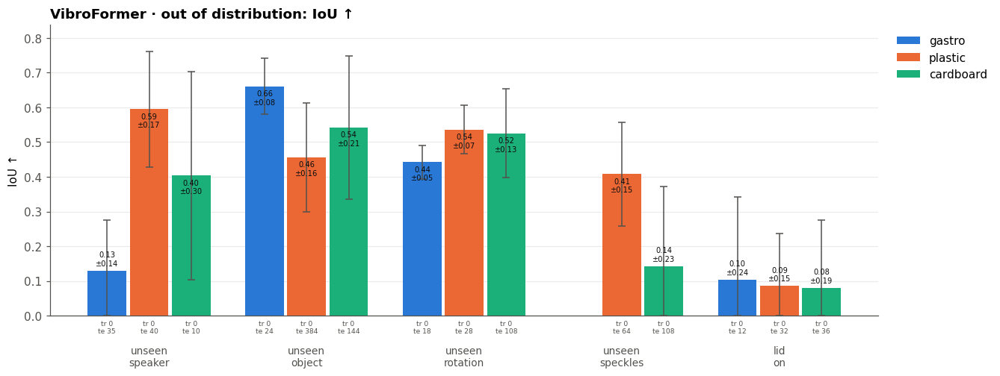

,gastro,plastic,cardboard,all
in distribution,0.001 ±0.038,0.000 ±0.000,0.005 ±0.082,0.002 ±0.055
unseen speaker,0.343 ±0.482,0.000 ±0.000,0.300 ±0.483,0.214 ±0.383
unseen object,0.000 ±0.000,0.075 ±0.124,0.049 ±0.216,0.049 ±0.152
unseen rotation,0.000 ±0.000,0.000 ±0.000,0.000 ±0.000,0.000 ±0.000
unseen speckles,—,0.016 ±0.125,0.639 ±0.483,0.390 ±0.493
lid on,0.750 ±0.452,0.625 ±0.492,0.750 ±0.439,0.708 ±0.461


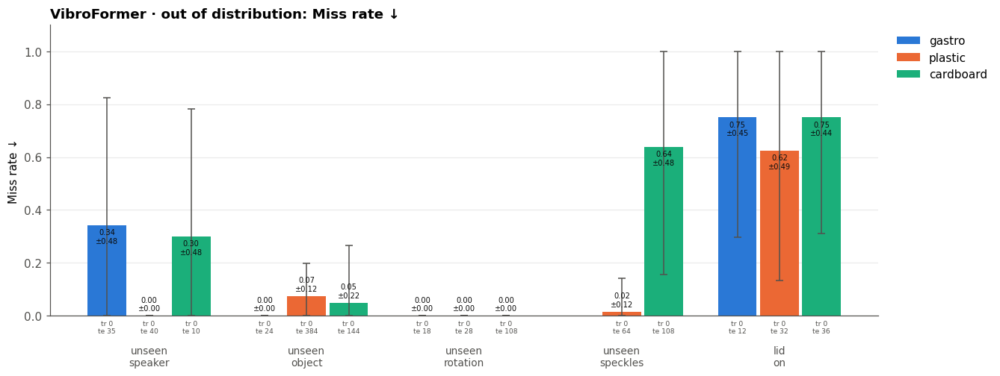

,gastro,plastic,cardboard,all
in distribution,3.7 ±3.5,3.6 ±2.9,3.9 ±3.8,3.7 ±3.5
unseen speaker,13.4 ±14.2,2.0 ±1.7,12.9 ±16.4,9.5 ±11.9
unseen object,1.7 ±0.9,3.8 ±1.8,3.4 ±4.0,3.3 ±2.6
unseen rotation,1.5 ±0.7,1.7 ±0.8,2.8 ±2.0,2.0 ±1.8
unseen speckles,—,3.1 ±1.8,29.4 ±22.4,18.9 ±21.4
lid on,23.6 ±24.0,21.9 ±16.0,34.2 ±18.8,26.6 ±19.2


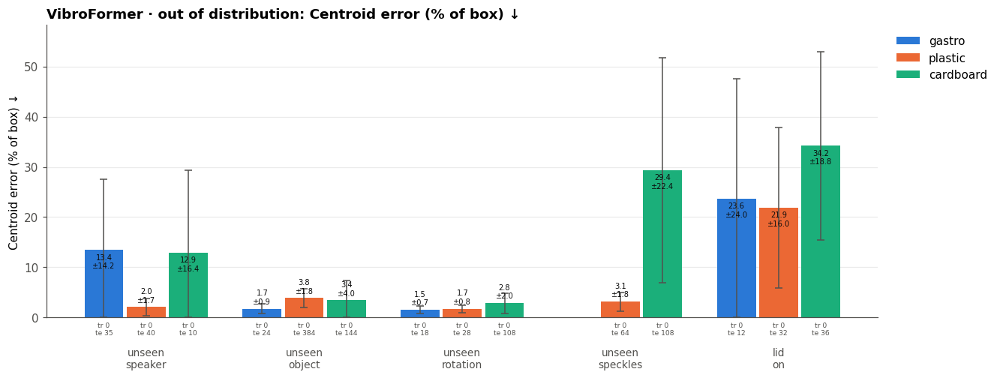

In [30]:
cats = [c for c in ['id'] + OOD if c in set(df.category)]
for metric in METRICS:
    e = df[df.set == 'eval']
    t = make_table({(NAMES[c], b): mean_std(pick(e, b, c, 'category'), metric) for c in cats for b in BOXES + ('all',)}, metric, vlines=(3,))
    show(t, f'tab_ood_{metric}', f'Out of distribution: {captions[metric]} on conditions never seen in training, per box', axis=1)
    bars('category', cats[1:], metric, METRICS[metric], f'VibroFormer · out of distribution: {METRICS[metric]}', [NAMES[c].replace(' ', '\n', 1) for c in cats[1:]], (13, 4.6))
    save_fig(f'fig_ood_{metric}', f'Out of distribution, {captions[metric]} per condition and box.')
    plt.show()

Samples behind Table 2 (n train of an OOD row is 0 by construction):

In [31]:
save_table(pd.DataFrame({(k, b): [len(pick(df[df.set == s], b, c, 'category')) for c in cats] for k, s in (('n train', 'train'), ('n test', 'eval')) for b in BOXES}, index=[NAMES[c] for c in cats]), 'tab_ood_samples', 'Samples behind Table 2')

n train                   n test                  
                 gastro plastic cardboard gastro plastic cardboard
in distribution    2736    3796      4144    684     946      1036
unseen speaker        0       0         0     35      40        10
unseen object         0       0         0     24     384       144
unseen rotation       0       0         0     18      28       108
unseen speckles       0       0         0      0      64       108
lid on                0       0         0     12      32        36

### 5 Weight trend
The cylinders are one shape at four masses (100, 200, 500 and 1000 g), and all four are trained. So this is not a generalization test: it asks whether a lighter object gives the box less signal. Only boxes whose run trained on cylinders are shown; the current run has only cardboard. In a `--dataset paper` run, all three boxes train every weight, with 20% of positions held out.

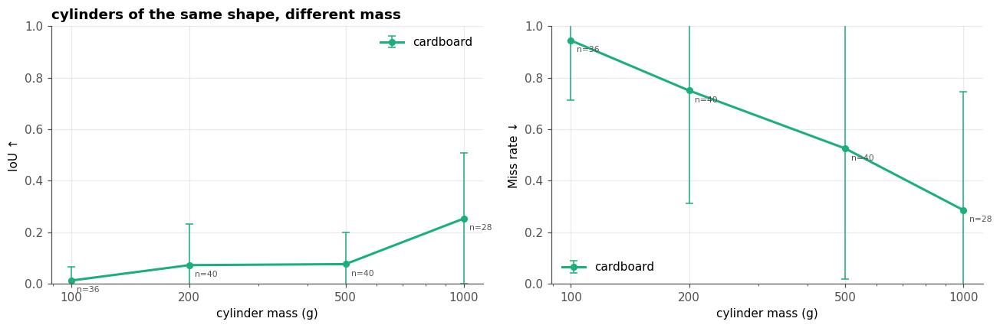

In [32]:
d = df[(df.set == 'eval') & (df.category == 'weight')]
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
for ax, m in zip(axs, ('iou', 'miss')):
    for b in BOXES:
        g = d[d.box == b].groupby('mass')[m].agg(['mean', 'std', 'size'])
        if g.empty: continue
        ax.errorbar(g.index, g['mean'], g['std'], fmt='-o', color=COLORS[b], lw=2, ms=5, capsize=3, elinewidth=1, label=b)
        for x, v, n in zip(g.index, g['mean'], g['size']): ax.annotate(f'n={n}', (x, v), xytext=(5, -10), textcoords='offset points', fontsize=7, color=MUTED)
    ax.set(xscale='log', xlabel='cylinder mass (g)', ylabel=METRICS[m], ylim=(0, 1))
    ax.set_xticks([100, 200, 500, 1000], ['100', '200', '500', '1000'])
    ax.legend(frameon=False)
axs[0].set_title('cylinders of the same shape, different mass', loc='left', fontweight='bold')
fig.tight_layout()
save_fig('fig_weight_trend', 'IoU and miss rate vs cylinder mass (all masses trained).')

### 6 Table 3: aux heads
All boxes together. Box accuracy is trivial here, because the box id is an input. Objects never trained on have no class, so their row is the novelty AUROC (1 − confidence, against in distribution).

,in distribution,unseen speaker,unseen object,unseen rotation,unseen speckles,lid on
object acc,0.934 ±0.161,0.410 ±0.499,—,0.915 ±0.194,0.123 ±0.321,0.009 ±0.112
object count acc,0.984 ±0.082,1.000 ±0.000,0.996 ±0.043,0.994 ±0.114,0.758 ±0.434,0.799 ±0.403
box acc,1.000 ±0.000,1.000 ±0.000,1.000 ±0.000,1.000 ±0.000,1.000 ±0.000,1.000 ±0.000
CoM head err (% box),4.420 ±3.676,10.996 ±10.762,5.088 ±3.110,3.445 ±4.034,19.378 ±16.573,22.570 ±12.031
area rel err,0.108 ±0.090,0.501 ±0.336,0.313 ±0.166,0.199 ±0.135,0.566 ±0.353,1.099 ±0.711
orient err from mask (°),6.476 ±7.838,20.332 ±18.352,19.583 ±16.840,67.113 ±30.556,28.069 ±30.903,28.911 ±26.944
novelty AUROC,—,0.849,0.787,0.686,0.919,0.879


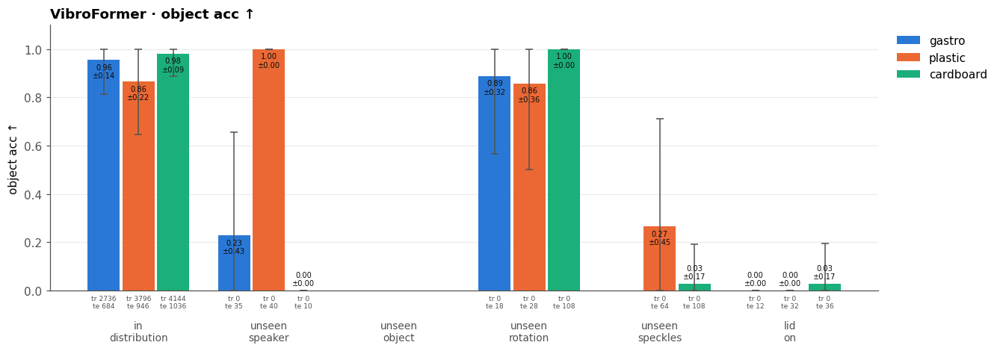

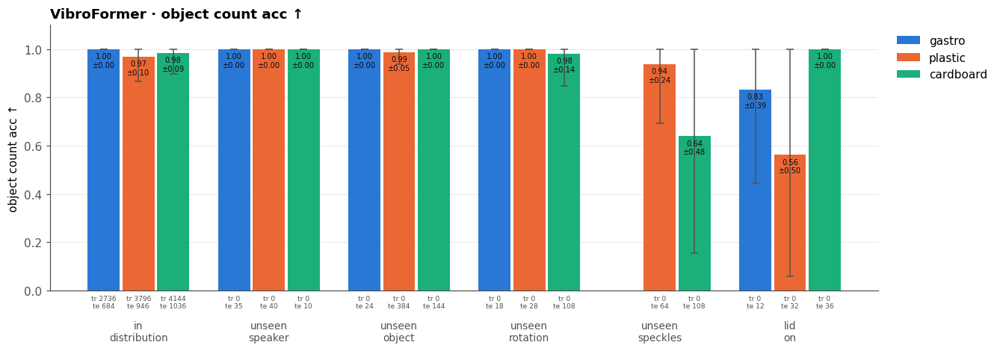

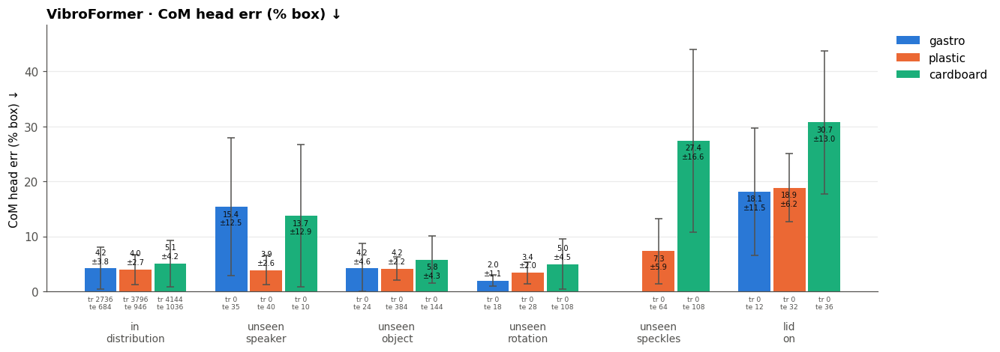

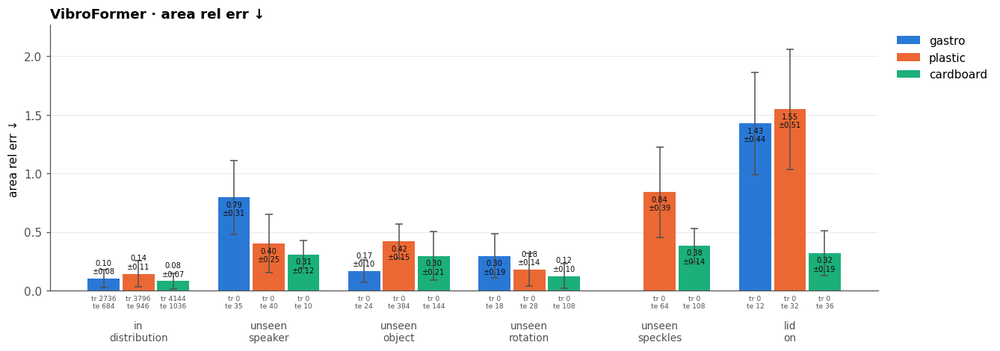

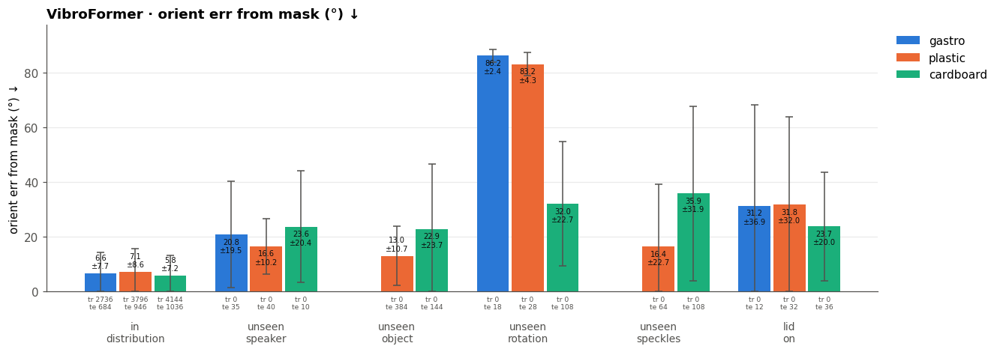

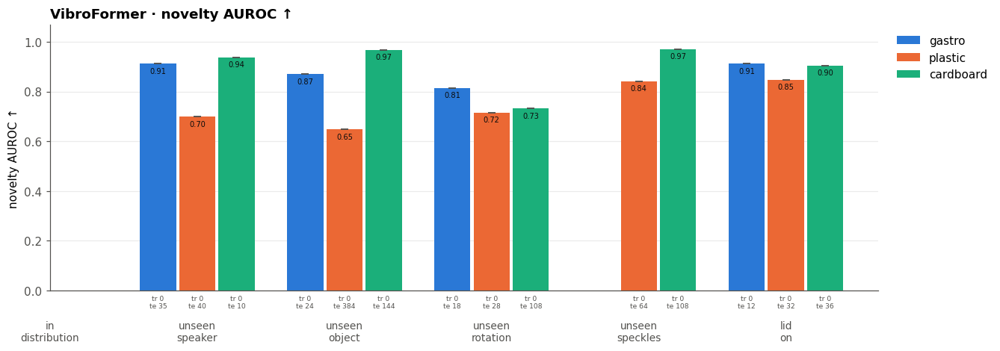

In [33]:
e = df[df.set == 'eval']
cats = [c for c in ['id'] + OOD if c in set(e.category)]
head_rows = {'object acc': 'object_acc', 'object count acc': 'count_acc', 'box acc': 'box_acc', 'CoM head err (% box)': 'com_head_err', 'area rel err': 'area_err', 'orient err from mask (°)': 'orient_err'}
cells = {(name, NAMES[c]): mean_std(e[e.category == c], m) for name, m in head_rows.items() for c in cats}
idc = e[e.category == 'id'].obj_conf.to_numpy()
cells |= {('novelty AUROC', NAMES[c]): (np.nan if c == 'id' else auroc(1 - idc, 1 - e[e.category == c].obj_conf.to_numpy()), np.nan) for c in cats}
t = make_table(cells, 'heads')
show(t, 'tab_aux_heads', 'Auxiliary heads, all boxes', color=False)
HEADS = {'object_acc': 'object acc ↑', 'count_acc': 'object count acc ↑', 'com_head_err': 'CoM head err (% box) ↓', 'area_err': 'area rel err ↓',
         'orient_err': 'orient err from mask (°) ↓', 'novelty': 'novelty AUROC ↑'}
for h, lab in HEADS.items():
    bars('category', cats, h, lab, f'VibroFormer · {lab}', [NAMES[c].replace(' ', '\n', 1) for c in cats], (13, 4.2))
    save_fig(f'fig_head_{h}', f'Auxiliary head: {lab}, per condition and box.')
    plt.show()

### 7 Floor error map
In-distribution IoU over the floor, binned by the true centroid: one row per speaker, then all speakers together (last row). Gastro has no speaker 5. The lasers are on the bottom wall; the dashed square is the unseen-position block. A bin with fewer than 2 positions is blank: plastic has almost none next to the laser wall.

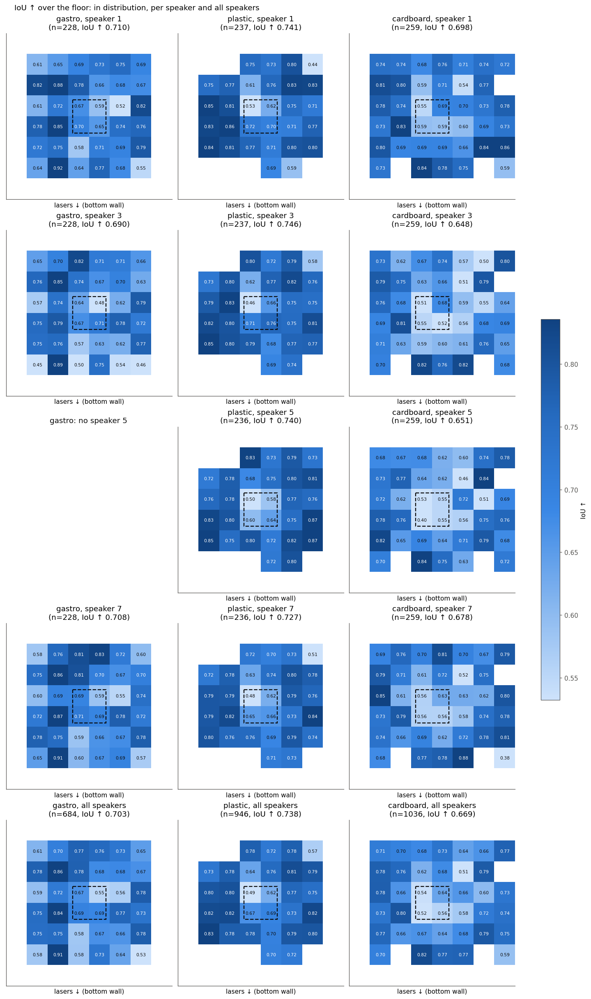

In [34]:
metric, bins, min_pos = 'iou', 8, 2                            # a bin with < 2 positions is blank
d = df[(df.set == 'eval') & (df.category == 'id')].dropna(subset=['com_r', 'com_c'])
edges = np.linspace(0, 1, bins + 1)

def floor_map(g):
    """mean metric per (row, col) bin of the true centroid; NaN where < min_pos positions"""
    r, c = (np.clip(np.digitize(g[k], edges) - 1, 0, bins - 1) for k in ('com_r', 'com_c'))
    s, n = np.zeros((bins, bins)), np.zeros((bins, bins))
    np.add.at(s, (r, c), g[metric].to_numpy()); np.add.at(n, (r, c), 1)
    npos = pd.Series(list(zip(g.experiment, g.position_id))).groupby([r, c]).nunique()
    ok = np.zeros((bins, bins), bool)
    if (npos >= min_pos).any(): ok[tuple(np.array(list(npos[npos >= min_pos].index)).T)] = True
    return np.where(ok, s / np.maximum(n, 1), np.nan)

spks = sorted(d.speaker.unique())
rows = [(f'speaker {s}', d[d.speaker == s]) for s in spks] + [('all speakers', d)]
maps = {(k, b): floor_map(g[g.box == b]) for k, g in rows for b in BOXES if (g.box == b).any()}
lo, hi = np.nanpercentile(np.concatenate([m.ravel() for m in maps.values()]), [5, 95])   # one colour scale for every panel
fig, axs = plt.subplots(len(rows), len(BOXES), figsize=(13, 4.4 * len(rows)), squeeze=False, constrained_layout=True)
for (k, g), axr in zip(rows, axs):
    for ax, b in zip(axr, BOXES):
        if (k, b) not in maps: ax.axis('off'); ax.set_title(f'{b}: no {k}', color=INK); continue
        m = maps[k, b]
        im = ax.imshow(m, cmap=BLUES, vmin=lo, vmax=hi, extent=(0, 1, 1, 0))
        for (i, j), v in np.ndenumerate(m):
            if not np.isnan(v): ax.text((j + .5) / bins, (i + .5) / bins, f'{v:.2f}', ha='center', va='center', fontsize=7, color='white' if (v - lo) / (hi - lo) > .55 else INK)
        r0, r1, c0, c1 = D.BLOCK
        ax.add_patch(Rectangle((c0, r0), c1 - c0, r1 - r0, fill=False, ls='--', lw=1.5, ec=INK))
        ax.set(title=f'{b}, {k}\n(n={(g.box == b).sum()}, {METRICS[metric]} {g[g.box == b][metric].mean():.3f})', xticks=[], yticks=[], xlabel='lasers ↓ (bottom wall)'); ax.grid(False)
fig.colorbar(im, ax=axs, shrink=.4, label=METRICS[metric])
fig.suptitle(f'{METRICS[metric]} over the floor: in distribution, per speaker and all speakers', x=0.02, ha='left');
save_fig('fig_floor_map', 'In-distribution IoU over the floor, per speaker and all speakers (dashed: unseen-position block).')

#### 7.1 Do we do better closer to the speaker?
The maps above share one pattern for every speaker. Asked directly: subtract, at each position, the mean over its speakers. This **paired residual** removes everything the speakers share: the position itself, the object, and the box. If being near a speaker helped, that speaker's residual would rise toward the wall it is on, and each speaker would rise toward a different wall. Only positions recorded by every speaker of the box are used. Blue = this speaker does better here than the other speakers at the same spot; orange = worse. Each title gives the residual's linear slope across the box (rows toward the laser wall, columns toward the right) with a 95% bootstrap CI. The per-box permutation test shuffles speaker labels within each position.

,box,speaker,n,IoU,slope → laser wall,CI row,slope → right,CI col,perm p (box)
0,gastro,1,228,0.710,0.038,"[-0.014, +0.093]",0.010,"[-0.036, +0.052]",0.40
1,gastro,3,228,0.690,-0.056,"[-0.127, +0.010]",-0.002,"[-0.054, +0.050]",0.40
2,gastro,7,228,0.708,0.018,"[-0.042, +0.077]",-0.008,"[-0.053, +0.036]",0.40
3,plastic,1,236,0.740,-0.011,"[-0.074, +0.047]",-0.063,"[-0.109, -0.016]",0.10
4,plastic,3,236,0.745,0.010,"[-0.039, +0.060]",-0.017,"[-0.057, +0.024]",0.10
5,plastic,5,236,0.740,-0.005,"[-0.061, +0.057]",0.059,"[+0.012, +0.105]",0.10
6,plastic,7,236,0.727,0.005,"[-0.051, +0.062]",0.022,"[-0.028, +0.067]",0.10
7,cardboard,1,259,0.698,-0.015,"[-0.060, +0.035]",0.015,"[-0.032, +0.061]",0.22
8,cardboard,3,259,0.648,0.010,"[-0.055, +0.078]",-0.064,"[-0.117, -0.012]",0.22
9,cardboard,5,259,0.651,0.043,"[-0.029, +0.117]",0.033,"[-0.020, +0.086]",0.22


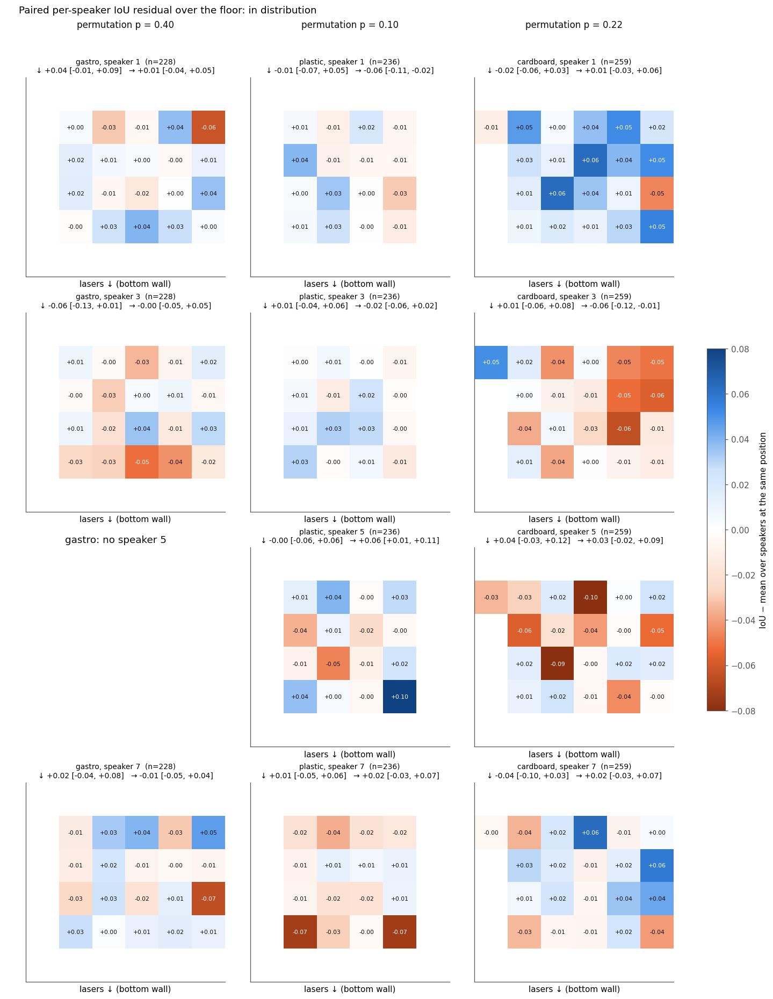

In [35]:
bins, min_pos, n_boot, n_perm = 6, 2, 1000, 300
key = ['experiment', 'position_id', 'split']
d = df[(df.set == 'eval') & (df.category == 'id')].dropna(subset=['com_r', 'com_c']).copy()
d = d[d.groupby(key).speaker.transform('nunique') == d.groupby('box').speaker.transform('nunique')]   # positions every speaker of the box recorded
d['res'] = d.iou - d.groupby(key).iou.transform('mean')
edges, rng = np.linspace(0, 1, bins + 1), np.random.default_rng(0)

def slopes(g):
    """least-squares res ~ 1 + row + col; row/col in box fractions, so a slope = IoU change across the whole box"""
    X = np.c_[np.ones(len(g)), g.com_r, g.com_c]
    return np.linalg.lstsq(X, g.res.to_numpy(), rcond=None)[0][1:]

def explained(g):
    """residual sum of squares the per-speaker planes explain, summed over speakers"""
    return sum(((k.res - k.res.mean()) ** 2).sum() - ((k.res.to_numpy() - np.c_[np.ones(len(k)), k.com_r, k.com_c] @ np.linalg.lstsq(np.c_[np.ones(len(k)), k.com_r, k.com_c], k.res.to_numpy(), rcond=None)[0]) ** 2).sum()
               for _, k in g.groupby('speaker'))

spks = sorted(d.speaker.unique())
fig, axs = plt.subplots(len(spks), len(BOXES), figsize=(13, 4.2 * len(spks)), squeeze=False, constrained_layout=True)
lim, rows = .08, []
for j, b in enumerate(BOXES):
    g = d[d.box == b]
    obs = explained(g)
    perm = [explained(g.assign(speaker=g.groupby(key).speaker.transform(lambda v: rng.permutation(v.to_numpy())))) for _ in range(n_perm)]
    pval = (np.array(perm) >= obs).mean()
    for i, s in enumerate(spks):
        ax, h = axs[i, j], g[g.speaker == s]
        if h.empty: ax.axis('off'); ax.set_title(f'{b}: no speaker {s}', color=INK); continue
        r, c = (np.clip(np.digitize(h[k], edges) - 1, 0, bins - 1) for k in ('com_r', 'com_c'))
        sm, n = np.zeros((bins, bins)), np.zeros((bins, bins))
        np.add.at(sm, (r, c), h.res.to_numpy()); np.add.at(n, (r, c), 1)
        m = np.where(n >= min_pos, sm / np.maximum(n, 1), np.nan)
        im = ax.imshow(m, cmap=DIVERGE.reversed(), vmin=-lim, vmax=lim, extent=(0, 1, 1, 0))
        for (a, e), v in np.ndenumerate(m):
            if not np.isnan(v): ax.text((e + .5) / bins, (a + .5) / bins, f'{v:+.02f}', ha='center', va='center', fontsize=7, color='white' if abs(v) > .6 * lim else INK)
        beta = slopes(h)
        bs = np.array([slopes(h.iloc[k]) for k in rng.integers(0, len(h), (n_boot, len(h)))])
        lo, hi = np.percentile(bs, [2.5, 97.5], 0)
        rows.append({'box': b, 'speaker': s, 'n': len(h), 'IoU': h.iou.mean(), 'slope → laser wall': beta[0], 'CI row': f'[{lo[0]:+.3f}, {hi[0]:+.3f}]',
                     'slope → right': beta[1], 'CI col': f'[{lo[1]:+.3f}, {hi[1]:+.3f}]', 'perm p (box)': pval})
        ax.set_title(f'{b}, speaker {s}  (n={len(h)})\n↓ {beta[0]:+.2f} [{lo[0]:+.2f}, {hi[0]:+.2f}]   → {beta[1]:+.2f} [{lo[1]:+.2f}, {hi[1]:+.2f}]', fontsize=9)
        ax.set(xticks=[], yticks=[], xlabel='lasers ↓ (bottom wall)'); ax.grid(False)
    axs[0, j].annotate(f'permutation p = {pval:.2f}', (0.5, 1.25), xycoords='axes fraction', ha='center', fontsize=11, color=INK)
fig.colorbar(im, ax=axs, shrink=.4, label='IoU − mean over speakers at the same position')
fig.suptitle('Paired per-speaker IoU residual over the floor: in distribution', x=0.02, ha='left')
save_fig('fig_speaker_residual_map', 'Per-speaker IoU minus the mean over speakers at the same position, over the floor.')
save_table(pd.DataFrame(rows).round(3), 'tab_speaker_residual', 'Per-speaker IoU residual: slope across the box')

**Reading:**
- **No: no speaker does better on its own side of the box.** Spatial patterns specific to one speaker explain 0.3% (gastro), 1.6% (plastic) and 1.4% (cardboard) of the paired residual variance. Shuffling speakers within each position gives about as much: permutation p = 0.86 / 0.05 / 0.11 (plastic is borderline, cardboard and gastro are not).
- Every slope is at most ±0.06 IoU from one wall to the opposite wall. All but three CIs include 0 (plastic speaker 1 and 5 columns, cardboard speaker 3 column), and 3 of 22 at the 95% level is about what chance gives. The residual's spread at a single position is far larger (sd 0.07–0.09).
- Plastic speakers 1 and 5 lean in opposite directions along the columns (−0.05 vs +0.05). If those two speakers sit on opposite sides of the box, this is the only hint of a near-speaker effect, and it is small: about 0.05 IoU across the whole floor.
- What sets IoU is **where the object is**, and that is the same for every speaker: the unseen-position block and the edges, see the maps above. The speakers differ only by a constant: their mean IoUs are within 0.03 of each other.
- The repo has no speaker coordinates, so this is the speaker-agnostic version of the test. To turn the slopes into "toward / away from the speaker", read them against each speaker's mounting wall.

### 8 Error vs distance to the speaker
Where the speakers are, from `record/record.ipynb` (`SPEAKER_POSITION`): (x, y) as fractions of the box, y = 0 at the bottom, so on the floor maps above (row 0 at the top, lasers at the bottom) a speaker sits at row 1 − y, column x. Speaker 1 is at the bottom-right corner, speakers 3 and 5 on the top wall (columns 0.8 and 0.4), and speaker 7 on the left wall (row 0.3). The rig is the same for every box, so the same positions are used for all three. The distance is from the object's true centre of mass to the speaker, in box fractions.

Two rows per box. **Top:** raw IoU vs distance. This mixes in *where* the object is (the middle of the floor is hard for every speaker), so a slope here does not mean "near the speaker". **Bottom:** the paired residual of section 7.1 (IoU − mean over speakers at the same position) vs the same distance. Position, object and box cancel, so a near-speaker advantage would show up as a residual falling with distance. Lines = mean per distance bin (bins with ≥ 15 samples), band = 95% bootstrap CI. Legend: Spearman ρ with the 95% bootstrap CI.

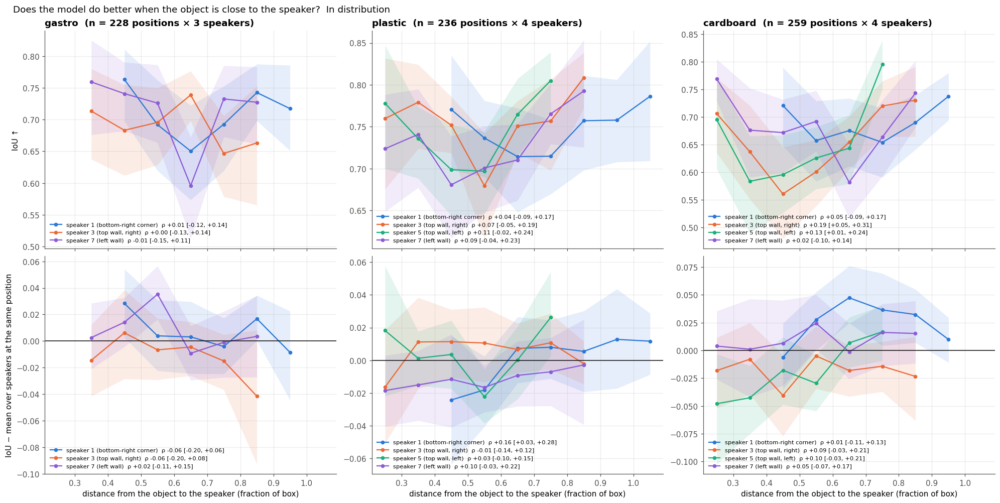

,box,speaker,where,n,ρ IoU,CI IoU,ρ residual,CI residual
0,gastro,1,bottom-right corner,228,0.013,"[-0.12, +0.14]",-0.064,"[-0.20, +0.06]"
1,gastro,3,"top wall, right",228,0.001,"[-0.13, +0.14]",-0.061,"[-0.20, +0.08]"
2,gastro,7,left wall,228,-0.011,"[-0.15, +0.11]",0.016,"[-0.11, +0.15]"
3,plastic,1,bottom-right corner,236,0.043,"[-0.09, +0.17]",0.161,"[+0.03, +0.28]"
4,plastic,3,"top wall, right",236,0.068,"[-0.05, +0.19]",-0.006,"[-0.14, +0.12]"
5,plastic,5,"top wall, left",236,0.115,"[-0.02, +0.24]",0.030,"[-0.10, +0.15]"
6,plastic,7,left wall,236,0.092,"[-0.04, +0.23]",0.097,"[-0.03, +0.22]"
7,cardboard,1,bottom-right corner,259,0.047,"[-0.09, +0.17]",0.007,"[-0.11, +0.13]"
8,cardboard,3,"top wall, right",259,0.186,"[+0.05, +0.31]",0.093,"[-0.03, +0.21]"
9,cardboard,5,"top wall, left",259,0.128,"[+0.01, +0.24]",0.096,"[-0.03, +0.21]"


In [36]:
SPEAKER_POSITION = {1: (1, 0), 2: (1, 0.7), 3: (0.8, 1), 4: (0.6, 1), 5: (0.4, 1), 6: (0.2, 1), 7: (0, 0.7), 8: (0, 0)}   # record.ipynb: (x, y), y = 0 at the bottom
step, min_n, n_boot = .1, 15, 1000
key = ['experiment', 'position_id', 'split']
d = df[(df.set == 'eval') & (df.category == 'id')].dropna(subset=['com_r', 'com_c']).copy()
d = d[d.groupby(key).speaker.transform('nunique') == d.groupby('box').speaker.transform('nunique')]   # positions every speaker of the box recorded
d['res'] = d.iou - d.groupby(key).iou.transform('mean')
spk_rc = {s: (1 - y, x) for s, (x, y) in SPEAKER_POSITION.items()}               # (row, col) on the floor maps
d['dist'] = [np.hypot(r - spk_rc[s][0], c - spk_rc[s][1]) for r, c, s in zip(d.com_r, d.com_c, d.speaker)]
spks = sorted(d.speaker.unique())
SPK_COLOR = dict(zip(spks, PALETTE))
WHERE = {1: 'bottom-right corner', 3: 'top wall, right', 5: 'top wall, left', 7: 'left wall'}
rng = np.random.default_rng(0)

def rho_ci(x, y):
    """Spearman rho and its 95% bootstrap CI"""
    rx, ry = pd.Series(x).rank().to_numpy(), pd.Series(y).rank().to_numpy()
    r = np.corrcoef(rx, ry)[0, 1]
    bs = [np.corrcoef(*(pd.DataFrame({'x': x[i], 'y': y[i]}).rank().to_numpy().T))[0, 1] for i in rng.integers(0, len(x), (n_boot, len(x)))]
    return r, *np.percentile(bs, [2.5, 97.5])

fig, axs = plt.subplots(2, len(BOXES), figsize=(18, 9), sharex=True, constrained_layout=True)
rows = []
edges = np.arange(0, 1.4 + step, step)
for j, b in enumerate(BOXES):
    g = d[d.box == b]
    for s, h in g.groupby('speaker'):
        out = {'box': b, 'speaker': s, 'where': WHERE.get(s, ''), 'n': len(h)}
        for i, (col, name) in enumerate((('iou', 'IoU'), ('res', 'residual'))):
            ax, x, y = axs[i, j], h.dist.to_numpy(), h[col].to_numpy()
            k = np.digitize(x, edges) - 1
            pts = []
            for q in np.unique(k):
                v = y[k == q]
                if len(v) < min_n: continue
                bm = rng.choice(v, (n_boot, len(v))).mean(1)
                pts.append((edges[q] + step / 2, v.mean(), *np.percentile(bm, [2.5, 97.5])))
            pts = np.array(pts)
            r, lo, hi = rho_ci(x, y)
            out |= {f'ρ {name}': r, f'CI {name}': f'[{lo:+.2f}, {hi:+.2f}]'}
            ax.plot(pts[:, 0], pts[:, 1], '-o', ms=4, color=SPK_COLOR[s], label=f'speaker {s} ({WHERE.get(s, "")})  ρ {r:+.2f} [{lo:+.2f}, {hi:+.2f}]')
            ax.fill_between(pts[:, 0], pts[:, 2], pts[:, 3], color=SPK_COLOR[s], alpha=.12, lw=0)
        rows.append(out)
    axs[0, j].set_title(f'{b}  (n = {g.groupby(key).ngroups} positions × {g.speaker.nunique()} speakers)', loc='left', fontweight='bold')
    axs[1, j].axhline(0, color=INK, lw=1)
    axs[1, j].set_xlabel('distance from the object to the speaker (fraction of box)')
    for ax in axs[:, j]: ax.legend(frameon=False, fontsize=7.5, loc='lower left')
axs[0, 0].set_ylabel(METRICS['iou']); axs[1, 0].set_ylabel('IoU − mean over speakers at the same position')
fig.suptitle('Does the model do better when the object is close to the speaker?  In distribution', x=0.01, ha='left')
save_fig('fig_speaker_distance', 'IoU (top) and the paired per-speaker residual (bottom) vs distance from the object to the speaker.')
plt.show()
save_table(pd.DataFrame(rows).round(3), 'tab_speaker_distance', 'IoU vs distance to the speaker: Spearman rho')

**Reading:**
- **No: being close to the speaker does not help.**
- **The raw IoU (top row) is U-shaped in distance** for plastic and cardboard: high near and far, lowest at 0.5–0.7. That is *where the object is*, not the speaker. Mid distances are the middle of the floor, the hardest region for every speaker (section 7).
- **Paired residual (bottom row): flat.** Every speaker's residual stays within ±0.03 of zero at every distance. No ρ is significantly negative (negative would mean closer is better): all 11 CIs include 0 or sit above it.
- The only trend goes the *other* way: cardboard speakers 3 and 5 (top wall) do slightly better *farther* away, residual ρ +0.13 and +0.11 with CIs touching 0. That is about 0.03–0.05 IoU from near to far, the same size as the plastic hint in section 7.1.
- Caveats: no object is closer than ~0.25 of the box to a speaker, because the speakers sit at or outside the walls. And `SPEAKER_POSITION` is one rig layout used for all three boxes.

### 9 IoU vs distance to the nearest training position
Random held-out positions sit within about 3% of the box of a training position. Only the unseen-position block (paper split) reaches further out.

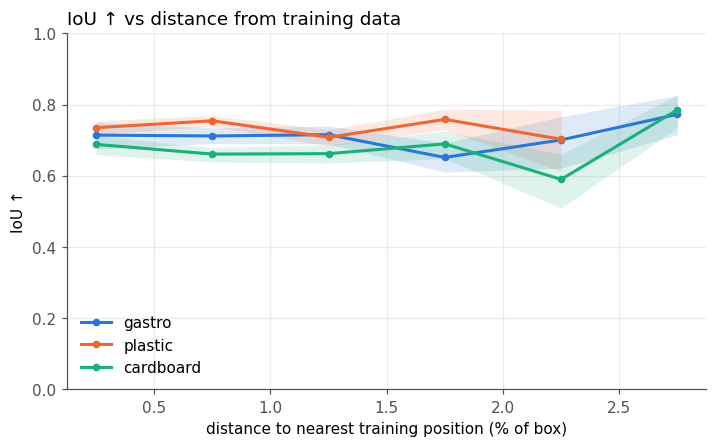

In [37]:
def ci(v, n=1000):
    """95% bootstrap CI of the mean"""
    m = np.random.default_rng(0).choice(np.asarray(v, float), (n, len(v))).mean(1)
    return np.percentile(m, 2.5), np.percentile(m, 97.5)

step = 0.5
d = df[(df.set == 'eval') & df.category.isin(('id', 'unseen-position'))].assign(dist=lambda x: x.train_dist * 100).dropna(subset=['dist'])
d['bin'] = (d.dist // step + .5) * step
fig, ax = plt.subplots(figsize=(7.5, 4.2))
for b in BOXES:
    g = d[d.box == b].groupby('bin').iou.agg(list)
    g = g[g.map(len) >= 5]                                   # bins of < 5 dropped
    c = np.array([ci(v) for v in g])
    ax.fill_between(g.index, c[:, 0], c[:, 1], color=COLORS[b], alpha=.15, lw=0)
    ax.plot(g.index, g.map(np.mean), '-o', color=COLORS[b], lw=2, ms=4, label=b)
ax.set(xlabel='distance to nearest training position (% of box)', ylabel=METRICS['iou'], ylim=(0, 1))
ax.legend(frameon=False, loc='lower left')
ax.set_title(f"{METRICS['iou']} vs distance from training data", loc='left');
save_fig('fig_iou_vs_train_distance', 'IoU vs distance to the nearest training position.')

### 10 Per speaker
In-distribution performance per speaker and box, on positions all three speakers recorded (paired). Whiskers = 95% bootstrap CI over positions.

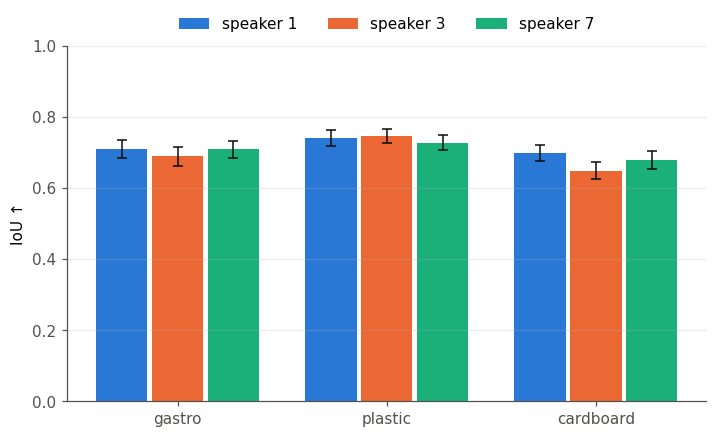

In [38]:
spks = (1, 3, 7)
d = df[(df.set == 'eval') & (df.category == 'id') & df.speaker.isin(spks)]
d = d[d.groupby(['experiment', 'position_id']).speaker.transform('nunique') == len(spks)]   # positions every speaker recorded
fig, ax = plt.subplots(figsize=(7.5, 4.2))
for k, s in enumerate(spks):
    for i, b in enumerate(BOXES):
        v = d[(d.box == b) & (d.speaker == s)].groupby(['experiment', 'position_id']).iou.mean()
        lo, hi = ci(v)
        x = i + (k - 1) * .8 / 3
        ax.bar(x, v.mean(), .8 / 3 * .92, color=PALETTE[k], label=f'speaker {s}' if i == 0 else None)
        ax.errorbar(x, v.mean(), [[v.mean() - lo], [hi - v.mean()]], color=INK, lw=1, capsize=3)
ax.set_xticks(range(3), BOXES)
ax.set(ylabel=METRICS['iou'], ylim=(0, 1)); ax.grid(axis='x', visible=False)
ax.legend(frameon=False, ncols=3, loc='upper center', bbox_to_anchor=(.5, 1.12));
save_fig('fig_per_speaker', 'In-distribution performance per speaker and box (paired positions).')

### 11 Per speaker: train vs eval
In distribution, for each box: every speaker's train positions (scored by the train evaluator, no augmentation) next to its held-out eval positions. Light bar = train, solid bar = eval; whiskers = ±1 std over samples; the number at the bottom of a bar is its mean. Miss is ≈0 everywhere, so it is only in the table. Mean over the six objects (every object counts once), as in Table 1.

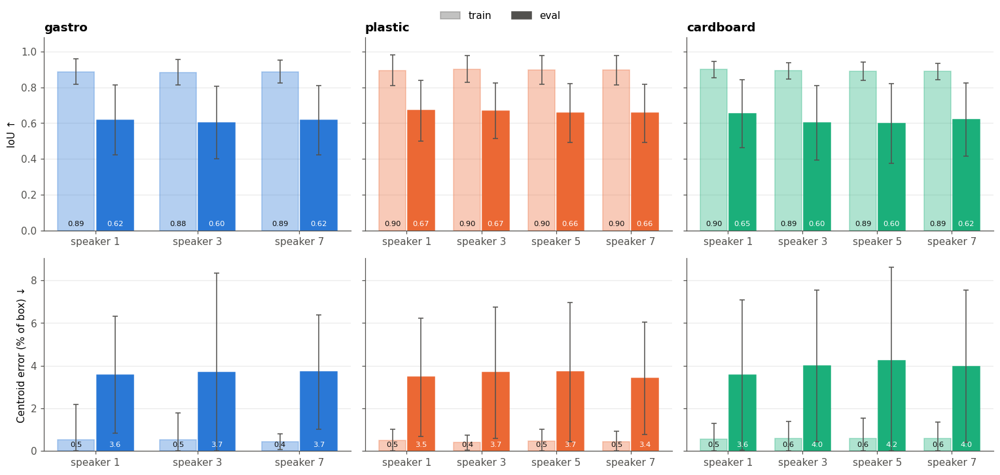

In [39]:
def train_eval(by):
    """{(row, (metric, set)): (mean, std)} over the in-distribution splits, one row per group of `by`"""
    cells = {}
    for key, g in df[df.split.isin(ID)].groupby(by):
        for metric in METRICS:
            for s in ('train', 'eval'):
                cells[key, (METRICS[metric], s)] = mean_std(g[g.set == s], metric)
    return cells

def train_eval_bars(ax, groups, labels, colors, metric):
    """per group: a light train bar and a solid eval bar, ±1 std whisker, value on top"""
    f = '.1f' if metric == 'com_err' else '.2f'
    for x, (g, c) in enumerate(zip(groups, colors)):
        for k, s in enumerate(('train', 'eval')):
            m, sd = mean_std(g[g.set == s], metric)
            xi = x + (k - .5) * .38
            ax.bar(xi, m, .36, color=c, alpha=.35 if s == 'train' else 1, edgecolor=c, lw=1)
            ax.errorbar(xi, m, [[min(sd, m)], [sd if metric == 'com_err' else min(sd, 1 - m)]], fmt='none', ecolor=MUTED, elinewidth=1, capsize=2.5)
            ax.annotate(f'{m:{f}}', (xi, 0), xytext=(0, 3), textcoords='offset points', ha='center', va='bottom', fontsize=7.5, color=INK if s == 'train' else 'white')
    ax.set_xticks(range(len(groups)), labels); ax.grid(axis='x', visible=False); ax.set_axisbelow(True)
    if metric != 'com_err': ax.set_ylim(0, 1.08)

FIG_METRICS = ('iou', 'com_err')                              # miss is ~0 for every speaker and box: in the tables only
d = df[df.split.isin(ID)]
fig, axs = plt.subplots(len(FIG_METRICS), len(BOXES), figsize=(14, 6.5), sharey='row')
for j, b in enumerate(BOXES):
    spk = sorted(d[d.box == b].speaker.unique())
    for i, metric in enumerate(FIG_METRICS):
        train_eval_bars(axs[i, j], [d[(d.box == b) & (d.speaker == s)] for s in spk], [f'speaker {s}' for s in spk], [COLORS[b]] * len(spk), metric)
        axs[i, 0].set_ylabel(METRICS[metric])
    axs[0, j].set_title(b, loc='left', fontweight='bold')
fig.legend([Patch(color=MUTED, alpha=.35), Patch(color=MUTED)], ['train', 'eval'], frameon=False, ncols=2, loc='upper center', bbox_to_anchor=(.5, 1.02))
fig.tight_layout()
save_fig('fig_speaker_train_eval', 'In distribution, per speaker and box: train (light) vs eval (solid). Whiskers: ±1 std over samples.')
plt.show()
t = make_table(train_eval(['box', 'speaker']), 'per-speaker', vlines=(2, 4), skip=('train',), blocks=True)
t.index = pd.MultiIndex.from_tuples([(b, f'speaker {s}') for b, s in t.index])
t = t.loc[[i for b in BOXES for i in t.index if i[0] == b]]
show(t, 'tab_speaker_train_eval', 'In distribution, per speaker and box: train vs eval. Best eval speaker of each box in bold.')

**Reading:**
- **The speaker barely matters.** Within a box, eval IoU spans at most 0.03 across speakers (gastro 0.61–0.63, plastic 0.67–0.68, cardboard 0.61–0.63), well inside the ±0.2 spread over samples.
- **Train is the same for every speaker** (0.90 / 0.92 / 0.90), so the train–eval gap (≈0.25–0.29 IoU, ≈3 points of centroid error) is the same everywhere: it is about held-out positions, not the speaker.
- Speaker 7 is best in gastro and speaker 1 in cardboard, but these differences are small (see section 7.1: no speaker does better on its own side).

### 12 Per box: train vs eval
Which box does VibroFormer do best on? In distribution, all speakers; same bars as above, one pair per box.

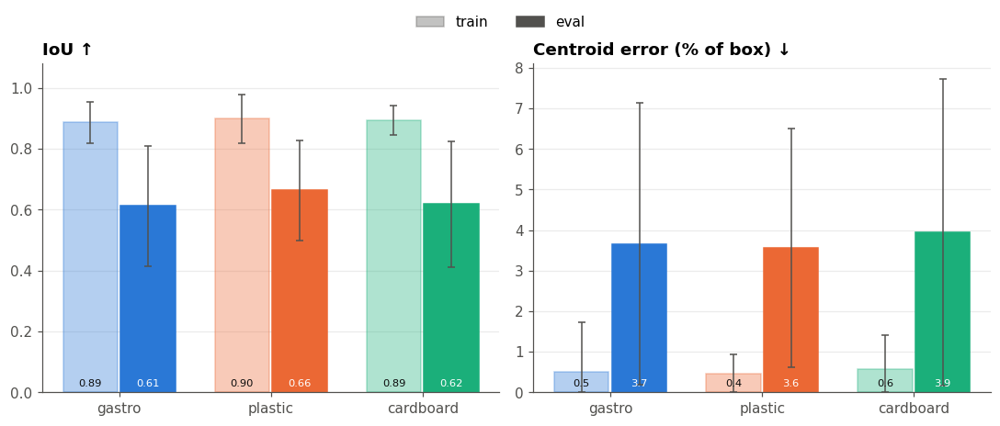

In [40]:
fig, axs = plt.subplots(1, len(FIG_METRICS), figsize=(10, 4))
for ax, metric in zip(axs, FIG_METRICS):
    train_eval_bars(ax, [d[d.box == b] for b in BOXES], BOXES, [COLORS[b] for b in BOXES], metric)
    ax.set_title(METRICS[metric], loc='left', fontweight='bold')
fig.legend([Patch(color=MUTED, alpha=.35), Patch(color=MUTED)], ['train', 'eval'], frameon=False, ncols=2, loc='upper center', bbox_to_anchor=(.5, 1.06))
fig.tight_layout()
save_fig('fig_box_train_eval', 'In distribution, per box: train (light) vs eval (solid). Whiskers: ±1 std over samples.')
plt.show()
t = make_table(train_eval('box'), 'per-box', vlines=(2, 4), skip=('train',)).loc[list(BOXES)]
show(t, 'tab_box_train_eval', 'In distribution, per box: train vs eval, all speakers. Best eval box in bold.')

**Reading:**
- **Plastic is the best box**: eval IoU 0.670, against 0.621 for gastro and 0.616 for cardboard. Its centroid error is the lowest too (3.6% of the box, tied with gastro; cardboard 3.8%), and it has no misses.
- **Train is ≈0.90 in all three boxes** (plastic 0.92), so the boxes differ in how well the model generalizes to held-out positions, not in how well it fits.
- Gastro and cardboard are close together on every metric. Cardboard has the most misses (0.4%), still almost none.

### 13 Object-head confidence
Can the model tell it doesn't know the object? The broken cup only shows up once it is held out of training (paper split).

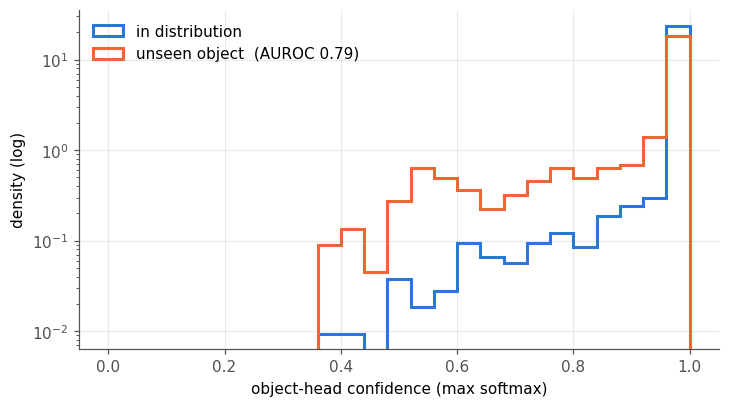

In [41]:
e = df[df.set == 'eval']
idc = e[e.category == 'id'].obj_conf.to_numpy()
fig, ax = plt.subplots(figsize=(7.5, 4))
for c, col in zip([c for c in ('id', 'broken', 'unseen-object') if c in set(e.category)], PALETTE):
    v = e[e.category == c].obj_conf.to_numpy()
    ax.hist(v, np.linspace(0, 1, 26), density=True, histtype='step', lw=2, color=col, label=NAMES[c] + ('' if c == 'id' else f'  (AUROC {auroc(1 - idc, 1 - v):.2f})'))
ax.set(xlabel='object-head confidence (max softmax)', ylabel='density (log)', yscale='log')
ax.legend(frameon=False, loc='upper left');
save_fig('fig_object_confidence', 'Object-head confidence: in distribution vs never-trained objects.')

### 14 Predictions per category
Speaker 1. Each row is picked at evenly spaced IoU quantiles (15–85%), not the best samples, and alternates between boxes. White = true outline, orange = prediction > THR. A lid sample's photo shows the lid; its outline is the same spot without the lid.

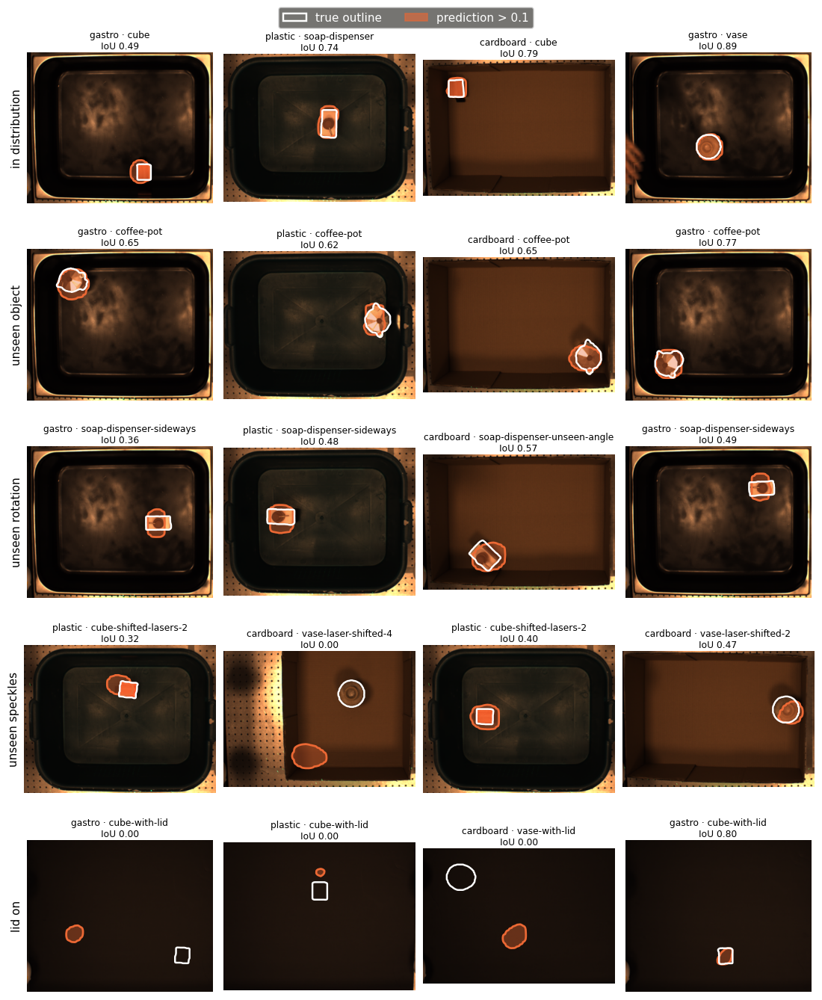

In [42]:
n, speaker, width = 4, 1, 320
e = df[(df.set == 'eval') & (df.speaker == speaker)]
cats = [c for c in ['id'] + OOD if c in set(e.category)]
fig, axs = plt.subplots(len(cats), n, figsize=(3.1 * n, 2.95 * len(cats)), squeeze=False, gridspec_kw=dict(wspace=.04, hspace=.3))
for row, c in zip(axs, cats):
    g = e[e.category == c]
    boxes = [b for b in BOXES if b in set(g.box)]
    for k, (ax, q) in enumerate(zip(row, np.linspace(.15, .85, n))):   # evenly spaced IoU quantiles, boxes taking turns
        h = g[g.box == boxes[k % len(boxes)]].sort_values('iou')
        r = h.iloc[min(int(q * len(h)), len(h) - 1)]
        sid, pos, spk = int(r.sample_id), int(r.position_id), int(r.speaker)
        im = Image.open(S.sample_dir(r.experiment, sid, pos, spk) / 'image/02_cropped_overhead.png').convert('RGB')
        W, H = width, round(width * im.height / im.width)
        p = np.asarray(Image.fromarray(torch.load(r.file, weights_only=False, map_location='cpu')['mask_pred'][int(r.idx)].float().numpy()).resize((W, H), Image.BILINEAR))
        y = np.asarray(Image.fromarray(S.truth(r.experiment, sid, pos, spk, 256, 256)).resize((W, H), Image.BILINEAR))
        ax.imshow(im.resize((W, H)))
        ax.imshow(np.where((p > THR)[..., None], [0.92, 0.41, 0.20, 0.38], 0))
        ax.contour(p, [THR], colors=['#eb6834'], linewidths=1.8)
        ax.contour(y, [0.5], colors=['white'], linewidths=1.6)
        ax.set_title(f'{r.box} · {r.split}\nIoU {r.iou:.2f}', fontsize=8, pad=3)
        ax.set(xticks=[], yticks=[]); ax.grid(False)
        for s in ax.spines.values(): s.set_visible(False)
    row[0].set_ylabel(NAMES[c], fontsize=10)
fig.legend(handles=[Patch(fc='none', ec='white', lw=1.6, label='true outline'), Patch(fc='#eb6834', alpha=.6, ec='#eb6834', label=f'prediction > {THR}')],
           loc='lower center', ncols=2, facecolor=MUTED, labelcolor='white', bbox_to_anchor=(.5, .9))
fig.subplots_adjust(top=.885)
save_fig('fig_predictions', 'Predictions per category at evenly spaced IoU quantiles (speaker 1).')

In [43]:
print('hi')

hi
